# **6BUIS017W CRM & CM with Business Intelligence: Coursework 1**

### **Market Analysis and Stock Segmentation using RFM**


In [1]:
!pip install -q yfinance scikit-learn matplotlib seaborn pandas numpy scipy

In [2]:
# Import all required libraries
import os
import sys
import datetime
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

pd.set_option('display.max_colwidth', None)   # show full exclusion reasons in tables


In [3]:
# Folders for the preserved data snapshots and outputs (pushed both to GitHub)
os.makedirs('data', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

In [4]:
# Analysis settings (all tunable choices kept in one place for reproducibility)
SEED = 42                  # random seed for K-means and the permutation test
N_INIT = 50                # K-means restarts per fit
K_RANGE = range(2, 9)      # candidate cluster counts (brief: 2 to 8)
K_MIN_SELECT = 3           # smallest k eligible for selection (a two-way split is a weak segmentation)
MIN_CLUSTER_SHARE = 0.05   # the smallest cluster must hold at least 5% of the shares
N_STABILITY_SEEDS = 10     # seeds used in the K-means stability check
N_PERMUTATIONS = 500       # random relabellings used as the "no structure" baseline in 3.2.3


In [5]:
# Package versions (required for reproducibility)
print('Python      :', sys.version.split()[0])
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('yfinance    :', yf.__version__)
print('scipy       :', scipy.__version__)
print('scikit-learn:', sklearn.__version__)
print('matplotlib  :', matplotlib.__version__)
print('seaborn     :', sns.__version__)

Python      : 3.13.18
pandas      : 2.2.3
numpy       : 2.4.6
yfinance    : 0.2.66
scipy       : 1.16.3
scikit-learn: 1.6.1
matplotlib  : 3.10.0
seaborn     : 0.13.2


# **Task 01 - Data Preparation and Feature Engineering**

# **1.1 Ticker Selection and Data Acquisition**

In [6]:
USE_CACHE = False

start = '2021-01-01'
end = '2025-01-01'          # end date is exclusive in yfinance

if not USE_CACHE:
    # Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
    # User-Agent is required to avoid HTTP 403 blocking from Wikipedia
    retrieval_date = datetime.date.today()
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
    sp500_df = table[0]
    sp500_df['Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
    sp500_df['Retrieval_Date'] = retrieval_date
    sp500_df.to_csv('data/sp500_tickers.csv', index=False)
else:
    sp500_df = pd.read_csv('data/sp500_tickers.csv')
    retrieval_date = sp500_df['Retrieval_Date'].iloc[0]

tickers = sp500_df['Ticker'].tolist()

print('Ticker list retrieval date:', retrieval_date)
print('Total tickers extracted   :', len(tickers))
print('Duplicate tickers         :', len(tickers) - len(set(tickers)))
sp500_df[['Symbol', 'Ticker', 'Security', 'GICS Sector']].head(10)

Ticker list retrieval date: 2026-11-24
Total tickers extracted   : 503
Duplicate tickers         : 0


,Symbol,Ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology
5,ADBE,ADBE,Adobe Inc.,Information Technology
6,AMD,AMD,Advanced Micro Devices,Information Technology
7,AES,AES,AES Corporation,Utilities
8,AFL,AFL,Aflac,Financials
9,A,A,Agilent Technologies,Health Care


In [7]:
#Part 2: Load daily market data via yfinance (shares + ^GSPC benchmark)

if not USE_CACHE:
    raw = yf.download(tickers, start=start, end=end, auto_adjust=False, actions=True)
    adj_close = raw['Adj Close']
    close = raw['Close']
    volume = raw['Volume']
    # Corporate actions (used for the systematic split/dividend checks in 1.2)
    fields = raw.columns.get_level_values(0)
    dividends = raw['Dividends'] if 'Dividends' in fields else pd.DataFrame(0.0, index=raw.index, columns=adj_close.columns)
    splits = raw['Stock Splits'] if 'Stock Splits' in fields else pd.DataFrame(0.0, index=raw.index, columns=adj_close.columns)

    market = yf.download('^GSPC', start=start, end=end, auto_adjust=False)
    market_adj = market['Adj Close'].squeeze().rename('^GSPC')
    market_close = market['Close'].squeeze().rename('^GSPC')     # used in the Adj Close vs Close check (3.2.3)

    # Preserve the raw snapshots so the analysis can be reproduced
    adj_close.to_csv('data/adj_close.csv')
    close.to_csv('data/close.csv')
    volume.to_csv('data/volume.csv')
    dividends.to_csv('data/dividends.csv')
    splits.to_csv('data/splits.csv')
    market_adj.to_csv('data/gspc_adj_close.csv')
    market_close.to_csv('data/gspc_close.csv')
else:
    adj_close = pd.read_csv('data/adj_close.csv', index_col=0, parse_dates=True)
    close = pd.read_csv('data/close.csv', index_col=0, parse_dates=True)
    volume = pd.read_csv('data/volume.csv', index_col=0, parse_dates=True)
    dividends = pd.read_csv('data/dividends.csv', index_col=0, parse_dates=True)
    splits = pd.read_csv('data/splits.csv', index_col=0, parse_dates=True)
    market_adj = pd.read_csv('data/gspc_adj_close.csv', index_col=0, parse_dates=True).squeeze()
    market_close = pd.read_csv('data/gspc_close.csv', index_col=0, parse_dates=True).squeeze()

print('Adj Close shape:', adj_close.shape)
print('Close shape    :', close.shape)
print('Volume shape   :', volume.shape)
print('^GSPC benchmark rows     :', len(market_adj))
print('First / last trading date:', adj_close.index.min().date(), '/', adj_close.index.max().date())


[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'HONA', 'FDXF', 'VYLR', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


Adj Close shape: (1005, 503)
Close shape    : (1005, 503)
Volume shape   : (1005, 503)
^GSPC benchmark rows     : 1005
First / last trading date: 2021-01-04 / 2024-12-31


**Data source choice and provenance**

- **Ticker list:** the current S&P 500 constituents table from Wikipedia, read with `pandas.read_html`. It has 503 tickers rather than 500 because some companies list two share classes (for example GOOGL/GOOG, FOX/FOXA, NWS/NWSA). Class-share symbols are converted to Yahoo's format (`.` → `-`, e.g. BRK.B → BRK-B).
- **Prices:** `yfinance` was chosen over YahooFinancials because it is actively maintained, downloads all tickers in one batched request, returns pandas DataFrames directly, and with `auto_adjust=False` returns both `Close` and `Adj Close` (plus `Volume`), which the brief requires.
- **Benchmark:** `^GSPC`, the S&P 500 price index, downloaded with the same settings and period.
- **Period:** 1 January 2021 to 1 January 2025, with the end date exclusive (yfinance convention), so the last session is 31 December 2024.
- **Failed downloads:** tickers that return no data are kept in the exclusion log ("No price data downloaded"). The cell below shows when each was added to the index.
- **Reproducibility:** raw snapshots are saved to `data/`; setting `USE_CACHE = True` reloads them instead of downloading. SHA-256 hashes of the snapshot files are recorded so a re-run can prove it used exactly the same data.


In [8]:
# 1.1 Provenance checks: symbol conversions, share classes, failed downloads, period, snapshot hashes
import hashlib
import json

# (a) Symbols converted for Yahoo Finance
converted = sp500_df.loc[sp500_df['Symbol'] != sp500_df['Ticker'], ['Symbol', 'Ticker', 'Security']]
print('Symbols converted for Yahoo Finance:')
display(converted)

# (b) Companies listed with more than one share class (why there are more than 500 tickers)
if 'CIK' in sp500_df.columns:
    multi_class = sp500_df[sp500_df.duplicated('CIK', keep=False)].sort_values('CIK')
    print(f'Companies with more than one listed share class: {multi_class["CIK"].nunique()} '
          f'({len(multi_class)} tickers) -> {len(tickers)} tickers for {sp500_df["CIK"].nunique()} companies')
    display(multi_class[['Symbol', 'Security', 'CIK']])

# (c) Failed downloads and when those tickers joined the index
failed = [t for t in tickers if t not in adj_close.columns or adj_close[t].isna().all()]
print(f'Tickers with no price data in the study period: {len(failed)}')
display(sp500_df.loc[sp500_df['Ticker'].isin(failed), ['Ticker', 'Security', 'GICS Sector', 'Date added']])

# (d) Period and alignment checks on the raw download
assert adj_close.index.min() >= pd.Timestamp(start) and adj_close.index.max() < pd.Timestamp(end), 'share dates outside the study period'
assert market_adj.index.min() >= pd.Timestamp(start) and market_adj.index.max() < pd.Timestamp(end), '^GSPC dates outside the study period'
assert adj_close.index.equals(close.index) and adj_close.index.equals(volume.index), 'price/volume tables have different dates'
print('All dates inside [start, end): True')
print('Shares and ^GSPC have identical trading dates:', adj_close.index.equals(market_adj.index))


# (e) Retrieval metadata with SHA-256 hashes of every preserved snapshot
def sha256(file_path):
    h = hashlib.sha256()
    with open(file_path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


snapshot_files = ['data/sp500_tickers.csv', 'data/adj_close.csv', 'data/close.csv', 'data/volume.csv', 'data/dividends.csv', 'data/splits.csv',
                  'data/gspc_adj_close.csv', 'data/gspc_close.csv']
retrieval_metadata = {
    'ticker_source': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies',
    'ticker_retrieval_date': str(retrieval_date),
    'metadata_written_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    'loaded_from_cache': USE_CACHE,
    'price_source': f'yfinance {yf.__version__}',
    'auto_adjust': False,
    'benchmark': '^GSPC',
    'study_start': start,
    'study_end_exclusive': end,
    'tickers_listed': len(tickers),
    'failed_downloads': failed,
    'trading_sessions': len(adj_close),
    'first_trading_date': str(adj_close.index.min().date()),
    'last_trading_date': str(adj_close.index.max().date()),
    'snapshot_sha256': {f: sha256(f) for f in snapshot_files},
}
with open('outputs/retrieval_metadata.json', 'w') as f:
    json.dump(retrieval_metadata, f, indent=2)
print(json.dumps(retrieval_metadata, indent=2))


Symbols converted for Yahoo Finance:


,Symbol,Ticker,Security
60,BRK.B,BRK-B,Berkshire Hathaway
76,BF.B,BF-B,Brown–Forman


Companies with more than one listed share class: 3 (6 tickers) -> 503 tickers for 500 companies


,Symbol,Security,CIK
330,NWS,News Corp (Class B),1564708
329,NWSA,News Corp (Class A),1564708
19,GOOGL,Alphabet Inc. (Class A),1652044
20,GOOG,Alphabet Inc. (Class C),1652044
204,FOX,Fox Corporation (Class B),1754301
203,FOXA,Fox Corporation (Class A),1754301


Tickers with no price data in the study period: 5


,Ticker,Security,GICS Sector,Date added
192,FDXF,FedEx Freight,Industrials,2026-06-01
233,HONA,Honeywell Aerospace,Industrials,2026-06-29
379,Q,Qnity Electronics,Information Technology,2025-11-03
402,SNDK,Sandisk,Information Technology,2025-11-28
478,VYLR,Vylor,Consumer Staples,2026-10-01


All dates inside [start, end): True
Shares and ^GSPC have identical trading dates: True
{
  "ticker_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "ticker_retrieval_date": "2026-11-24",
  "metadata_written_utc": "2026-11-24T10:34:15+00:00",
  "loaded_from_cache": false,
  "price_source": "yfinance 0.2.66",
  "auto_adjust": false,
  "benchmark": "^GSPC",
  "study_start": "2021-01-01",
  "study_end_exclusive": "2025-01-01",
  "tickers_listed": 503,
  "failed_downloads": [
    "FDXF",
    "HONA",
    "Q",
    "SNDK",
    "VYLR"
  ],
  "trading_sessions": 1005,
  "first_trading_date": "2021-01-04",
  "last_trading_date": "2024-12-31",
  "snapshot_sha256": {
    "data/sp500_tickers.csv": "0b68d47f2e47afe9245518a838bc4ce26ffebd01dc92c1c1bb96bd28e2af020f",
    "data/adj_close.csv": "89628425cb42db1ac40c75576f1912a4b03a715852b53ee8ce3579eb5d200ce9",
    "data/close.csv": "db1cac6a046906b30db0421cb711795dd785f5b3120209d49e8fac17663cf56e",
    "data/volume.csv": "89d537d

**Survivorship bias in the ticker list**

The ticker list is the index membership **at the retrieval date**, but it is applied to 2021–2024. Two biases follow:

- **Missing leavers:** companies that were in the index during the study period but have since been removed (acquired, delisted, or dropped after falling in value) are absent from the data entirely.
- **Included joiners:** companies added after 1 January 2021 are included for the whole period, and they were often added *because* they had grown strongly.

Both push the sample towards stronger performers, so average returns are likely overstated. The cell below looks for Wikipedia's "Selected changes" table to count removals. At the retrieval date (24 Nov 2026) the page no longer contains that table, so removals cannot be counted from this source; this is itself a provenance limitation. Section 3.2.3 tests the other side of the bias: whether late additions have higher returns and betas.


In [9]:
# 1.1 Survivorship evidence: index changes since the study start (Wikipedia "Selected changes" table)
# The page layout changes over time, so search every table on the page for the one with Added and Removed columns
# instead of assuming its position.
def flatten_columns(df):
    """('Removed', 'Ticker') -> 'Removed Ticker'; duplicated header levels collapse to one name."""
    df = df.copy()
    df.columns = [' '.join(dict.fromkeys(str(x) for x in col)).strip() if isinstance(col, tuple) else str(col)
                  for col in df.columns]
    return df


def is_changes_table(df):
    names = ' '.join(df.columns).lower()
    return 'added' in names and 'removed' in names


changes = None
changes_file = 'data/sp500_changes.csv'
if not USE_CACHE:
    candidates = [flatten_columns(t) for t in table]
    print(f'Tables found on the Wikipedia page: {len(candidates)}')
    for n, t in enumerate(candidates):
        print(f'  table[{n}]: {t.shape[0]} rows | first columns: {list(t.columns)[:4]}')
    matches = [t for t in candidates if is_changes_table(t)]
    if matches:
        changes = matches[0]
        changes.to_csv(changes_file, index=False)
    elif os.path.exists(changes_file):
        os.remove(changes_file)          # never leave a stale or wrong snapshot behind
elif os.path.exists(changes_file):
    cached = pd.read_csv(changes_file)
    changes = cached if is_changes_table(cached) else None

if changes is None:
    survivorship_counts = None
    print('\nNo "Selected changes" table (Added/Removed columns) is available on the page at the retrieval date, '
          'so index removals cannot be counted here.\nSurvivorship bias is still evidenced in 3.2.3 '
          '(late additions vs established constituents), and the limitation is stated in the report.')
else:
    def find_col(*words):
        """First column whose name contains all the given words (case-insensitive)."""
        return next((col for col in changes.columns if all(w in col.lower() for w in words)), None)

    date_col, reason_col = find_col('date'), find_col('reason')
    added_col = find_col('added', 'ticker') or find_col('added', 'symbol') or find_col('added')
    removed_col = find_col('removed', 'ticker') or find_col('removed', 'symbol') or find_col('removed')
    removed_name_col = find_col('removed', 'security')
    assert date_col and added_col and removed_col, f'Unexpected changes-table layout: {list(changes.columns)}'

    changes['Change_Date'] = pd.to_datetime(changes[date_col], errors='coerce')

    def non_empty(s):
        return s.dropna().astype(str).str.strip().loc[lambda x: (x != '') & (x.str.lower() != 'nan')]

    since_start = changes[changes['Change_Date'] >= pd.Timestamp(start)]
    in_period = since_start[since_start['Change_Date'] < pd.Timestamp(end)]
    after_period = since_start[since_start['Change_Date'] >= pd.Timestamp(end)]

    survivorship_counts = pd.DataFrame({
        'Window': [f'Study period ({start} to {end}, exclusive)', f'After the study period (to {retrieval_date})',
                   f'Total since {start}'],
        'Removed_from_index': [len(non_empty(in_period[removed_col])), len(non_empty(after_period[removed_col])),
                               len(non_empty(since_start[removed_col]))],
        'Added_to_index': [len(non_empty(in_period[added_col])), len(non_empty(after_period[added_col])),
                           len(non_empty(since_start[added_col]))],
    })
    survivorship_counts.to_csv('outputs/sp500_changes_since_start.csv', index=False)
    display(survivorship_counts)

    removed_since_start = non_empty(since_start[removed_col])
    print(f'{len(removed_since_start)} removals since {start}: these companies traded during (part of) 2021-2024 '
          f'but are not in the current list, so they are missing from this analysis.')
    print('Removed tickers that are back in the current list:',
          sorted(set(removed_since_start) & set(sp500_df['Symbol'].astype(str))))
    show_cols = [col for col in ['Change_Date', removed_col, removed_name_col, reason_col] if col]
    display(since_start.loc[removed_since_start.index, show_cols].head(15))

Tables found on the Wikipedia page: 2
  table[0]: 503 rows | first columns: ['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry']
  table[1]: 11 rows | first columns: ['vteS&P 500 companies', 'vteS&P 500 companies.1']

No "Selected changes" table (Added/Removed columns) is available on the page at the retrieval date, so index removals cannot be counted here.
Survivorship bias is still evidenced in 3.2.3 (late additions vs established constituents), and the limitation is stated in the report.


# **1.2 Data Validation and Alignment**

In [10]:
# 1. Duplicate dates
print('Duplicate dates (shares):', adj_close.index.duplicated().sum())
print('Duplicate dates (^GSPC) :', market_adj.index.duplicated().sum())
adj_close = adj_close[~adj_close.index.duplicated(keep='first')]
close = close[~close.index.duplicated(keep='first')]
volume = volume[~volume.index.duplicated(keep='first')]
market_adj = market_adj[~market_adj.index.duplicated(keep='first')]
market_close = market_close[~market_close.index.duplicated(keep='first')]
dividends = dividends[~dividends.index.duplicated(keep='first')]
splits = splits[~splits.index.duplicated(keep='first')]

# 2. Align shares and benchmark on identical trading dates
common_dates = adj_close.index.intersection(market_adj.index)
print('Share dates not in ^GSPC:', len(adj_close.index.difference(market_adj.index)))
print('^GSPC dates not in shares:', len(market_adj.index.difference(adj_close.index)))
adj_close = adj_close.loc[common_dates]
close = close.loc[common_dates]
volume = volume.loc[common_dates]
market_adj = market_adj.loc[common_dates]
market_close = market_close.loc[common_dates]
dividends = dividends.reindex(common_dates)
splits = splits.reindex(common_dates)
print('Common trading dates:', len(common_dates))

# 3. Benchmark checks
print('^GSPC missing values:', market_adj.isna().sum(), '| non-positive:', (market_adj <= 0).sum())


Duplicate dates (shares): 0
Duplicate dates (^GSPC) : 0
Share dates not in ^GSPC: 0
^GSPC dates not in shares: 0
Common trading dates: 1005
^GSPC missing values: 0 | non-positive: 0


**Validation and handling rules**

Each share is tested in this order, and the first rule it fails is recorded in the exclusion log:

1. **No price data:** the ticker returned nothing for 2021–2024 (typically a recent listing or spin-off).
2. **Missing values / unequal history:** any missing Adj Close, Close or Volume. The reason records the first available price date, which separates **late listings** from **gaps** in an otherwise full history.
3. **Non-positive prices:** any Adj Close or Close ≤ 0.
4. **Volume errors:** any day with zero or negative volume, treated as an unreliable record (for example a price history that starts before the share actually traded).

**Why exclude rather than fill:** missing prices are **never forward-filled or interpolated**, because a filled price is an invented observation that creates artificial zero returns. Shares with unequal histories are excluded so that every mean weekly return and beta is estimated on **the same 207 weeks against the same benchmark weeks**, which keeps the features comparable across shares. A full history also guarantees the complete 20-session volume baseline that the RFM event rule needs. The cost is a smaller sample (486 of 503) and some survivorship bias towards long-established constituents (see 1.1).


In [11]:
# 4. Share-level validation rules -> inclusion / exclusion log
exclusion_log = []
valid_tickers = []

for ticker in tickers:
    if ticker not in adj_close.columns or adj_close[ticker].isna().all():
        exclusion_log.append({'Ticker': ticker, 'Stage': '1.2 Validation',
                              'Reason': 'No price data downloaded'})
        continue

    missing = int(adj_close[ticker].isna().sum() + close[ticker].isna().sum()
                  + volume[ticker].isna().sum())
    if missing > 0:
        first_date = adj_close[ticker].first_valid_index().date()
        exclusion_log.append({'Ticker': ticker, 'Stage': '1.2 Validation',
                              'Reason': f'Unequal/incomplete history: {missing} missing values '
                                        f'(first price {first_date})'})
        continue

    if (adj_close[ticker] <= 0).any() or (close[ticker] <= 0).any():
        exclusion_log.append({'Ticker': ticker, 'Stage': '1.2 Validation',
                              'Reason': 'Non-positive price'})
        continue

    bad_volume = int((volume[ticker] <= 0).sum())
    if bad_volume > 0:
        exclusion_log.append({'Ticker': ticker, 'Stage': '1.2 Validation',
                              'Reason': f'Zero/negative volume on {bad_volume} days'})
        continue

    valid_tickers.append(ticker)

exclusion_df = pd.DataFrame(exclusion_log, columns=['Ticker', 'Stage', 'Reason'])
print('Tickers retained:', len(valid_tickers))
print('Tickers excluded:', len(exclusion_df))
exclusion_df

Tickers retained: 486
Tickers excluded: 17


,Ticker,Stage,Reason
0,APP,1.2 Validation,Unequal/incomplete history: 210 missing values (first price 2021-04-15)
1,COIN,1.2 Validation,Unequal/incomplete history: 207 missing values (first price 2021-04-14)
2,CEG,1.2 Validation,Unequal/incomplete history: 789 missing values (first price 2022-01-19)
3,EXE,1.2 Validation,Unequal/incomplete history: 78 missing values (first price 2021-02-10)
4,FDXF,1.2 Validation,No price data downloaded
5,FERG,1.2 Validation,Zero/negative volume on 27 days
6,GEHC,1.2 Validation,Unequal/incomplete history: 1476 missing values (first price 2022-12-15)
7,GEV,1.2 Validation,Unequal/incomplete history: 2436 missing values (first price 2024-03-27)
8,HONA,1.2 Validation,No price data downloaded
9,Q,1.2 Validation,No price data downloaded


In [89]:
# Keep only the validated shares
adj_v = adj_close[valid_tickers]
close_v = close[valid_tickers]
volume_v = volume[valid_tickers]
df1 = adj_v.T

print('df1 (tickers x dates):', df1.shape)
print('Any missing values left:', adj_v.isna().any().any(), close_v.isna().any().any(), volume_v.isna().any().any())

df1 (tickers x dates): (486, 1005)
Any missing values left: False False False


**Corporate Action Checks**
(Checking if splits and dividends are handled correctly)

In [13]:
# (a) Large daily Close moves
close_change = close_v.pct_change(fill_method=None)
big_moves = close_change.abs().stack()
big_moves = big_moves[big_moves > 0.40].rename('Close_daily_change').reset_index()
big_moves.columns = ['Date', 'Ticker', 'Close_daily_change']
print('Daily Close moves > 40%:', len(big_moves))
display(big_moves)

# (b) Jumps in Adj Close / Close ratio (dividend / spin-off adjustments)
ratio = adj_v / close_v
ratio_jump = ratio.pct_change(fill_method=None).abs().stack()
ratio_jump = ratio_jump[ratio_jump > 0.05].rename('Ratio_change').reset_index()
ratio_jump.columns = ['Date', 'Ticker', 'Ratio_change']
print('Adj/Close ratio jumps > 5%:', len(ratio_jump))
display(ratio_jump)

# (c) Known split: NVDA 10-for-1 on 10 June 2024
if 'NVDA' in valid_tickers:
    display(pd.DataFrame({'Close': close_v.loc['2024-06-04':'2024-06-14', 'NVDA'],
                          'Adj Close': adj_v.loc['2024-06-04':'2024-06-14', 'NVDA'],
                          'Volume': volume_v.loc['2024-06-04':'2024-06-14', 'NVDA']}))

Daily Close moves > 40%: 8


,Date,Ticker,Close_daily_change
0,2022-08-05,CVNA,0.400716
1,2022-12-07,CVNA,0.429210
2,2023-01-12,CVNA,0.460000
3,2023-06-08,CVNA,0.560206
4,2023-07-19,CVNA,0.402010
5,2024-04-11,GL,0.531402
6,2024-07-26,DXCM,0.406583
7,2024-11-15,BE,0.591867


Adj/Close ratio jumps > 5%: 4


,Date,Ticker,Ratio_change
0,2022-06-03,LYB,0.058699
1,2023-02-10,F,0.063042
2,2024-10-04,TDG,0.055800
3,2024-11-18,ACGL,0.051637


,Close,Adj Close,Volume
Date,,,
2024-06-04,116.436996,116.105927,403324000
2024-06-05,122.440002,122.091881,528402000
2024-06-06,120.998001,120.653969,664696000
2024-06-07,120.888000,120.544281,412386000
2024-06-10,121.790001,121.443710,313434100
2024-06-11,120.910004,120.576126,222551200
2024-06-12,125.199997,124.854271,299595000
2024-06-13,129.610001,129.252090,260704500
2024-06-14,131.880005,131.515823,309320400


**Systematic corporate-action checks (all retained shares)**

The checks above look for anomalies; this cell tests every retained share against the downloaded **Dividends** and **Stock Splits** records:

1. **Splits:** if `Close` is split-adjusted, it should not jump around a split date.
2. **Dividend adjustment:** `Adj Close` and `Close` returns should differ only on or next to a dividend/split date.
3. **Large moves:** a large move with no corporate action nearby, and identical Close and Adj Close returns, is a genuine market move and is kept.
4. **Adj/Close ratio jumps:** these should line up with a (special) dividend.


In [14]:
# Systematic corporate-action checks on all retained shares
div_v = dividends.reindex(columns=valid_tickers).fillna(0)   # NaN in an action table = no event that day (not a price)
split_v = splits.reindex(columns=valid_tickers).fillna(0)
close_ret = close_v.pct_change(fill_method=None)
adj_ret = adj_v.pct_change(fill_method=None)

# 1. Every split: the largest |daily Close move| within +-5 days should be small if Close is split-adjusted
split_rows = []
for ticker in valid_tickers:
    for d in split_v.index[split_v[ticker] > 0]:
        window = close_ret.loc[d - pd.Timedelta(days=5): d + pd.Timedelta(days=5), ticker]
        split_rows.append({'Ticker': ticker, 'Split_date': d.date(), 'Split_ratio': split_v.loc[d, ticker],
                           'Max_abs_Close_move_pm5d': window.abs().max()})
split_check = pd.DataFrame(split_rows, columns=['Ticker', 'Split_date', 'Split_ratio', 'Max_abs_Close_move_pm5d'])
split_check['Close_split_adjusted'] = split_check['Max_abs_Close_move_pm5d'] < 0.40
split_check.to_csv('outputs/corporate_actions_split_check.csv', index=False)
print(f"(1) Splits in the study period: {len(split_check)} across {split_check['Ticker'].nunique()} shares"
      f" | Close split-adjusted for all: {bool(split_check['Close_split_adjusted'].all())}")
display(split_check.round(4))

# 2. Adj Close vs Close returns should only differ around dividend/split dates (+-1 session allowed)
event = (div_v > 0) | (split_v > 0)
near_event = event | event.shift(1, fill_value=False) | event.shift(-1, fill_value=False)
unexplained = ((adj_ret - close_ret).abs() > 0.01) & ~near_event
unexplained_by_share = unexplained.sum()
unexplained_by_share[unexplained_by_share > 0].rename('Unexplained_days').to_csv('outputs/corporate_actions_unexplained.csv')
print(f"\n(2) Days where Adj Close and Close returns differ by > 1% away from any dividend/split: "
      f"{int(unexplained_by_share.sum())} (in {int((unexplained_by_share > 0).sum())} of {len(valid_tickers)} shares)")
if unexplained_by_share.sum() > 0:
    display(unexplained_by_share[unexplained_by_share > 0].rename('Unexplained_days'))


# 3. Large Close moves (> 40%): genuine market moves or adjustment errors?
def action_nearby(ticker, d, days=5):
    w = slice(d - pd.Timedelta(days=days), d + pd.Timedelta(days=days))
    return bool((div_v.loc[w, ticker] > 0).any() or (split_v.loc[w, ticker] > 0).any())


big_moves['Close_return'] = [close_ret.loc[r.Date, r.Ticker] for r in big_moves.itertuples()]
big_moves['Adj_Close_return'] = [adj_ret.loc[r.Date, r.Ticker] for r in big_moves.itertuples()]
big_moves['Split_or_dividend_within_5d'] = [action_nearby(r.Ticker, r.Date) for r in big_moves.itertuples()]
big_moves['Assessment'] = np.where(
    (big_moves['Close_return'] - big_moves['Adj_Close_return']).abs() < 0.01,
    'Genuine price move (Close and Adj Close agree) - kept', 'CHECK: Close and Adj Close disagree')
big_moves.to_csv('outputs/corporate_actions_large_moves.csv', index=False)
print('\n(3) Large daily Close moves:')
display(big_moves.round(4))


# 4. Adj/Close ratio jumps: dividend paid on (or next to) that date
def dividend_near(ticker, d):
    pos = div_v.index.get_loc(d)
    return div_v[ticker].iloc[max(0, pos - 1): pos + 2].sum()


ratio_jump['Dividend_paid'] = [dividend_near(r.Ticker, r.Date) for r in ratio_jump.itertuples()]
ratio_jump['Close_previous_day'] = [close_v[r.Ticker].shift(1).loc[r.Date] for r in ratio_jump.itertuples()]
ratio_jump['Dividend_as_pct_of_price'] = ratio_jump['Dividend_paid'] / ratio_jump['Close_previous_day'] * 100
ratio_jump['Explained_by_dividend'] = ratio_jump['Dividend_paid'] > 0
ratio_jump.to_csv('outputs/corporate_actions_ratio_jumps.csv', index=False)
print('\n(4) Adj/Close ratio jumps > 5%:')
display(ratio_jump.round(4))

print('\nSummary: all splits adjusted =', bool(split_check['Close_split_adjusted'].all()),
      '| unexplained adjustment days =', int(unexplained_by_share.sum()),
      '| large moves that are genuine =', int(big_moves['Assessment'].str.startswith('Genuine').sum()), 'of', len(big_moves),
      '| ratio jumps explained by dividends =', int(ratio_jump['Explained_by_dividend'].sum()), 'of', len(ratio_jump))


(1) Splits in the study period: 61 across 53 shares | Close split-adjusted for all: True


,Ticker,Split_date,Split_ratio,Max_abs_Close_move_pm5d,Close_split_adjusted
0,MMM,2024-04-01,1.196,0.0601,True
1,GOOGL,2022-07-18,20.000,0.0563,True
2,GOOG,2022-07-18,20.000,0.0581,True
3,AMZN,2022-06-06,20.000,0.0560,True
4,APH,2021-03-05,2.000,0.0447,True
...,...,...,...,...,...
56,WRB,2022-03-24,1.500,0.0205,True
57,WRB,2024-07-11,1.500,0.0222,True
58,WMT,2024-02-26,3.000,0.0185,True
59,WSM,2024-07-09,2.000,0.0502,True



(2) Days where Adj Close and Close returns differ by > 1% away from any dividend/split: 0 (in 0 of 486 shares)

(3) Large daily Close moves:


,Date,Ticker,Close_daily_change,Close_return,Adj_Close_return,Split_or_dividend_within_5d,Assessment
0,2022-08-05,CVNA,0.4007,0.4007,0.4007,False,Genuine price move (Close and Adj Close agree) - kept
1,2022-12-07,CVNA,0.4292,-0.4292,-0.4292,False,Genuine price move (Close and Adj Close agree) - kept
2,2023-01-12,CVNA,0.4600,0.4600,0.4600,False,Genuine price move (Close and Adj Close agree) - kept
3,2023-06-08,CVNA,0.5602,0.5602,0.5602,False,Genuine price move (Close and Adj Close agree) - kept
4,2023-07-19,CVNA,0.4020,0.4020,0.4020,False,Genuine price move (Close and Adj Close agree) - kept
5,2024-04-11,GL,0.5314,-0.5314,-0.5314,False,Genuine price move (Close and Adj Close agree) - kept
6,2024-07-26,DXCM,0.4066,-0.4066,-0.4066,False,Genuine price move (Close and Adj Close agree) - kept
7,2024-11-15,BE,0.5919,0.5919,0.5919,False,Genuine price move (Close and Adj Close agree) - kept



(4) Adj/Close ratio jumps > 5%:


,Date,Ticker,Ratio_change,Dividend_paid,Close_previous_day,Dividend_as_pct_of_price,Explained_by_dividend
0,2022-06-03,LYB,0.0587,6.39,115.25,5.5445,True
1,2023-02-10,F,0.0630,0.80,13.49,5.9303,True
2,2024-10-04,TDG,0.0558,75.00,1419.09,5.2851,True
3,2024-11-18,ACGL,0.0516,5.00,101.83,4.9101,True



Summary: all splits adjusted = True | unexplained adjustment days = 0 | large moves that are genuine = 8 of 8 | ratio jumps explained by dividends = 4 of 4


# **1.3 Weekly Return and Weekly Beta**

**1.3.1 Mean Weekly Returns**

In [15]:
def calculate_weekly_returns(df1, shares=None, start=start, end=end):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()

    # Keep complete calendar weeks only: Monday of the week on/after the start date
    # and Friday label before the (exclusive) end date
    week_start = weekly_prices.index - pd.Timedelta(days=4)
    complete = (week_start >= pd.Timestamp(start)) & (weekly_prices.index < pd.Timestamp(end))
    weekly_prices = weekly_prices[complete]

    # The first complete week has no preceding week, so its return is dropped
    return weekly_prices.pct_change(fill_method=None).iloc[1:]

In [16]:
# All shares weekly returns
weekly_returns = calculate_weekly_returns(df1)

# Benchmark weekly returns on the same price basis (Adj Close) and the same function
market_weekly_returns = calculate_weekly_returns(market_adj.to_frame().T)['^GSPC']

print('Weekly return table:', weekly_returns.shape)
print('First / last week label:', weekly_returns.index.min().date(), '/', weekly_returns.index.max().date())
print('Share and benchmark week labels identical:', weekly_returns.index.equals(market_weekly_returns.index))
print('Missing weekly returns (shares):', weekly_returns.isna().sum().sum())
print('Missing weekly returns (^GSPC) :', market_weekly_returns.isna().sum())
weekly_returns

Weekly return table: (207, 486)
First / last week label: 2021-01-15 / 2024-12-27
Share and benchmark week labels identical: True
Missing weekly returns (shares): 0
Missing weekly returns (^GSPC) : 0


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.006421,0.011930,0.001240,0.042347,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006689,...,0.056338,0.014781,-0.022359,-0.025681,-0.012166,-0.036134,-0.004946,0.009249,0.007361,-0.038963
2021-01-22,0.021081,0.016364,0.013836,0.003077,0.004416,0.031348,0.051922,-0.018116,-0.001075,0.000951,...,-0.040000,-0.000726,0.058276,0.011485,-0.003079,-0.008695,0.004408,-0.000929,0.005559,0.012522
2021-01-29,0.039163,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026923,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052293,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104972,0.003560,0.060988,0.048033,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040509,0.103331,0.160067,0.175425,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609
2021-02-12,0.006494,0.006166,0.033863,-0.039455,0.015500,0.013655,0.066780,0.062174,0.032343,0.038968,...,0.033952,0.015676,0.065959,0.007351,-0.029950,0.009471,0.006033,0.173491,0.009319,0.046647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.039791,0.014297,0.008577,0.033795,0.010344,0.007381,-0.008457,0.000000,0.014325,0.030858,...,-0.018944,0.024173,-0.066331,0.033848,0.016959,0.001851,0.027131,0.024699,0.017057,-0.009663
2024-12-06,-0.003145,-0.025238,-0.026690,-0.036845,0.000911,0.071773,0.010278,0.000767,-0.058684,0.018917,...,-0.028537,0.001770,0.065723,-0.000106,-0.038864,-0.002998,-0.004629,0.005700,-0.036307,0.006904
2024-12-13,-0.023965,-0.001653,-0.019204,-0.016005,-0.011084,-0.157823,-0.084277,0.022988,-0.025999,-0.011239,...,-0.034256,-0.034659,0.027213,0.001696,-0.023229,-0.045660,-0.004578,-0.013999,-0.011941,0.009747


**Week construction and alignment checks**

- Daily **Adj Close** prices are resampled to **Friday-ending weeks (W-FRI)** using the **last available trading price** in each week. If Friday is a holiday (e.g. Good Friday), Thursday's close is used.
- **Complete calendar weeks only:** a week is kept if its Monday is on or after 1 January 2021 and its Friday label is before the exclusive end date (1 January 2025). The first kept week (4–8 January 2021) supplies the base price only, because it has no preceding week. The final partial week (30–31 December 2024, label 3 January 2025) is excluded.
- **Holiday-shortened weeks are retained**, because they are normal weeks with fewer sessions.
- Shares and ^GSPC use the **same function on the same price basis**, so their week labels are identical. No weeks are filled, and consecutive labels are exactly 7 days apart, so no return spans more than one week.
- The weekly returns are **recomputed independently** for all shares with a different method (grouping on weekly periods instead of `resample`).


In [17]:
# Week-construction checks: alignment, spacing, excluded and holiday-shortened weeks, independent recomputation
assert weekly_returns.index.equals(market_weekly_returns.index), 'share and benchmark week labels differ'
assert weekly_returns.notna().all().all() and market_weekly_returns.notna().all(), 'missing weekly returns'
assert (weekly_returns.index.dayofweek == 4).all(), 'week labels are not Fridays'
spacing = weekly_returns.index.to_series().diff().dropna()
assert (spacing == pd.Timedelta(days=7)).all(), 'gap between labels: a return would span more than one week'
print(f'{len(weekly_returns)} weekly returns | labels identical for shares and ^GSPC | all Fridays | '
      f'consecutive labels exactly 7 days apart: True')

# Trading sessions in each Friday-ending week of the daily data
week_period = adj_v.index.to_period('W-FRI')
sessions = adj_v.index.to_series().groupby(week_period).count()
sessions.index = sessions.index.end_time.normalize()
base_week = weekly_returns.index.min() - pd.Timedelta(days=7)
excluded_weeks = sessions[~sessions.index.isin(weekly_returns.index.union([base_week]))]
print(f'\nBase week {base_week.date()}: first price only (no preceding week, so no return).')
print('Weeks excluded as incomplete calendar weeks at the edges of the study period:')
display(excluded_weeks.rename('Trading_sessions').to_frame())

short_weeks = sessions[sessions.index.isin(weekly_returns.index) & (sessions < 5)]
print(f'Holiday-shortened weeks retained: {len(short_weeks)} (all other weeks have 5 sessions)')
display(short_weeks.rename('Trading_sessions').to_frame().T)

# Final available trading price: Good Friday 2 April 2021 (market closed) -> Thursday's close is used
gf = adj_v.loc['2021-03-29':'2021-04-02', 'AAPL']
display(gf.to_frame('AAPL Adj Close (daily)'))
print('Weekly price for week ending 2021-04-02:', round(adj_v['AAPL'].resample('W-FRI').last().loc['2021-04-02'], 6),
      '= last daily price of that week, on', gf.index[-1].date())

# Independent recomputation for ALL shares with a different method (groupby on weekly periods)
weekly_last = adj_v.groupby(week_period).last()
weekly_last.index = weekly_last.index.end_time.normalize()
manual_returns = (weekly_last / weekly_last.shift(1) - 1).reindex(weekly_returns.index)[weekly_returns.columns]
assert np.allclose(manual_returns.values, weekly_returns.values), 'independent weekly returns disagree'
print(f'\nIndependent recomputation for all {weekly_returns.shape[1]} shares: max |difference| = '
      f'{(manual_returns - weekly_returns).abs().max().max():.2e}')


207 weekly returns | labels identical for shares and ^GSPC | all Fridays | consecutive labels exactly 7 days apart: True

Base week 2021-01-08: first price only (no preceding week, so no return).
Weeks excluded as incomplete calendar weeks at the edges of the study period:


,Trading_sessions
Date,
2025-01-03,2


Holiday-shortened weeks retained: 37 (all other weeks have 5 sessions)


Date,2021-01-22,2021-02-19,2021-04-02,2021-06-04,2021-07-09,2021-09-10,2021-11-26,2021-12-24,2022-01-21,2022-02-25,...,2024-01-05,2024-01-19,2024-02-23,2024-03-29,2024-05-31,2024-06-21,2024-07-05,2024-09-06,2024-11-29,2024-12-27
Trading_sessions,4,4,4,4,4,4,4,4,4,4,...,4,4,4,4,4,4,4,4,4,4


,AAPL Adj Close (daily)
Date,
2021-03-29,117.933098
2021-03-30,116.485519
2021-03-31,118.671448
2021-04-01,119.497246


Weekly price for week ending 2021-04-02: 119.497246 = last daily price of that week, on 2021-04-01

Independent recomputation for all 486 shares: max |difference| = 0.00e+00


In [18]:
# Arithmetic mean weekly return (return feature for clustering) + observation counts
mean_weekly_return = weekly_returns.mean().rename('Mean_Weekly_Return')
weekly_obs = weekly_returns.count().rename('Weekly_Obs')

print(pd.concat([mean_weekly_return, weekly_obs], axis=1).describe())

# Independent check for one share: mean of its weekly returns recomputed from weekly prices
check_prices = adj_v['AAPL'].resample('W-FRI').last().loc[weekly_returns.index.min() - pd.Timedelta(days=7):weekly_returns.index.max()]
print('\nAAPL mean (function):', round(mean_weekly_return['AAPL'], 6),
      '| manual:', round((check_prices / check_prices.shift(1) - 1).dropna().mean(), 6))

       Mean_Weekly_Return  Weekly_Obs
count          486.000000       486.0
mean             0.002857       207.0
std              0.002652         0.0
min             -0.004468       207.0
25%              0.001182       207.0
50%              0.002619       207.0
75%              0.004207       207.0
max              0.017772       207.0

AAPL mean (function): 0.00393 | manual: 0.00393


**Interpreting the mean weekly return and its limitations**

The feature is the **arithmetic mean** of 207 weekly returns: the average week-to-week change in the adjusted price, including dividends, because Adj Close is a total-return price. Its limitations:

- **It overstates compound growth.** The geometric mean (the constant weekly rate that gives the same final value) is lower by roughly σ²/2 per week ("volatility drag"), so volatile shares look better on the arithmetic mean than their realised growth.
- **It is estimated with a lot of noise.** Its standard error is σ/√207, which is large relative to the mean itself, so most shares' mean returns are not statistically different from zero, and small differences between shares are not meaningful.
- **It depends on the period.** 2021–2024 includes the 2022 bear market and the 2023–24 rally led by large technology shares. A different window would give different means.
- **It is sensitive to extreme weeks**, and it is biased upward by survivorship (see 1.1).
- **Benchmark basis:** ^GSPC is a price index without dividends, so share returns (which include dividends) are slightly higher than the index on a like-for-like basis. This hardly affects beta (see 3.2.3).


In [19]:
# Mean weekly return: independent check, precision and limitations
assert np.allclose(manual_returns.mean().values, mean_weekly_return.values), 'independent mean check failed'
print('Independent check: mean of independently recomputed weekly returns equals Mean_Weekly_Return for all shares: True')

n_weeks = weekly_returns.count()
weekly_sd = weekly_returns.std()
se_mean = weekly_sd / np.sqrt(n_weeks)
return_stats = pd.DataFrame({
    'Arithmetic_mean': mean_weekly_return,
    'Geometric_mean': (1 + weekly_returns).prod() ** (1 / n_weeks) - 1,
    'Volatility_drag_approx': weekly_sd ** 2 / 2,
    'Weekly_SD': weekly_sd,
    'SE_of_mean': se_mean,
    't_stat': mean_weekly_return / se_mean,
    'CI95_low': mean_weekly_return - 1.96 * se_mean,
    'CI95_high': mean_weekly_return + 1.96 * se_mean,
    'Annualised_arithmetic_approx': mean_weekly_return * 52,
    'Weeks': n_weeks,
})
return_stats.to_csv('outputs/mean_return_diagnostics.csv')

significant = return_stats['t_stat'].abs() > 1.96
print(f"Median arithmetic mean : {return_stats['Arithmetic_mean'].median():.3%} per week")
print(f"Median geometric mean  : {return_stats['Geometric_mean'].median():.3%} per week")
print(f"Median volatility drag : {return_stats['Volatility_drag_approx'].median():.3%} per week "
      f"(arithmetic - geometric, median {(return_stats['Arithmetic_mean'] - return_stats['Geometric_mean']).median():.3%})")
print(f"Median standard error  : {return_stats['SE_of_mean'].median():.3%} per week | "
      f"median 95% CI width {(return_stats['CI95_high'] - return_stats['CI95_low']).median():.3%}")
print(f"Shares whose mean weekly return differs significantly from 0 (|t| > 1.96): {significant.sum()} of {len(return_stats)}")
display(return_stats.drop(columns='Weeks').describe().T[['mean', '50%', 'min', 'max']].round(5))


Independent check: mean of independently recomputed weekly returns equals Mean_Weekly_Return for all shares: True
Median arithmetic mean : 0.262% per week
Median geometric mean  : 0.183% per week
Median volatility drag : 0.075% per week (arithmetic - geometric, median 0.074%)
Median standard error  : 0.269% per week | median 95% CI width 1.056%
Shares whose mean weekly return differs significantly from 0 (|t| > 1.96): 54 of 486


,mean,50%,min,max
Arithmetic_mean,0.00286,0.00262,-0.00447,0.01777
Geometric_mean,0.00187,0.00183,-0.00600,0.01135
Volatility_drag_approx,0.00100,0.00075,0.00023,0.01311
Weekly_SD,0.04222,0.03875,0.02137,0.16195
SE_of_mean,0.00293,0.00269,0.00149,0.01126
t_stat,1.00055,0.99269,-1.44266,3.20948
CI95_low,-0.00289,-0.00246,-0.01346,0.00433
CI95_high,0.00861,0.00786,0.00136,0.03391
Annualised_arithmetic_approx,0.14857,0.13618,-0.23234,0.92417


**1.3.2 Weekly Beta**

In [20]:
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [21]:
beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns)

print('Aligned weekly observations per share:', beta_df['Paired_weeks'].unique())
print(beta_df['Beta'].describe())

# Independent checks: numpy formula for AAPL, and beta of the benchmark on itself must be 1
aapl_check = np.cov(weekly_returns['AAPL'], market_weekly_returns, ddof=1)[0, 1] / np.var(market_weekly_returns, ddof=1)
print('\nAAPL beta (function):', round(beta_df.loc['AAPL', 'Beta'], 6), '| numpy check:', round(aapl_check, 6))
print('^GSPC beta on itself:', calculate_weekly_beta(market_weekly_returns.to_frame(), market_weekly_returns).iloc[0, 0])
beta_df.head()

Aligned weekly observations per share: [207]
count    486.000000
mean       0.973695
std        0.407339
min        0.055453
25%        0.666600
50%        0.950610
75%        1.179538
max        3.778560
Name: Beta, dtype: float64

AAPL beta (function): 1.174835 | numpy check: 1.174835
^GSPC beta on itself: 1.0


,Beta,Paired_weeks
Share,,
MMM,0.869079,207
AOS,1.042805,207
ABT,0.583543,207
ABBV,0.425366,207
ACN,1.143301,207


**Interpreting weekly beta and its estimation limits**

Beta measures **systematic (market) sensitivity**: a beta of 1.5 means the share has moved on average 1.5% for each 1% move in ^GSPC over 2021–2024, and a beta below 1 indicates a defensive share. Its limits:

- **Estimation error:** each beta comes from 207 weekly observations. Its standard error and 95% interval show how precisely it is known, and many betas are not distinguishable from 1.
- **R² (explained share of risk):** beta describes only the part of a share's return variation that moves with the market. When R² is low, most of the risk is idiosyncratic, and beta says little about the share's total risk.
- **Instability:** beta is not constant. Comparing 2021–22 with 2023–24 shows how much it moves between sub-periods.
- **Design choices:** weekly data reduces non-synchronous-trading noise compared with daily data but gives fewer observations. The benchmark is a price index, and the model is linear and treats all weeks equally, so extreme weeks have strong influence.


In [22]:
# Beta diagnostics: independent OLS check, precision, explained risk, stability, extremes
r, m = weekly_returns, market_weekly_returns
assert r.index.equals(m.index), 'share and benchmark weeks are not aligned'
beta = beta_df.loc[r.columns, 'Beta']

ols_slope = pd.Series({s: np.polyfit(m.values, r[s].values, 1)[0] for s in r.columns})
assert np.allclose(ols_slope.values, beta.values), 'beta disagrees with the OLS slope'
print(f'Independent check: OLS regression slope equals cov/var beta for all {len(beta)} shares: True')

n = len(m)
r2 = r.corrwith(m) ** 2
beta_se = np.sqrt((1 - r2) / (n - 2)) * r.std() / m.std()

half = n // 2
def period_beta(rr, mm):
    return rr.apply(lambda s: s.cov(mm)) / mm.var()

beta_first = period_beta(r.iloc[:half], m.iloc[:half])
beta_second = period_beta(r.iloc[half:], m.iloc[half:])

beta_diag = pd.DataFrame({
    'Sector': sp500_df.set_index('Ticker')['GICS Sector'].reindex(r.columns),
    'Beta': beta, 'SE': beta_se,
    'CI95_low': beta - 1.96 * beta_se, 'CI95_high': beta + 1.96 * beta_se,
    'R2': r2,
    'Beta_first_half': beta_first, 'Beta_second_half': beta_second,
})
beta_diag['Change_between_halves'] = beta_diag['Beta_second_half'] - beta_diag['Beta_first_half']
beta_diag.to_csv('outputs/beta_diagnostics.csv')

diff_from_1 = ((beta_diag['Beta'] - 1).abs() / beta_diag['SE']) > 1.96
print(f"\nPrecision : median SE {beta_diag['SE'].median():.3f} | median 95% CI width {(beta_diag['CI95_high'] - beta_diag['CI95_low']).median():.3f}")
print(f"Beta significantly different from 1: {diff_from_1.sum()} of {len(beta_diag)} "
      f"(above 1: {(diff_from_1 & (beta_diag['Beta'] > 1)).sum()}, below 1: {(diff_from_1 & (beta_diag['Beta'] < 1)).sum()})")
print(f"Explained risk: median R2 {beta_diag['R2'].median():.2f} | shares with R2 < 0.20: {(beta_diag['R2'] < 0.20).sum()}")
print(f"Stability : {r.index[0].date()} to {r.index[half - 1].date()} vs {r.index[half].date()} to {r.index[-1].date()} | "
      f"correlation of betas {beta_first.corr(beta_second):.2f} | median |change| {beta_diag['Change_between_halves'].abs().median():.3f}")

show = ['Sector', 'Beta', 'SE', 'R2', 'Beta_first_half', 'Beta_second_half']
print('\nHighest betas:'); display(beta_diag.nlargest(5, 'Beta')[show].round(3))
print('Lowest betas:');  display(beta_diag.nsmallest(5, 'Beta')[show].round(3))
print('Median beta and R2 by sector:')
display(beta_diag.groupby('Sector')[['Beta', 'R2']].median().sort_values('Beta').round(3))


Independent check: OLS regression slope equals cov/var beta for all 486 shares: True

Precision : median SE 0.101 | median 95% CI width 0.395
Beta significantly different from 1: 276 of 486 (above 1: 107, below 1: 169)
Explained risk: median R2 0.28 | shares with R2 < 0.20: 142
Stability : 2021-01-15 to 2022-12-30 vs 2023-01-06 to 2024-12-27 | correlation of betas 0.78 | median |change| 0.214

Highest betas:


,Sector,Beta,SE,R2,Beta_first_half,Beta_second_half
Ticker,,,,,,
CVNA,Consumer Discretionary,3.779,0.436,0.268,3.169,4.646
XYZ,Financials,2.505,0.189,0.462,2.565,2.350
COHR,Information Technology,2.139,0.202,0.353,1.457,3.476
NVDA,Information Technology,2.126,0.155,0.478,2.028,2.252
TWLO,Information Technology,2.073,0.217,0.308,2.206,1.700


Lowest betas:


,Sector,Beta,SE,R2,Beta_first_half,Beta_second_half
Ticker,,,,,,
GIS,Consumer Staples,0.055,0.082,0.002,0.203,-0.207
SJM,Consumer Staples,0.176,0.091,0.018,0.145,0.284
MRK,Health Care,0.198,0.092,0.022,0.192,0.245
BMY,Health Care,0.225,0.099,0.025,0.245,0.209
KHC,Consumer Staples,0.227,0.094,0.028,0.304,0.104


Median beta and R2 by sector:


,Beta,R2
Sector,,
Consumer Staples,0.469,0.128
Utilities,0.511,0.155
Energy,0.750,0.100
Health Care,0.759,0.183
Real Estate,0.881,0.335
Communication Services,0.887,0.195
Materials,0.935,0.263
Industrials,0.999,0.349
Financials,1.008,0.314


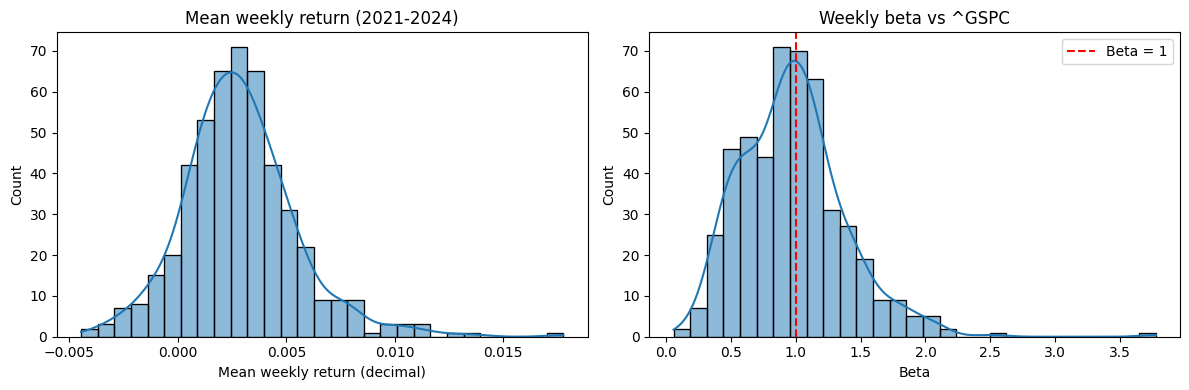

In [23]:
# Distributions of the two risk/return features
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(mean_weekly_return, kde=True, ax=ax[0])
ax[0].set_title('Mean weekly return (2021-2024)')
ax[0].set_xlabel('Mean weekly return (decimal)')
sns.histplot(beta_df['Beta'], kde=True, ax=ax[1])
ax[1].axvline(1, color='red', linestyle='--', label='Beta = 1')
ax[1].set_title('Weekly beta vs ^GSPC')
ax[1].legend()
plt.tight_layout()
plt.savefig('outputs/return_beta_distributions.png', dpi=150)
plt.show()

# **1.4 Adapted RFM Calculations**

**1.4.1 Recency | 1.4.2 Frequency | 1.4.3 Monetary**

**RFM definitions and rules**

- **Observation date:** the final common completed trading date in the study period (31 December 2024). Every retained share has Close and Volume on it.
- **High-volume event:** a day whose volume is **strictly greater** than 2 × the mean volume of the **preceding 20 sessions**. The tested day is excluded (`shift(1)`), and the threshold is recomputed for every share and every day. The first 20 sessions of each share have no complete baseline and are not testable. Only data up to the observation date is used, so there is **no look-ahead**.
- **Recency (R):** calendar days (weekends and holidays included) from the latest event in the valid history to the observation date. An event on the observation date gives R = 0. If a share has no event, R is recorded as **missing (not 0)** and the share is excluded from RFM clustering.
- **Frequency (F):** the number of event **days** in the latest 60 trading sessions ending on the observation date (not trades or shares traded).
- **Monetary (M):** the sum of daily **Close × Volume** over the same 60 sessions, an approximate traded value in USD. `Close` is used rather than `Adj Close` because it is the actual (split-adjusted) price at which trading happened. `Adj Close` also rescales past prices for later dividends. yfinance adjusts both Close and Volume for splits, so the product is consistent across a split.


In [24]:
# Observation date: final common completed trading date (all retained shares have data on it)
observation_date = close_v.index.max()
print('Observation date:', observation_date.date())
print('All shares have Close and Volume on it:',
      close_v.loc[observation_date].notna().all() and volume_v.loc[observation_date].notna().all())


def high_volume_flags(ticker, observation_date):
    """Daily table with the rolling 20-session baseline and high-volume flag for one share."""
    data = pd.DataFrame({'Close': close_v[ticker],
                         'Volume': volume_v[ticker]}).loc[:observation_date].copy()

    # Average of the previous 20 days, excluding the current day (Tutorial 03)
    data['Avg_Volume_20'] = data['Volume'].shift(1).rolling(20).mean()
    data['Threshold'] = 2 * data['Avg_Volume_20']
    data['High_Volume'] = data['Volume'] > data['Threshold']
    data['Traded_Value'] = data['Close'] * data['Volume']

    # Only consider days with a complete volume baseline
    return data.loc[data['Avg_Volume_20'].notna()]

Observation date: 2024-12-31
All shares have Close and Volume on it: True


In [25]:
results = []
event_flags = []

for ticker in valid_tickers:
    valid = high_volume_flags(ticker, observation_date)

    if len(valid) < 60:
        exclusion_log.append({'Ticker': ticker, 'Stage': '1.4 RFM',
                              'Reason': 'Insufficient history for 20-session baseline + 60-session window'})
        continue

    recent = valid.tail(60)
    high_volume_days = valid.loc[valid['High_Volume']]

    # Recency in calendar days at the observation date; no event -> missing (not zero)
    if not high_volume_days.empty:
        last_event = high_volume_days.index[-1]
        recency = (observation_date.date() - last_event.date()).days
    else:
        last_event, recency = pd.NaT, None

    results.append({
        'Ticker': ticker,
        'Observation_Date': observation_date.date(),
        'Last_Event_Date': last_event,
        'Recency': recency,
        'Frequency': int(recent['High_Volume'].sum()),
        'Monetary': recent['Traded_Value'].sum(),
        'Window_Start': recent.index[0].date(),
        'Window_End': recent.index[-1].date(),
        'Window_Sessions': len(recent)
    })

    # Keep the event flags of the 60-session window (reproducible evidence)
    event_flags.append(recent.assign(Ticker=ticker))

rfm_df = pd.DataFrame(results).set_index('Ticker')
rfm_df['Recency'] = rfm_df['Recency'].astype('Int64')
event_flags_df = pd.concat(event_flags).reset_index().rename(columns={'index': 'Date'})
event_flags_df.to_csv('outputs/rfm_event_flags_last60.csv', index=False)

print('Shares with RFM:', len(rfm_df))
rfm_df.head(10)

Shares with RFM: 486


,Observation_Date,Last_Event_Date,Recency,Frequency,Monetary,Window_Start,Window_End,Window_Sessions
Ticker,,,,,,,,
MMM,2024-12-31,2024-12-20,11,4,2.599146e+10,2024-10-07,2024-12-31,60
AOS,2024-12-31,2024-12-20,11,2,4.748980e+09,2024-10-07,2024-12-31,60
ABT,2024-12-31,2024-12-20,11,1,3.523027e+10,2024-10-07,2024-12-31,60
ABBV,2024-12-31,2024-12-20,11,3,6.837054e+10,2024-10-07,2024-12-31,60
ACN,2024-12-31,2024-12-20,11,2,5.199430e+10,2024-10-07,2024-12-31,60
ADBE,2024-12-31,2024-12-13,18,3,1.030403e+11,2024-10-07,2024-12-31,60
AMD,2024-12-31,2024-12-13,18,4,3.131659e+11,2024-10-07,2024-12-31,60
AES,2024-12-31,2024-11-07,54,3,1.119578e+10,2024-10-07,2024-12-31,60
AFL,2024-12-31,2024-12-20,11,2,1.328456e+10,2024-10-07,2024-12-31,60


In [26]:
# RFM validation checks
print('All windows end on the observation date:', (rfm_df['Window_End'] == observation_date.date()).all())
print('All windows have 60 sessions          :', (rfm_df['Window_Sessions'] == 60).all())
print('Frequency range                       :', rfm_df['Frequency'].min(), '-', rfm_df['Frequency'].max())
print('Recency = 0 (event on observation date):', (rfm_df['Recency'] == 0).sum())

# If F > 0 the latest event lies inside the window, so R cannot exceed the window length in days
window_days = (observation_date.date() - rfm_df['Window_Start'].iloc[0]).days
inconsistent = rfm_df[((rfm_df['Frequency'] > 0) & (rfm_df['Recency'] > window_days)).fillna(False)]
print('F>0 but R outside the window (should be 0):', len(inconsistent))

# No-event shares: recorded as missing and excluded from RFM clustering
no_event = rfm_df[rfm_df['Recency'].isna()]
print('Shares with no high-volume event:', len(no_event), list(no_event.index))
for ticker in no_event.index:
    exclusion_log.append({'Ticker': ticker, 'Stage': '1.4 RFM',
                          'Reason': 'No high-volume event in valid history (Recency missing)'})

All windows end on the observation date: True
All windows have 60 sessions          : True
Frequency range                       : 0 - 8
Recency = 0 (event on observation date): 0
F>0 but R outside the window (should be 0): 0
Shares with no high-volume event: 0 []


**RFM verification**

1. **Unit tests** reproduce the brief's own examples and the boundary cases, and confirm that the tested rule gives exactly the same flags as `high_volume_flags()` for every share.
2. **Independent recomputation** of R, F and M for all shares with different code paths, plus evidence of full baselines and no look-ahead.
3. **Reproducible evidence:** the last event behind each share's R, and every event day in the full history, saved to `outputs/`.


In [27]:
# Unit tests: the brief's examples and boundary cases
def event_rule(volume, window=20, multiple=2):
    """The same event rule as high_volume_flags(): volume > multiple x mean of the previous `window`
    sessions (current day excluded). Days without a complete baseline are not testable (False)."""
    baseline = volume.shift(1).rolling(window).mean()
    return (volume > multiple * baseline) & baseline.notna(), baseline


def recency_days(event_dates, obs_date):
    """Calendar days from the latest event to the observation date; missing if there is no event."""
    if len(event_dates) == 0:
        return pd.NA
    return (pd.Timestamp(obs_date) - pd.Timestamp(max(event_dates))).days


# Recency
assert recency_days([pd.Timestamp('2024-09-15')], '2024-09-20') == 5        # brief: 20 Sep vs 15 Sep -> 5
assert recency_days([pd.Timestamp('2024-09-20')], '2024-09-20') == 0        # event on the observation date -> 0
assert recency_days([pd.Timestamp('2024-09-13')], '2024-09-16') == 3        # Friday -> Monday: weekends counted
assert pd.isna(recency_days([], '2024-09-20'))                              # no event -> missing, not 0
assert recency_days([pd.Timestamp('2024-08-01'), pd.Timestamp('2024-09-10')], '2024-09-20') == 10   # latest event used

# Event threshold (brief: baseline 1M -> threshold 2M)
def last_day_flag(final_volume):
    v = pd.Series([1_000_000.0] * 20 + [final_volume], index=pd.bdate_range('2024-01-01', periods=21))
    flags, base = event_rule(v)
    assert base.iloc[-1] == 1_000_000 and flags.iloc[:20].sum() == 0 and base.iloc[:20].isna().all()
    return bool(flags.iloc[-1])

assert last_day_flag(2_500_000) is True     # 2.5M qualifies
assert last_day_flag(1_800_000) is False    # 1.8M does not
assert last_day_flag(2_000_000) is False    # exactly 2x does not ("greater than")
assert last_day_flag(2_000_001) is True     # just above 2x qualifies

# Frequency: seven qualifying days in the latest 60 sessions -> F = 7 (an older spike outside the window is not counted)
v = pd.Series(1_000_000.0, index=pd.bdate_range('2024-01-01', periods=80))
v.iloc[10] = 5_000_000                                  # within the first 20 sessions: no baseline -> not testable
v.iloc[[25, 30, 35, 40, 45, 50, 55]] = 5_000_000        # seven spikes inside the latest 60 sessions
flags, _ = event_rule(v)
assert int(flags.tail(60).sum()) == 7, 'F example failed'

# Monetary: $100 close x 2 million shares = $200 million traded value
assert 100.0 * 2_000_000 == 200_000_000

# The tested rule is exactly the rule used in high_volume_flags(), for every share
mismatches = []
for t in valid_tickers:
    hv = high_volume_flags(t, observation_date)
    f, _ = event_rule(volume_v[t].loc[:observation_date])
    if not f.loc[hv.index].equals(hv['High_Volume']):
        mismatches.append(t)
assert not mismatches, f'rule mismatch for {mismatches[:5]}'
print('All RFM unit tests passed (R = 5 / 0 / missing, weekends counted, 2.5M yes, 1.8M no, exactly 2x no, F = 7, $200M),')
print(f'and the tested rule matches high_volume_flags() for all {len(valid_tickers)} shares.')


All RFM unit tests passed (R = 5 / 0 / missing, weekends counted, 2.5M yes, 1.8M no, exactly 2x no, F = 7, $200M),
and the tested rule matches high_volume_flags() for all 486 shares.


In [28]:
# Independent recomputation of R, F and M for all shares + baseline / look-ahead evidence
vol_hist = volume_v.loc[:observation_date]
events_all, baseline_all = event_rule(vol_hist)              # full-history event matrix (dates x shares)
n_sessions = len(vol_hist)
window_idx = vol_hist.index[-60:]

# R: vectorised from the full-history event matrix
last_event_all = pd.Series({t: (events_all.index[events_all[t]].max() if events_all[t].any() else pd.NaT)
                            for t in vol_hist.columns})
R_check = (observation_date - pd.to_datetime(last_event_all)).dt.days
assert np.array_equal(R_check.reindex(rfm_df.index).fillna(-1).values,
                      rfm_df['Recency'].astype(float).fillna(-1).values), 'Recency mismatch'

# F: explicit loop over the previous 20 raw volumes (no pandas rolling)
vals = vol_hist.values
F_loop = pd.Series({t: sum(vals[i, j] > 2 * vals[i - 20:i, j].mean() for i in range(n_sessions - 60, n_sessions))
                    for j, t in enumerate(vol_hist.columns)})
assert (F_loop.reindex(rfm_df.index) == rfm_df['Frequency']).all(), 'Frequency mismatch'

# M: one vectorised sum over the same 60 sessions
M_check = (close_v * volume_v).loc[window_idx].sum()
assert np.allclose(M_check.reindex(rfm_df.index).values, rfm_df['Monetary'].values), 'Monetary mismatch'
print(f'Independent recomputation for all {len(rfm_df)} shares: R, F and M all match rfm_df.')

# Adequate history and no look-ahead
assert vol_hist.index.max() == observation_date
assert baseline_all.loc[window_idx].notna().all().all(), 'a window day lacks a full 20-session baseline'
assert rfm_df['Window_Start'].nunique() == 1 and rfm_df['Window_End'].nunique() == 1, 'windows differ between shares'
print(f'Window: {window_idx[0].date()} to {window_idx[-1].date()} (60 sessions, identical for every share)')
print(f'Every window day has a full 20-session baseline; the earliest session used by a window baseline is '
      f'{vol_hist.index[n_sessions - 80].date()}, the latest data used is the observation date {observation_date.date()}.')
first_day = window_idx[0]
print(f'Example (first window day {first_day.date()}, {vol_hist.columns[0]}): baseline uses '
      f'{vol_hist.index[n_sessions - 80].date()} to {vol_hist.index[n_sessions - 61].date()}, i.e. only earlier sessions.')

# Reproducible evidence: last event behind each R, and every event day in the full history
last_rows = []
for t, d in last_event_all.dropna().items():
    last_rows.append({'Ticker': t, 'Last_Event_Date': d.date(), 'Volume': vol_hist.at[d, t],
                      'Baseline_20': baseline_all.at[d, t], 'Threshold': 2 * baseline_all.at[d, t],
                      'Volume_to_baseline': vol_hist.at[d, t] / baseline_all.at[d, t], 'Recency': int(R_check[t])})
last_event_evidence = pd.DataFrame(last_rows).set_index('Ticker')
last_event_evidence.to_csv('outputs/rfm_last_event_evidence.csv')

rows, cols = np.nonzero(events_all.values)
event_days = pd.DataFrame({'Date': events_all.index[rows], 'Ticker': events_all.columns[cols],
                           'Volume': vals[rows, cols], 'Baseline_20': baseline_all.values[rows, cols]})
event_days['Threshold'] = 2 * event_days['Baseline_20']
event_days.to_csv('outputs/rfm_event_days_full_history.csv.gz', index=False)
print(f'\nSaved {len(last_event_evidence)} last-event records and {len(event_days):,} event days (full history).')
display(last_event_evidence.head())


Independent recomputation for all 486 shares: R, F and M all match rfm_df.
Window: 2024-10-07 to 2024-12-31 (60 sessions, identical for every share)
Every window day has a full 20-session baseline; the earliest session used by a window baseline is 2024-09-09, the latest data used is the observation date 2024-12-31.
Example (first window day 2024-10-07, MMM): baseline uses 2024-09-09 to 2024-10-04, i.e. only earlier sessions.

Saved 486 last-event records and 18,280 event days (full history).


,Last_Event_Date,Volume,Baseline_20,Threshold,Volume_to_baseline,Recency
Ticker,,,,,,
MMM,2024-12-20,8351300,3027540.0,6055080.0,2.758444,11
AOS,2024-12-20,2859700,945605.0,1891210.0,3.024201,11
ABT,2024-12-20,12311900,4859540.0,9719080.0,2.533553,11
ABBV,2024-12-20,18950900,6293830.0,12587660.0,3.011028,11
ACN,2024-12-20,7013100,2395940.0,4791880.0,2.927077,11


**Interpreting event timing (Recency and Frequency)**

The table and chart below show **when** the events happen. If many shares share the same last-event date, that date was a **market-wide** high-volume day rather than share-specific news. Typical examples are quarterly options/futures expiry combined with index rebalancing (the third Friday of December, 20 December 2024) and major macro events (the day after the US election, 6 November 2024). Check the dates printed below against these.

Implications:
- **R takes few distinct values** and mostly records the timing of market-wide spikes, so it separates shares less than its range suggests. The low-volume holiday sessions after 20 December produce few events, which is why the smallest R is several days rather than 0.
- **F is relative to each share's own baseline.** It measures how often trading becomes *abnormal*, not how much trading there is, so a very heavily traded share can still have F = 0. Market-wide days add to F for many shares at once.
- Both depend on the **60-session window** (Q4 2024: election, year-end, holidays). A different observation date would change them.


Distinct Recency values: 48 | min R = 4 | max R = 222


,Shares,Last_event_date,Weekday,Pct_of_shares
Recency,,,,
11,353,2024-12-20,Fri,72.6
36,17,2024-11-25,Mon,3.5
55,11,2024-11-06,Wed,2.3
60,6,2024-11-01,Fri,1.2
46,6,2024-11-15,Fri,1.2
27,5,2024-12-04,Wed,1.0
102,5,2024-09-20,Fri,1.0
26,5,2024-12-05,Thu,1.0
25,5,2024-12-06,Fri,1.0


Days in the 60-session window with the most shares flagged:


,Shares_flagged,Pct_of_shares
Date,,
2024-12-20,354,72.8
2024-11-06,156,32.1
2024-10-31,83,17.1
2024-11-25,76,15.6
2024-10-30,46,9.5
2024-11-15,42,8.6


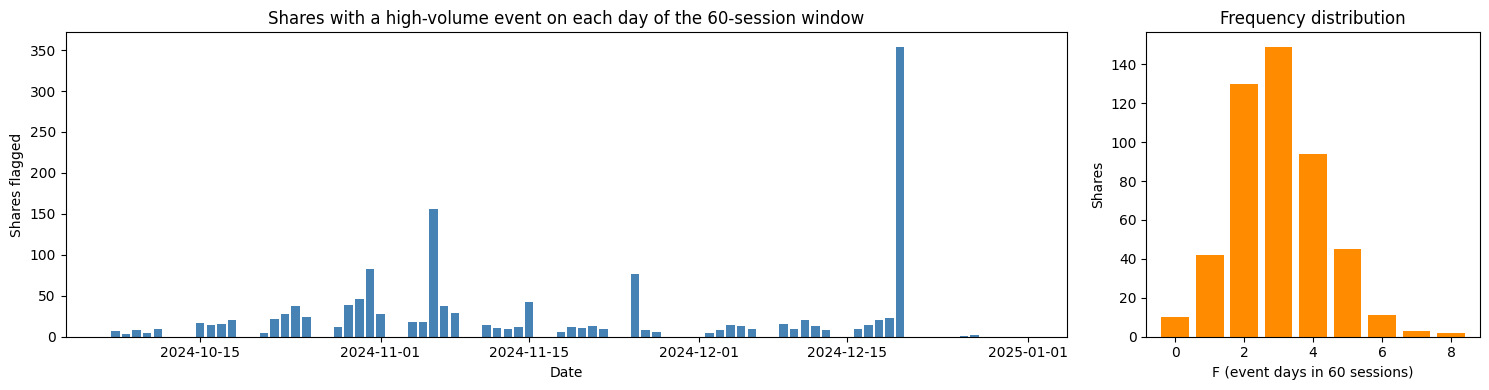

Shares with F = 0: 10 (largest traded values first)


,Recency,Frequency,Monetary
Ticker,,,
NVDA,222,0,1.825337e+12
MDT,102,0,3.015812e+10
FCX,96,0,2.847770e+10
CB,102,0,2.523472e+10
AZO,98,0,2.482392e+10
DUK,102,0,2.274797e+10
COR,102,0,1.759981e+10
WEC,151,0,1.081689e+10


In [29]:
# Event timing: which dates drive Recency, and how events cluster across the 60-session window
r_counts = rfm_df['Recency'].value_counts()
timing = pd.DataFrame({'Shares': r_counts})
timing.index.name = 'Recency'
timing['Last_event_date'] = [(observation_date - pd.Timedelta(days=int(r))).date() for r in timing.index]
timing['Weekday'] = [pd.Timestamp(d).strftime('%a') for d in timing['Last_event_date']]
timing['Pct_of_shares'] = (timing['Shares'] / len(rfm_df) * 100).round(1)
timing = timing.sort_values('Shares', ascending=False)
timing.to_csv('outputs/rfm_recency_timing.csv')
print(f'Distinct Recency values: {rfm_df["Recency"].nunique()} | min R = {rfm_df["Recency"].min()} | max R = {rfm_df["Recency"].max()}')
display(timing.head(10))

daily_events = events_all.loc[window_idx].sum(axis=1)
print('Days in the 60-session window with the most shares flagged:')
display(daily_events.sort_values(ascending=False).head(6).rename('Shares_flagged').to_frame()
        .assign(Pct_of_shares=lambda d: (d['Shares_flagged'] / vol_hist.shape[1] * 100).round(1)))

fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [3, 1]})
ax[0].bar(daily_events.index, daily_events.values, color='steelblue')
ax[0].set(title='Shares with a high-volume event on each day of the 60-session window',
          xlabel='Date', ylabel='Shares flagged')
f_counts = rfm_df['Frequency'].value_counts().sort_index()
ax[1].bar(f_counts.index, f_counts.values, color='darkorange')
ax[1].set(title='Frequency distribution', xlabel='F (event days in 60 sessions)', ylabel='Shares')
plt.tight_layout()
plt.savefig('outputs/rfm_event_timing.png', dpi=150)
plt.show()

no_freq = rfm_df[rfm_df['Frequency'] == 0].sort_values('Monetary', ascending=False)
print(f'Shares with F = 0: {len(no_freq)} (largest traded values first)')
display(no_freq[['Recency', 'Frequency', 'Monetary']].head(8))


**Monetary: what it measures and its limits**

- **Approximation:** Close × Volume values every share traded that day at the closing price. Trades happen at many prices during the day, so M only approximates dollar volume (a volume-weighted average price would be more accurate).
- **Liquidity proxy limits:** M measures *how much* was traded, not *how cheaply*. It ignores bid-ask spreads, order-book depth and price impact. It largely reflects **company size**, so a few mega-caps dominate (hence `log1p(M)` in Task 2). It also depends on the Q4 2024 window, and dual-class companies split their trading across two tickers.
- **Not market capitalisation:** market cap is price × shares *outstanding* (company value). M is price × shares *traded* over 60 sessions (trading activity). A large company can have modest M if its shares change hands rarely.
- **Not profit or net inflow:** every trade has both a buyer and a seller, so traded value is not money flowing *into* a share and says nothing about earnings.


In [30]:
# Monetary checks: split compatibility, price basis, extremes, concentration, dual-class shares
window_splits = split_v.loc[window_idx]
split_list = window_splits.stack()
split_list = split_list[split_list > 0]
print(f'Stock splits inside the 60-session window: {len(split_list)}')
if len(split_list):
    display(split_list.rename('Split_ratio').to_frame())
    for (d, t), ratio in split_list.items():
        around = pd.DataFrame({'Close': close_v[t], 'Volume': volume_v[t]}).loc[d - pd.Timedelta(days=4): d + pd.Timedelta(days=4)]
        around['Traded_value'] = around['Close'] * around['Volume']
        print(f'{t} around its {ratio}:1 split on {d.date()} (Close and Volume both split-adjusted -> traded value continuous):')
        display(around)

# Price basis: Close (actual traded price) vs Adj Close (rescaled for later dividends)
M_adj = (adj_v * volume_v).loc[window_idx].sum().reindex(rfm_df.index)
basis_ratio = M_adj / rfm_df['Monetary']
print(f'M on Adj Close / M on Close: median {basis_ratio.median():.4f}, min {basis_ratio.min():.4f} '
      f'(small here because the window is at the end of the data; older windows would be understated more by Adj Close)')

# Extremes and concentration
m_view = rfm_df[['Monetary']].join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector']])
m_view['Monetary_USD_bn'] = m_view['Monetary'] / 1e9
total_M = m_view['Monetary'].sum()
top10_share = m_view['Monetary'].nlargest(10).sum() / total_M
print(f'\nTotal M: ${total_M / 1e12:,.2f} trillion | top 10 shares = {top10_share:.1%} of all traded value | '
      f'median ${m_view["Monetary_USD_bn"].median():.1f}bn vs mean ${m_view["Monetary_USD_bn"].mean():.1f}bn')
print('Highest traded value:'); display(m_view.nlargest(5, 'Monetary')[['Security', 'GICS Sector', 'Monetary_USD_bn']].round(1))
print('Lowest traded value:');  display(m_view.nsmallest(5, 'Monetary')[['Security', 'GICS Sector', 'Monetary_USD_bn']].round(2))

# Dual-class companies: trading split across two tickers
if 'CIK' in sp500_df.columns:
    dual = sp500_df[sp500_df.duplicated('CIK', keep=False) & sp500_df['Ticker'].isin(rfm_df.index)]
    dual_m = dual[['Ticker', 'Security', 'CIK']].set_index('Ticker').join(m_view['Monetary_USD_bn']).sort_values('CIK')
    print('Dual-class companies (each ticker has its own M):'); display(dual_m.round(1))
m_view.to_csv('outputs/monetary_checks.csv')


Stock splits inside the 60-session window: 4


,,Split_ratio
Date,Ticker,
2024-12-04,ANET,4.0
2024-12-13,ETR,2.0
2024-12-16,PANW,2.0
2024-12-20,TSCO,5.0


ANET around its 4.0:1 split on 2024-12-04 (Close and Volume both split-adjusted -> traded value continuous):


,Close,Volume,Traded_value
Date,,,
2024-12-02,102.525002,5328000,5.462532e+08
2024-12-03,103.614998,7181200,7.440800e+08
2024-12-04,105.430000,5845900,6.163332e+08
2024-12-05,106.830002,6967000,7.442846e+08
2024-12-06,108.250000,10017900,1.084438e+09


ETR around its 2.0:1 split on 2024-12-13 (Close and Volume both split-adjusted -> traded value continuous):


,Close,Volume,Traded_value
Date,,,
2024-12-09,74.779999,2343800,1.752694e+08
2024-12-10,74.165001,3279400,2.432167e+08
2024-12-11,73.940002,2424200,1.792454e+08
2024-12-12,74.135002,3252000,2.410870e+08
2024-12-13,74.239998,3294500,2.445837e+08
2024-12-16,74.760002,3607900,2.697266e+08
2024-12-17,74.839996,3754800,2.810092e+08


... (6 outputs left out)

Lowest traded value:


,Security,GICS Sector,Monetary_USD_bn
Ticker,,,
NWS,News Corp (Class B),Communication Services,1.30
ECHO,EchoStar,Communication Services,2.35
FOX,Fox Corporation (Class B),Communication Services,2.71
IVZ,Invesco,Financials,3.69
L,Loews Corporation,Financials,3.71


Dual-class companies (each ticker has its own M):


,Security,CIK,Monetary_USD_bn
Ticker,,,
NWS,News Corp (Class B),1564708,1.3
NWSA,News Corp (Class A),1564708,4.1
GOOGL,Alphabet Inc. (Class A),1652044,294.4
GOOG,Alphabet Inc. (Class C),1652044,202.8
FOX,Fox Corporation (Class B),1754301,2.7
FOXA,Fox Corporation (Class A),1754301,9.4


# **1.5 Feature Table, Summaries and Inclusion/Exclusion Log**

In [31]:
#Worked RFM example for one share
example = 'AAPL'
ex = high_volume_flags(example, observation_date)
ex_recent = ex.tail(60)
ex_events = ex.loc[ex['High_Volume']]
last_event = ex_events.index[-1]

# Manual threshold check: mean of the 20 sessions BEFORE the event day
pos = volume_v.index.get_loc(last_event)
manual_avg = volume_v[example].iloc[pos - 20:pos].mean()

print(f'Share: {example} | Observation date: {observation_date.date()}')
print(f'Latest high-volume day: {last_event.date()}')
print(f'  Volume on that day           : {ex.loc[last_event, "Volume"]:,.0f}')
print(f'  Preceding 20-session mean    : {ex.loc[last_event, "Avg_Volume_20"]:,.0f} (manual: {manual_avg:,.0f})')
print(f'  Threshold (2 x mean)         : {ex.loc[last_event, "Threshold"]:,.0f}')
print(f'R = {observation_date.date()} - {last_event.date()} = {(observation_date - last_event).days} calendar days')
print(f'F = high-volume days in last 60 sessions ({ex_recent.index[0].date()} to {ex_recent.index[-1].date()}) = {int(ex_recent["High_Volume"].sum())}')
print(f'M = sum of Close x Volume over those 60 sessions = ${ex_recent["Traded_Value"].sum():,.0f}')
print('\nHigh-volume days inside the 60-session window:')
display(ex_recent[ex_recent['High_Volume']][['Close', 'Volume', 'Avg_Volume_20', 'Threshold', 'High_Volume', 'Traded_Value']])
print('First 5 sessions of the M calculation:')
display(ex_recent[['Close', 'Volume', 'Traded_Value']].head())

Share: AAPL | Observation date: 2024-12-31
Latest high-volume day: 2024-12-20
  Volume on that day           : 147,495,300
  Preceding 20-session mean    : 45,004,605 (manual: 45,004,605)
  Threshold (2 x mean)         : 90,009,210
R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = high-volume days in last 60 sessions (2024-10-07 to 2024-12-31) = 2
M = sum of Close x Volume over those 60 sessions = $623,303,377,707

High-volume days inside the 60-session window:


,Close,Volume,Avg_Volume_20,Threshold,High_Volume,Traded_Value
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


First 5 sessions of the M calculation:


,Close,Volume,Traded_Value
Date,,,
2024-10-07,221.690002,39505400,8.757952e+09
2024-10-08,225.770004,31855700,7.192062e+09
2024-10-09,229.539993,33591100,7.710501e+09
2024-10-10,229.039993,28183500,6.455149e+09
2024-10-11,227.550003,31759200,7.226806e+09


In [32]:
sector = sp500_df.set_index('Ticker')[['Security', 'GICS Sector']]

feature_table = pd.concat([mean_weekly_return, weekly_obs, beta_df,
                           rfm_df[['Observation_Date', 'Last_Event_Date', 'Recency', 'Frequency', 'Monetary']]],
                          axis=1).join(sector)
feature_table.index.name = 'Ticker'

all_features = ['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']
common = feature_table.dropna(subset=all_features).copy()
common['Recency'] = common['Recency'].astype(float)

print('Shares after validation      :', len(feature_table))
print('Common valid share set (all 5):', len(common))
feature_table.to_csv('outputs/feature_table_all_valid_shares.csv')

# Feature summaries (median and skew added to support the transformation choices in 2.1)
feature_summary = common[all_features].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T
feature_summary.to_csv('outputs/feature_summary.csv')
feature_summary

Shares after validation      : 486
Common valid share set (all 5): 486


,count,mean,median,std,min,max,skew
Mean_Weekly_Return,486.0,2.857173e-03,2.618932e-03,2.651609e-03,-4.468093e-03,1.777248e-02,0.867516
Beta,486.0,9.736953e-01,9.506098e-01,4.073389e-01,5.545306e-02,3.778560e+00,1.103650
Recency,486.0,2.040741e+01,1.100000e+01,2.134244e+01,4.000000e+00,2.220000e+02,3.645784
Frequency,486.0,2.989712e+00,3.000000e+00,1.330800e+00,0.000000e+00,8.000000e+00,0.424735
Monetary,486.0,3.940419e+10,1.668382e+10,1.291388e+11,1.297483e+09,1.847697e+12,11.683797


In [33]:
# Inclusion / exclusion log
exclusion_df = pd.DataFrame(exclusion_log, columns=['Ticker', 'Stage', 'Reason'])
print(exclusion_df['Stage'].value_counts())

# Exclusions grouped by rule (numbers removed from the reason text so equal rules group together)
exclusion_df['Rule'] = exclusion_df['Reason'].str.split(':').str[0].str.replace(r'\d+', 'n', regex=True)
print('\nExclusions by rule:')
print(exclusion_df.groupby(['Stage', 'Rule']).size().rename('Shares'))

print('\nWikipedia tickers:', len(tickers), '| excluded:', exclusion_df['Ticker'].nunique(),
      '| included in clustering:', len(common))
exclusion_df.to_csv('outputs/exclusion_log.csv', index=False)
exclusion_df


Stage
1.2 Validation    17
Name: count, dtype: int64

Exclusions by rule:
Stage           Rule                          
1.2 Validation  No price data downloaded           5
                Unequal/incomplete history        10
                Zero/negative volume on n days     2
Name: Shares, dtype: int64

Wikipedia tickers: 503 | excluded: 17 | included in clustering: 486


,Ticker,Stage,Reason,Rule
0,APP,1.2 Validation,Unequal/incomplete history: 210 missing values (first price 2021-04-15),Unequal/incomplete history
1,COIN,1.2 Validation,Unequal/incomplete history: 207 missing values (first price 2021-04-14),Unequal/incomplete history
2,CEG,1.2 Validation,Unequal/incomplete history: 789 missing values (first price 2022-01-19),Unequal/incomplete history
3,EXE,1.2 Validation,Unequal/incomplete history: 78 missing values (first price 2021-02-10),Unequal/incomplete history
4,FDXF,1.2 Validation,No price data downloaded,No price data downloaded
5,FERG,1.2 Validation,Zero/negative volume on 27 days,Zero/negative volume on n days
6,GEHC,1.2 Validation,Unequal/incomplete history: 1476 missing values (first price 2022-12-15),Unequal/incomplete history
7,GEV,1.2 Validation,Unequal/incomplete history: 2436 missing values (first price 2024-03-27),Unequal/incomplete history
8,HONA,1.2 Validation,No price data downloaded,No price data downloaded
9,Q,1.2 Validation,No price data downloaded,No price data downloaded


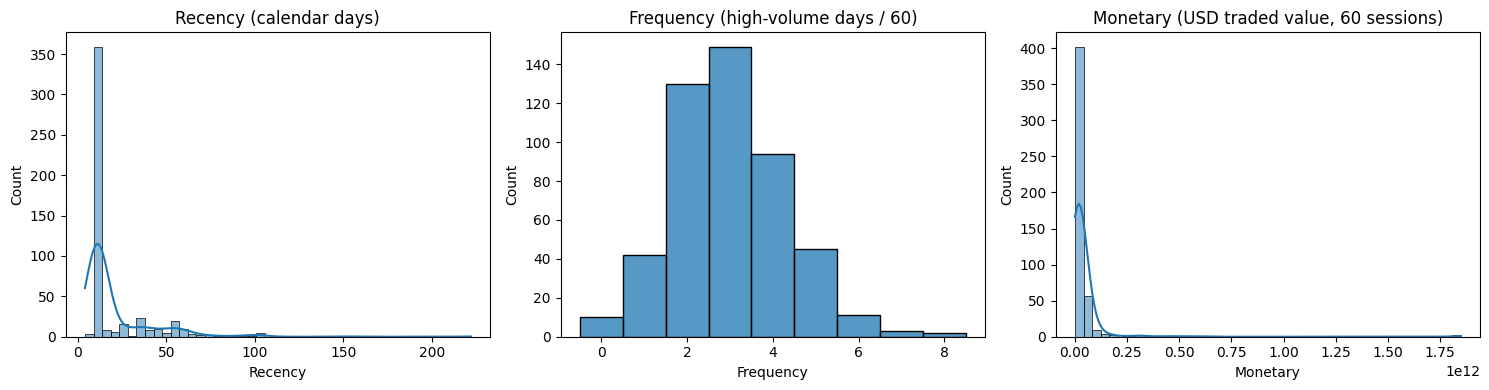

In [34]:
# RFM distributions
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(common['Recency'], kde=True, ax=ax[0]); ax[0].set_title('Recency (calendar days)')
sns.histplot(common['Frequency'], discrete=True, ax=ax[1]); ax[1].set_title('Frequency (high-volume days / 60)')
sns.histplot(common['Monetary'], kde=True, ax=ax[2]); ax[2].set_title('Monetary (USD traded value, 60 sessions)')
plt.tight_layout()
plt.savefig('outputs/rfm_distributions.png', dpi=150)
plt.show()

In [35]:
# Full inclusion / exclusion log: every Wikipedia ticker with its status
excluded_info = exclusion_df.drop_duplicates('Ticker').set_index('Ticker')
status_log = sp500_df[['Symbol', 'Ticker', 'Security', 'GICS Sector']].copy()
status_log['Status'] = np.where(status_log['Ticker'].isin(common.index), 'Included', 'Excluded')
status_log['Stage'] = status_log['Ticker'].map(excluded_info['Stage']).fillna('Included in clustering')
status_log['Reason'] = status_log['Ticker'].map(excluded_info['Reason']).fillna(
    'Passed all 1.2 validation rules; mean weekly return, beta, R, F and M all available')
status_log.to_csv('outputs/inclusion_exclusion_log_all_tickers.csv', index=False)

assert (status_log['Status'] == 'Included').sum() == len(common)
print(status_log['Status'].value_counts().to_string(), '\n')
print('By stage:'); print(status_log.groupby(['Status', 'Stage']).size().rename('Tickers').to_string())
print('\nIncluded shares by sector:')
display(status_log.pivot_table(index='GICS Sector', columns='Status', values='Ticker', aggfunc='count', fill_value=0))


Status
Included    486
Excluded     17 

By stage:
Status    Stage                 
Excluded  1.2 Validation             17
Included  Included in clustering    486

Included shares by sector:


Status,Excluded,Included
GICS Sector,,
Communication Services,2,20
Consumer Discretionary,0,47
Consumer Staples,1,32
Energy,1,20
Financials,2,74
Health Care,2,58
Industrials,5,78
Information Technology,2,74
Materials,1,23


In [36]:
# Feature summary in readable units (common valid share set)
readable = pd.DataFrame({
    'Mean weekly return (%)': common['Mean_Weekly_Return'] * 100,
    'Annualised return, approx (%)': common['Mean_Weekly_Return'] * 52 * 100,
    'Beta': common['Beta'],
    'Recency (calendar days)': common['Recency'],
    'Frequency (event days in 60)': common['Frequency'],
    'Monetary (USD bn, 60 sessions)': common['Monetary'] / 1e9,
})
summary_readable = readable.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T
summary_readable['skew'] = readable.skew()
summary_readable = summary_readable.drop(columns='count').round(3)
summary_readable.to_csv('outputs/feature_summary_readable.csv')
print(f'Common valid share set: {len(common)} shares')
summary_readable


Common valid share set: 486 shares


,mean,std,min,10%,25%,50%,75%,90%,max,skew
Mean weekly return (%),0.286,0.265,-0.447,-0.012,0.118,0.262,0.421,0.584,1.777,0.868
"Annualised return, approx (%)",14.857,13.788,-23.234,-0.636,6.144,13.618,21.878,30.348,92.417,0.868
Beta,0.974,0.407,0.055,0.472,0.667,0.951,1.180,1.476,3.779,1.104
Recency (calendar days),20.407,21.342,4.000,11.000,11.000,11.000,14.750,51.500,222.000,3.646
Frequency (event days in 60),2.990,1.331,0.000,1.000,2.000,3.000,4.000,5.000,8.000,0.425
"Monetary (USD bn, 60 sessions)",39.404,129.139,1.297,6.780,10.195,16.684,32.277,61.439,1847.697,11.684


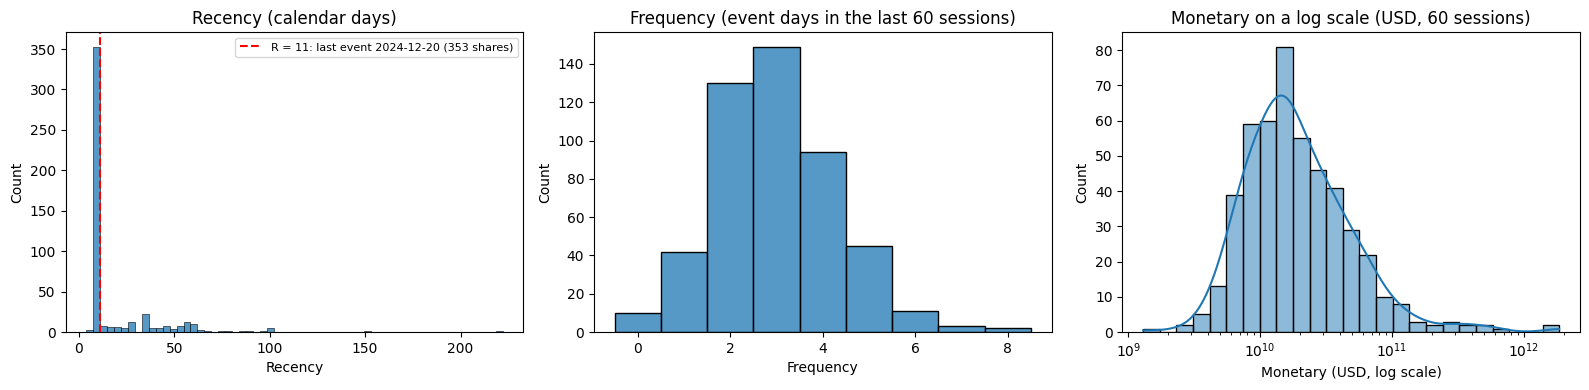

In [37]:
# Distributions on informative scales: Recency spike marked, Monetary on a log scale
r_mode = int(common['Recency'].mode()[0])
r_mode_date = (observation_date - pd.Timedelta(days=r_mode)).date()
n_mode = int((common['Recency'] == r_mode).sum())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(common['Recency'], bins=60, ax=ax[0])
ax[0].axvline(r_mode, color='red', linestyle='--',
              label=f'R = {r_mode}: last event {r_mode_date} ({n_mode} shares)')
ax[0].set(title='Recency (calendar days)', xlabel='Recency')
ax[0].legend(fontsize=8)
sns.histplot(common['Frequency'], discrete=True, ax=ax[1])
ax[1].set(title='Frequency (event days in the last 60 sessions)', xlabel='Frequency')
sns.histplot(common['Monetary'], log_scale=True, kde=True, ax=ax[2])
ax[2].set(title='Monetary on a log scale (USD, 60 sessions)', xlabel='Monetary (USD, log scale)')
plt.tight_layout()
plt.savefig('outputs/rfm_distributions_readable.png', dpi=150)
plt.show()


**What each metric captures (and what it does not)**

| Metric | Captures | Type | It is NOT | Limit as an investment signal |
|---|---|---|---|---|
| **Mean weekly return** | Average week-to-week total return (Adj Close, so dividends included), 2021–2024 | Past performance | An expected future return or a compound growth rate | Very noisy (large standard error) and weakly persistent between sub-periods; specific to 2021–24; biased up by survivorship |
| **Beta** | Sensitivity of weekly returns to ^GSPC moves (systematic risk) | Risk | Total risk (it ignores idiosyncratic risk, so check R²) or a quality measure | Estimation error; changes over time; one benchmark, linear, weekly data |
| **Recency (R)** | Calendar days since the latest abnormal-volume day | Activity (timing) | News, sentiment or a buy/sell signal | Dominated by market-wide event days (one date covers most shares), so it takes few distinct values; depends on the observation date |
| **Frequency (F)** | How often volume was abnormal (> 2× own baseline) in 60 sessions | Activity (intensity relative to the share's own normal) | Liquidity or the amount traded (very heavily traded shares can have F = 0) | Inflated by market-wide days; window-specific (Q4 2024); abnormal volume can mean good or bad news |
| **Monetary (M)** | Approximate dollar value traded over 60 sessions (Close × Volume) | Traded value / liquidity proxy | Market capitalisation, profit or money flowing in (every trade has a buyer and a seller) | Mostly reflects company size; ignores trading costs; window-specific; split across dual-class tickers |

**Key distinction:** return and beta describe **price behaviour (performance and risk)**, R and F describe **trading activity relative to each share's own normal**, and M describes **the scale of trading**. The cell below tests whether these really are different dimensions, and whether past values predict later ones.


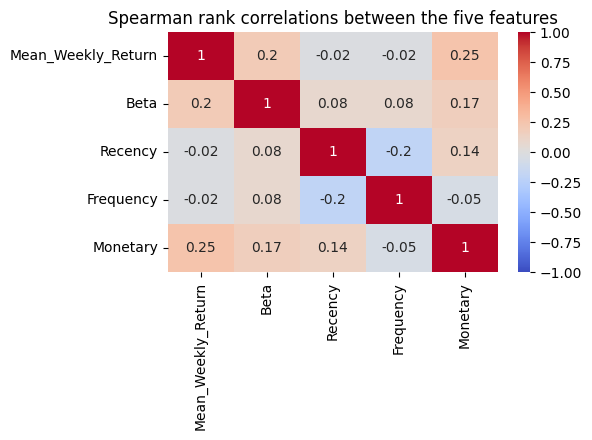

risk vs return                  : Spearman(Beta, Mean_Weekly_Return) = +0.20
activity vs traded value        : Spearman(Frequency, Monetary) = -0.05
activity timing vs traded value : Spearman(Recency, Monetary) = +0.14
risk vs traded value            : Spearman(Beta, Monetary) = +0.17
activity vs risk                : Spearman(Frequency, Beta) = +0.08

Persistence: 2021-01-15 to 2022-12-30 vs 2023-01-06 to 2024-12-27 (random expectation for "still top 20%" = 0.20)


,Spearman_first_vs_second,Top20pct_still_top20pct,Second_half_value_of_first_half_top20pct,Second_half_value_of_others
Feature,,,,
Mean weekly return (%),-0.144,0.184,0.317,0.412
Beta,0.796,0.612,1.545,0.823


In [38]:
# Evidence: are risk, activity and traded value different dimensions, and do past values persist?
features = common[all_features]
spearman_feat = features.corr(method='spearman').round(2)
spearman_feat.to_csv('outputs/feature_spearman_correlations.csv')
plt.figure(figsize=(6, 4.5))
sns.heatmap(spearman_feat, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman rank correlations between the five features')
plt.tight_layout()
plt.savefig('outputs/feature_spearman_heatmap.png', dpi=150)
plt.show()

pairs = [('Beta', 'Mean_Weekly_Return', 'risk vs return'),
         ('Frequency', 'Monetary', 'activity vs traded value'),
         ('Recency', 'Monetary', 'activity timing vs traded value'),
         ('Beta', 'Monetary', 'risk vs traded value'),
         ('Frequency', 'Beta', 'activity vs risk')]
for a, b, label in pairs:
    print(f'{label:<32}: Spearman({a}, {b}) = {spearman_feat.loc[a, b]:+.2f}')

# Persistence: do first-half values (2021-22) predict second-half values (2023-24)?
r_common = weekly_returns[common.index]
half = len(r_common) // 2
m_first, m_second = market_weekly_returns.iloc[:half], market_weekly_returns.iloc[half:]
ret_first, ret_second = r_common.iloc[:half].mean(), r_common.iloc[half:].mean()
b_first = r_common.iloc[:half].apply(lambda s: s.cov(m_first)) / m_first.var()
b_second = r_common.iloc[half:].apply(lambda s: s.cov(m_second)) / m_second.var()


def persistence(first, second, name):
    top_first = first >= first.quantile(0.8)
    top_second = second >= second.quantile(0.8)
    return {'Feature': name,
            'Spearman_first_vs_second': first.corr(second, method='spearman'),
            'Top20pct_still_top20pct': (top_first & top_second).sum() / top_first.sum(),
            'Second_half_value_of_first_half_top20pct': second[top_first].mean(),
            'Second_half_value_of_others': second[~top_first].mean()}


persist = pd.DataFrame([persistence(ret_first * 100, ret_second * 100, 'Mean weekly return (%)'),
                        persistence(b_first, b_second, 'Beta')]).set_index('Feature').round(3)
persist.to_csv('outputs/feature_persistence.csv')
print(f'\nPersistence: {r_common.index[0].date()} to {r_common.index[half - 1].date()} vs '
      f'{r_common.index[half].date()} to {r_common.index[-1].date()} (random expectation for "still top 20%" = 0.20)')
display(persist)


**Limits of interpreting these features as investment signals**

- **Backward-looking and period-specific:** every feature describes 2021–2024 (R, F and M only Q4 2024). The persistence table above shows how much past **returns** carry into the next sub-period compared with **beta**. Typically risk is far more persistent than return, so a high past mean return is weak evidence of a high future one.
- **Estimation noise:** mean returns have large standard errors (1.3.1), and betas have confidence intervals (1.3.2). Small differences between shares or clusters are not meaningful.
- **Activity is not direction:** a high-volume day can follow good or bad news. R and F say *that* trading was unusual, not whether prices should rise. Because most last-events fall on a few market-wide days, R mostly records the calendar rather than share-specific interest.
- **Traded value is not value:** M mostly reflects company size and trading interest. It is not market capitalisation, profitability or net investment inflow, and it ignores trading costs.
- **Survivorship and sample:** only current constituents with complete histories are included (1.1, 1.2), which biases returns upward.
- **No costs, taxes or risk constraints** are modelled, so the features cannot be turned directly into a trading strategy.
- **Clusters built on these features are descriptive segments** (Task 2): they group similar past behaviour; they are not buy/sell recommendations.


# **Task 02 - Stock Segmentation and Sensitivity**

# **2.1 Feature Preparation**

Skewness (raw):
Mean_Weekly_Return     0.868
Beta                   1.104
Recency                3.646
Frequency              0.425
Monetary              11.684
dtype: float64


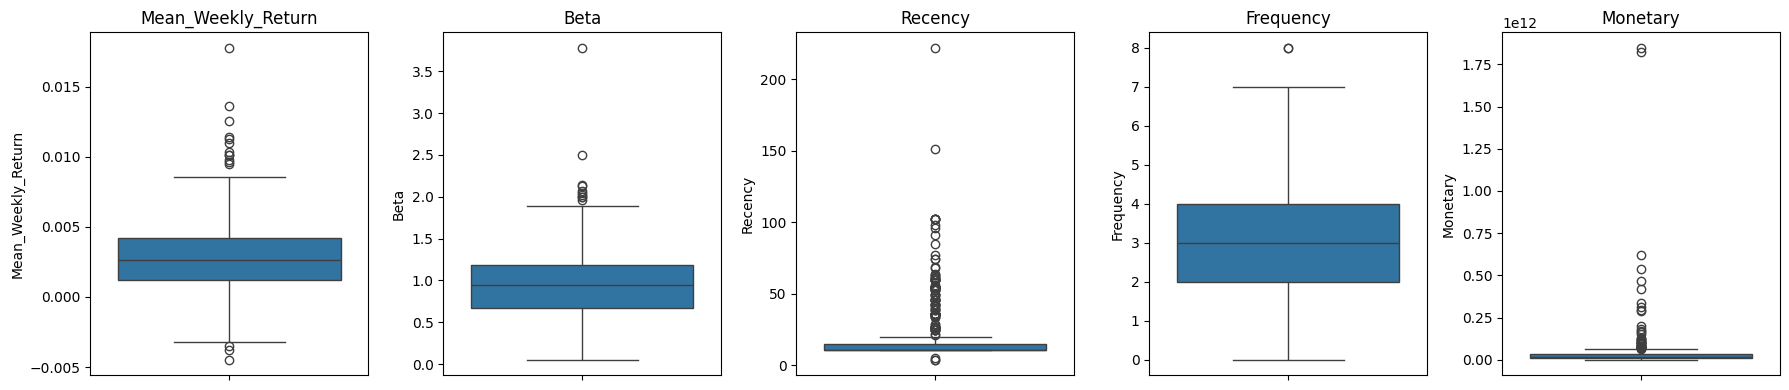

In [39]:
data = common.copy()
rr_features = ['Mean_Weekly_Return', 'Beta']
rfm_features = ['Recency', 'Frequency', 'Log_Monetary']

print('Skewness (raw):')
print(data[all_features].skew().round(3))

# Boxplots for outlier inspection
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, all_features):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig('outputs/feature_boxplots.png', dpi=150)
plt.show()

In [40]:
# Reduce the influence of very large traded values
data['Log_Monetary'] = np.log1p(data['Monetary'])
print('Skewness after log1p(M):')
print(data[rfm_features].skew().round(3))

risk_return_df = data[rr_features]
rfm_matrix_df = data[rfm_features]

# Standardise each matrix separately
X_rr = StandardScaler().fit_transform(risk_return_df)
X_rfm = StandardScaler().fit_transform(rfm_matrix_df)

print('\nScaled means:', X_rr.mean(axis=0).round(2), X_rfm.mean(axis=0).round(2))
print('Scaled stds :', X_rr.std(axis=0).round(2), X_rfm.std(axis=0).round(2))

# Outlier count: |z| > 3 after scaling (retained, reported)
print('\nShares with |z| > 3:')
print(pd.Series((np.abs(X_rr) > 3).sum(axis=0), index=rr_features))
print(pd.Series((np.abs(X_rfm) > 3).sum(axis=0), index=rfm_features))

Skewness after log1p(M):
Recency         3.646
Frequency       0.425
Log_Monetary    1.079
dtype: float64

Scaled means: [-0. -0.] [-0. -0. -0.]
Scaled stds : [1. 1.] [1. 1. 1.]

Shares with |z| > 3:
Mean_Weekly_Return    6
Beta                  2
dtype: int64
Recency         11
Frequency        5
Log_Monetary     7
dtype: int64


Common sample: both matrices use the same 486 shares (same order), no missing or infinite values.

Top1pct_share_of_squared_z = share of the feature's total squared z-score (its weight in distances) contributed by its top 1% of shares (5 shares). With no outliers this would be about 1%.


,Matrix,Feature,Transform,Skew_raw,Skew_used,n_abs_z_gt_3,Max_abs_z,Top1pct_share_of_squared_z
0,Risk/return,Mean_Weekly_Return,none,0.868,0.868,6,5.631,0.169
1,Risk/return,Beta,none,1.104,1.104,2,6.893,0.175
2,RFM,Recency,none,3.646,3.646,11,9.455,0.352
3,RFM,Frequency,none,0.425,0.425,5,3.769,0.115
4,RFM,Monetary,log1p,11.684,1.079,7,4.848,0.174
5,RFM (not used),Monetary,none: what raw M would do,11.684,11.684,5,14.017,0.894
6,RFM (not used),Recency,log1p: candidate,3.646,1.583,2,4.216,0.117


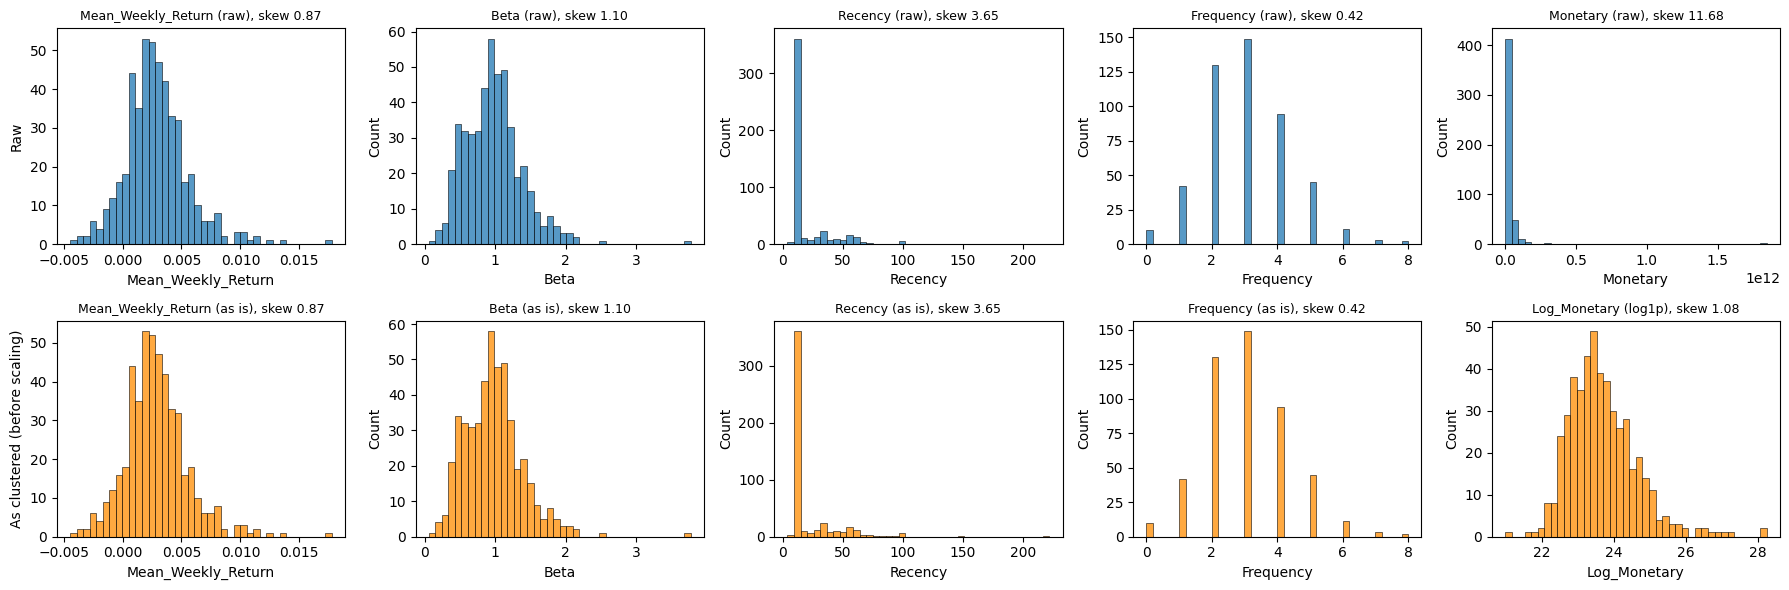

29 outlier rows (shares with |z| > 3 on at least one feature), all retained:


,Matrix,Ticker,Security,Sector,Features_abs_z_gt_3,z_Mean_Weekly_Return,z_Beta,z_Recency,z_Frequency,z_Log_Monetary
0,Risk/return,XYZ,"Block, Inc.",Financials,Beta,-1.67,3.76,NaN,NaN,NaN
1,Risk/return,CVNA,Carvana,Consumer Discretionary,"Mean_Weekly_Return, Beta",3.06,6.89,NaN,NaN,NaN
2,Risk/return,FIX,Comfort Systems USA,Industrials,Mean_Weekly_Return,3.19,0.89,NaN,NaN,NaN
3,Risk/return,NVDA,Nvidia,Information Technology,Mean_Weekly_Return,4.06,2.83,NaN,NaN,NaN
4,Risk/return,SMCI,Supermicro,Information Technology,Mean_Weekly_Return,5.63,1.99,NaN,NaN,NaN
5,Risk/return,VRT,Vertiv,Industrials,Mean_Weekly_Return,3.67,2.53,NaN,NaN,NaN
6,Risk/return,VST,Vistra Corp.,Utilities,Mean_Weekly_Return,3.22,0.11,NaN,NaN,NaN
7,RFM,APD,Air Products,Materials,Recency,NaN,NaN,3.03,-1.50,0.34
8,RFM,AMZN,Amazon,Consumer Discretionary,Log_Monetary,NaN,NaN,-0.44,1.51,3.39
9,RFM,AAPL,Apple Inc.,Information Technology,Log_Monetary,NaN,NaN,-0.44,-0.74,3.69


In [41]:
# 2.1 Common-sample check, skew/outlier diagnostics (before vs after transformation), outlier list
assert risk_return_df.index.equals(rfm_matrix_df.index) and risk_return_df.index.equals(common.index), \
    'the two matrices do not use the same shares in the same order'
assert np.isfinite(risk_return_df.values).all() and np.isfinite(rfm_matrix_df.values).all(), 'missing or infinite inputs'
print(f'Common sample: both matrices use the same {len(risk_return_df)} shares (same order), no missing or infinite values.')


def diag_row(matrix, feature, transform, raw, used):
    z = (used - used.mean()) / used.std(ddof=0)          # same scaling as StandardScaler
    z2 = z ** 2
    n_top = int(np.ceil(0.01 * len(z)))
    return {'Matrix': matrix, 'Feature': feature, 'Transform': transform,
            'Skew_raw': raw.skew(), 'Skew_used': used.skew(),
            'n_abs_z_gt_3': int((z.abs() > 3).sum()), 'Max_abs_z': z.abs().max(),
            'Top1pct_share_of_squared_z': z2.nlargest(n_top).sum() / z2.sum()}


prep_diag = pd.DataFrame([
    diag_row('Risk/return', 'Mean_Weekly_Return', 'none', data['Mean_Weekly_Return'], data['Mean_Weekly_Return']),
    diag_row('Risk/return', 'Beta', 'none', data['Beta'], data['Beta']),
    diag_row('RFM', 'Recency', 'none', data['Recency'], data['Recency']),
    diag_row('RFM', 'Frequency', 'none', data['Frequency'], data['Frequency']),
    diag_row('RFM', 'Monetary', 'log1p', data['Monetary'], data['Log_Monetary']),
    diag_row('RFM (not used)', 'Monetary', 'none: what raw M would do', data['Monetary'], data['Monetary']),
    diag_row('RFM (not used)', 'Recency', 'log1p: candidate', data['Recency'], np.log1p(data['Recency'])),
]).round(3)
prep_diag.to_csv('outputs/feature_preparation_diagnostics.csv', index=False)
print('\nTop1pct_share_of_squared_z = share of the feature\'s total squared z-score (its weight in distances) '
      'contributed by its top 1% of shares (5 shares). With no outliers this would be about 1%.')
display(prep_diag)

# Histograms: raw (top) vs as used for clustering (bottom)
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for j, (raw, used, tag) in enumerate([('Mean_Weekly_Return', 'Mean_Weekly_Return', 'as is'), ('Beta', 'Beta', 'as is'),
                                      ('Recency', 'Recency', 'as is'), ('Frequency', 'Frequency', 'as is'),
                                      ('Monetary', 'Log_Monetary', 'log1p')]):
    sns.histplot(data[raw], bins=40, ax=axes[0, j])
    axes[0, j].set_title(f'{raw} (raw), skew {data[raw].skew():.2f}', fontsize=9)
    sns.histplot(data[used], bins=40, ax=axes[1, j], color='darkorange')
    axes[1, j].set_title(f'{used} ({tag}), skew {data[used].skew():.2f}', fontsize=9)
axes[0, 0].set_ylabel('Raw'); axes[1, 0].set_ylabel('As clustered (before scaling)')
plt.tight_layout()
plt.savefig('outputs/feature_raw_vs_used_histograms.png', dpi=150)
plt.show()

# Which shares are outliers (|z| > 3)? They are real observations and are kept.
z_rr = pd.DataFrame(X_rr, index=data.index, columns=rr_features)
z_rfm = pd.DataFrame(X_rfm, index=data.index, columns=rfm_features)
outlier_rows = []
for matrix, z in [('Risk/return', z_rr), ('RFM', z_rfm)]:
    for t, row in z[(z.abs() > 3).any(axis=1)].iterrows():
        outlier_rows.append({'Matrix': matrix, 'Ticker': t, 'Security': data.loc[t, 'Security'],
                             'Sector': data.loc[t, 'GICS Sector'],
                             'Features_abs_z_gt_3': ', '.join(c for c in z.columns if abs(row[c]) > 3),
                             **{f'z_{c}': round(row[c], 2) for c in z.columns}})
outlier_table = pd.DataFrame(outlier_rows)
outlier_table.to_csv('outputs/outliers_kept.csv', index=False)
print(f'{len(outlier_table)} outlier rows (shares with |z| > 3 on at least one feature), all retained:')
display(outlier_table)


In [42]:
# 2.1 How scaling and transformations change Euclidean distances (what Ward and K-means "see")
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr


def variance_share(df):
    """Each feature's share of the mean squared pairwise Euclidean distance (= its share of total variance)."""
    v = df.var(ddof=0)
    return (v / v.sum() * 100).round(2)


contrib = pd.DataFrame({
    'Risk/return, unscaled': variance_share(data[rr_features]),
    'Risk/return, standardised': variance_share(z_rr),
    'RFM raw M, unscaled': variance_share(data[['Recency', 'Frequency', 'Monetary']]).rename({'Monetary': 'Log_Monetary'}),
    'RFM as used (log1p M), standardised': variance_share(z_rfm),
}).reindex(rr_features + rfm_features)
print('Share of squared distance contributed by each feature (%):')
display(contrib)


def compare_distances(X_a, X_b):
    """Rank correlation of all pairwise distances, and share of shares whose nearest neighbour changes."""
    d_a, d_b = pdist(X_a), pdist(X_b)
    D_a, D_b = squareform(d_a), squareform(d_b)
    np.fill_diagonal(D_a, np.inf); np.fill_diagonal(D_b, np.inf)
    return spearmanr(d_a, d_b).correlation, (D_a.argmin(axis=1) != D_b.argmin(axis=1)).mean()


X_rawM = StandardScaler().fit_transform(data[['Recency', 'Frequency', 'Monetary']])
X_logR = StandardScaler().fit_transform(np.column_stack([np.log1p(data['Recency']), data['Frequency'], data['Log_Monetary']]))
rows = []
for label, X_alt in [('RFM as used vs raw M (no log1p)', X_rawM), ('RFM as used vs log1p(R)', X_logR)]:
    rho, nn_changed = compare_distances(X_rfm, X_alt)
    rows.append({'Comparison': label, 'Spearman_of_pairwise_distances': round(rho, 3),
                 'Share_nearest_neighbour_changes': round(nn_changed, 3)})
distance_comparison = pd.DataFrame(rows)
distance_comparison.to_csv('outputs/distance_sensitivity_transformations.csv', index=False)
display(distance_comparison)

# How much do the Recency outliers dominate the largest RFM distances?
D = squareform(pdist(X_rfm))
iu = np.triu_indices_from(D, k=1)
d = D[iu]
largest = d >= np.quantile(d, 0.99)
r_outliers = np.where(np.abs(z_rfm['Recency'].values) > 3)[0]
involves = np.isin(iu[0], r_outliers) | np.isin(iu[1], r_outliers)
print(f'{len(r_outliers)} Recency outliers ({len(r_outliers) / len(data):.1%} of shares) are involved in '
      f'{involves[largest].mean():.1%} of the largest 1% of RFM pairwise distances.')


Share of squared distance contributed by each feature (%):


,"Risk/return, unscaled","Risk/return, standardised","RFM raw M, unscaled","RFM as used (log1p M), standardised"
Mean_Weekly_Return,0.0,50.0,NaN,NaN
Beta,100.0,50.0,NaN,NaN
Recency,NaN,NaN,0.0,33.33
Frequency,NaN,NaN,0.0,33.33
Log_Monetary,NaN,NaN,100.0,33.33


,Comparison,Spearman_of_pairwise_distances,Share_nearest_neighbour_changes
0,RFM as used vs raw M (no log1p),0.881,0.144
1,RFM as used vs log1p(R),0.975,0.053


11 Recency outliers (2.3% of shares) are involved in 88.7% of the largest 1% of RFM pairwise distances.


**Transformation choices and their effect on distances**

Both Ward and K-means use **Euclidean distance on the standardised features**, so the preparation decides what "similar" means:

- **Standardisation (each matrix separately):** without it, the feature with the largest numeric scale dominates the distance. Beta (around 1) would swamp mean weekly return (around 0.003), and raw M (billions) would swamp R and F. The contribution table shows this. After standardisation each feature carries equal weight (50% / 33% each), so the choice of features *is* the weighting.
- **log1p(M):** traded value spans roughly three orders of magnitude, with skew 11.7. On a raw scale a handful of mega-caps would sit far from everything else, and distances would mostly encode "mega-cap or not". log1p turns ratios into differences (a share trading 10× more is one fixed step away, whatever its size). Skew drops to about 1.1, and the nearest-neighbour and distance-rank comparison shows how much the geometry changes.
- **Recency kept raw (skew 3.6):** the brief requires log1p only for M. Calendar days are directly interpretable, and the long-R shares are substantively different (no high-volume event for months), so compressing them would hide a real distinction. The cost is that a few shares with large z-scores carry a disproportionate share of Recency's weight and of the largest RFM distances (see the diagnostics). They can form small separate clusters, which the minimum-cluster-size rule in k selection guards against. log1p(R) was tested as a sensitivity check (distance comparison above, and the ARI in 2.5.2).
- **Mean weekly return and beta kept raw:** their skew is moderate (0.87 and 1.10), they are already on interpretable scales, and transforming returns (which can be negative) would distort the risk–return trade-off the matrix is meant to capture.
- **Outliers retained:** the |z| > 3 shares are genuine observations (validated in 1.2), not errors, so removing or winsorising them would discard real behaviour. Their influence is reported instead.
- **Correlated inputs:** standardisation does not remove correlation. Two correlated features effectively give their shared dimension double weight, which 2.5.1 examines.


# **2.2 Agglomerative Clustering (Ward, Euclidean)**

**Why Ward agglomerative clustering, and its limitations**

Ward's method starts with every share as its own cluster and repeatedly merges the two clusters whose union **increases the total within-cluster sum of squares the least**, using **Euclidean distance on the standardised features** (each matrix scaled separately in 2.1).

*Suitability*
- **No k needed in advance:** one run gives the full hierarchy, so every k from 2 to 8 can be compared from the same tree, and the dendrogram shows how groups nest.
- **Deterministic and reproducible:** no random initialisation, so the same data always gives the same tree.
- **Comparable with K-means:** both minimise within-cluster variance, so differences between the two reflect the search strategy, not a different objective.
- **Interpretable:** merge heights show how different the groups being joined are, which gives evidence on natural cut points.

*Limitations*
- **Greedy and irreversible:** an early merge is never undone, even if a share would fit better elsewhere at the final k (K-means can reassign).
- **Shape and size bias:** it favours compact, roughly spherical, similar-variance clusters, and can split elongated or uneven groups.
- **Sensitive to scaling and outliers:** distances depend on the preparation choices in 2.1. Extreme shares (e.g. very long Recency) can form tiny clusters.
- **Euclidean only:** Ward's criterion is defined for Euclidean distance.
- **Cost:** O(n²) memory. This is fine for 486 shares but would not scale to very large universes.


In [43]:
def within_ss(X, labels):
    """Within-cluster sum of squared distances to each cluster centroid (same quantity as K-means inertia)."""
    X = np.asarray(X)
    labels = np.asarray(labels)
    return float(sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels)))


def evaluate_ward(X, title, filename):
    """Ward linkage, dendrogram and k = 2..8 diagnostics (within-cluster SS, silhouette, sizes)."""
    hierarchy = linkage(X, method='ward')

    plt.figure(figsize=(12, 5))
    dendrogram(hierarchy, truncate_mode='lastp', p=30, leaf_rotation=90, show_leaf_counts=True)
    plt.title(f'Ward dendrogram: {title} (last 30 merges)')
    plt.xlabel('Cluster (number of shares in brackets)')
    plt.ylabel('Ward linkage distance')
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

    rows = []
    for k in K_RANGE:
        labels = cut_tree(hierarchy, n_clusters=k).ravel() + 1
        sizes = pd.Series(labels).value_counts().sort_index().tolist()
        rows.append({'k': k,
                     'Inertia': round(within_ss(X, labels), 2),
                     'Silhouette': round(silhouette_score(X, labels), 3),
                     'Smallest_cluster': min(sizes),
                     'Cluster_sizes': sizes})
    return hierarchy, pd.DataFrame(rows)


def ward_profiles(hierarchy, profile_cols, ks=K_RANGE):
    """Cluster averages in original units for each candidate k."""
    for k in ks:
        labels = cut_tree(hierarchy, n_clusters=k).ravel() + 1
        print(f'--- k = {k} ---')
        display(data.groupby(labels)[profile_cols].mean().round(4)
                .assign(Count=pd.Series(labels).value_counts().sort_index().values))


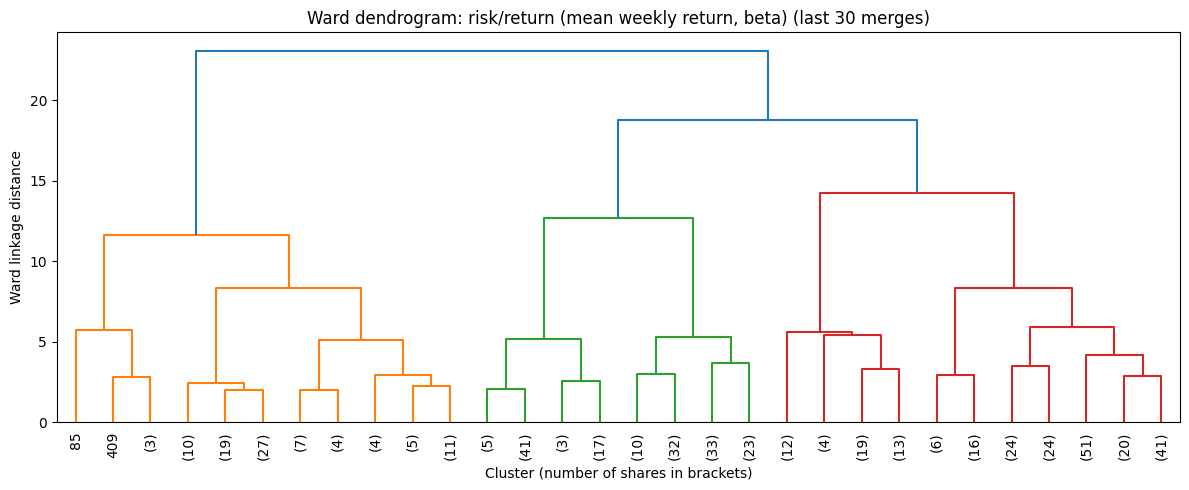

,k,Inertia,Silhouette,Smallest_cluster,Cluster_sizes
0,2,705.81,0.339,92,"[394, 92]"
1,3,529.04,0.274,92,"[230, 164, 92]"
2,4,428.07,0.282,48,"[182, 164, 48, 92]"
3,5,347.82,0.304,48,"[182, 66, 98, 48, 92]"
4,6,280.52,0.320,5,"[182, 66, 98, 48, 87, 5]"
5,7,245.73,0.324,5,"[160, 66, 98, 48, 22, 87, 5]"
6,8,211.22,0.321,5,"[160, 66, 98, 48, 22, 56, 31, 5]"


In [44]:
hier_rr, ward_rr_eval = evaluate_ward(X_rr, 'risk/return (mean weekly return, beta)', 'outputs/dendrogram_risk_return.png')
ward_rr_eval

In [45]:
ward_profiles(hier_rr, rr_features)

--- k = 2 ---


,Mean_Weekly_Return,Beta,Count
1,0.0020,0.8979,394
2,0.0063,1.2981,92


--- k = 3 ---


,Mean_Weekly_Return,Beta,Count
1,0.0015,1.1096,230
2,0.0029,0.6012,164
3,0.0063,1.2981,92


--- k = 4 ---


,Mean_Weekly_Return,Beta,Count
1,0.0013,0.9728,182
2,0.0029,0.6012,164
3,0.0020,1.6280,48
4,0.0063,1.2981,92


... (4 outputs left out)

--- k = 7 ---


,Mean_Weekly_Return,Beta,Count
1,0.0017,0.9499,160
2,0.0009,0.4390,66
3,0.0042,0.7104,98
4,0.0020,1.6280,48
5,-0.0016,1.1397,22
6,0.0059,1.2383,87
7,0.0129,2.3386,5


--- k = 8 ---


,Mean_Weekly_Return,Beta,Count
1,0.0017,0.9499,160
2,0.0009,0.4390,66
3,0.0042,0.7104,98
4,0.0020,1.6280,48
5,-0.0016,1.1397,22
6,0.0047,1.2110,56
7,0.0082,1.2876,31
8,0.0129,2.3386,5


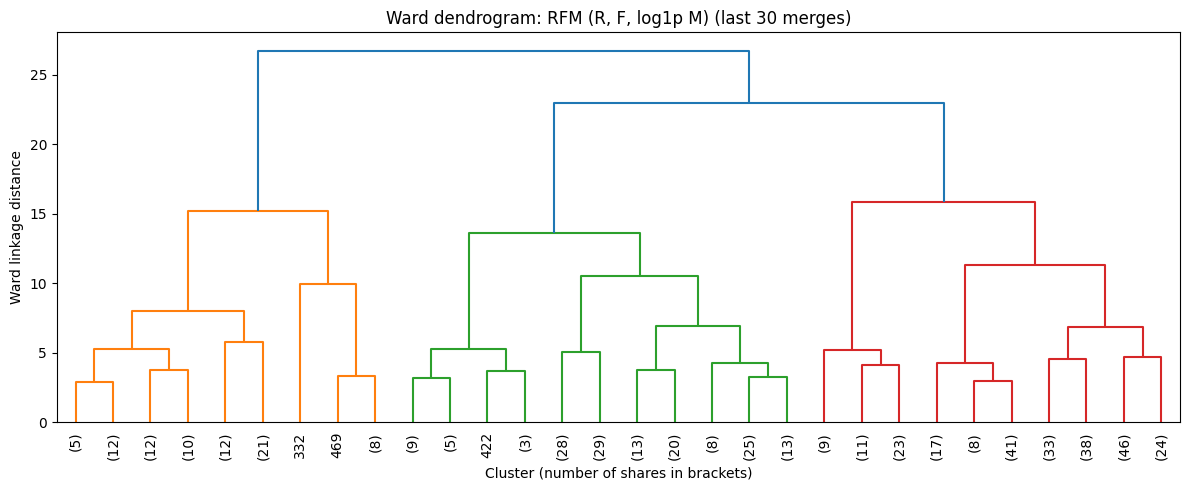

,k,Inertia,Silhouette,Smallest_cluster,Cluster_sizes
0,2,1101.40,0.368,82,"[404, 82]"
1,3,837.24,0.304,82,"[154, 250, 82]"
2,4,711.73,0.289,43,"[154, 207, 82, 43]"
3,5,596.94,0.305,10,"[154, 207, 72, 43, 10]"
4,6,504.73,0.314,10,"[136, 207, 18, 72, 43, 10]"
5,7,440.96,0.292,10,"[136, 66, 18, 72, 141, 43, 10]"
6,8,385.45,0.302,10,"[57, 66, 79, 18, 72, 141, 43, 10]"


In [46]:
hier_rfm, ward_rfm_eval = evaluate_ward(X_rfm, 'RFM (R, F, log1p M)', 'outputs/dendrogram_rfm.png')
ward_rfm_eval

In [47]:
ward_profiles(hier_rfm, ['Recency', 'Frequency', 'Monetary'])

--- k = 2 ---


,Recency,Frequency,Monetary,Count
1,12.7153,3.1708,3.783020e+10,404
2,58.3049,2.0976,4.715898e+10,82


--- k = 3 ---


,Recency,Frequency,Monetary,Count
1,13.6818,2.8636,8.014525e+10,154
2,12.1200,3.3600,1.176413e+10,250
3,58.3049,2.0976,4.715898e+10,82


--- k = 4 ---


,Recency,Frequency,Monetary,Count
1,13.6818,2.8636,8.014525e+10,154
2,11.1401,2.9420,1.109981e+10,207
3,58.3049,2.0976,4.715898e+10,82
4,16.8372,5.3721,1.496218e+10,43


... (4 outputs left out)

--- k = 7 ---


,Recency,Frequency,Monetary,Count
1,13.1765,2.6397,4.437085e+10,136
2,11.0758,1.8636,1.085987e+10,66
3,17.5000,4.5556,3.504407e+11,18
4,50.1806,2.3889,2.596689e+10,72
5,11.1702,3.4468,1.121211e+10,141
6,16.8372,5.3721,1.496218e+10,43
7,116.8000,0.0000,1.997420e+11,10


--- k = 8 ---


,Recency,Frequency,Monetary,Count
1,12.0351,3.6316,3.844354e+10,57
2,11.0758,1.8636,1.085987e+10,66
3,14.0000,1.9241,4.864752e+10,79
4,17.5000,4.5556,3.504407e+11,18
5,50.1806,2.3889,2.596689e+10,72
6,11.1702,3.4468,1.121211e+10,141
7,16.8372,5.3721,1.496218e+10,43
8,116.8000,0.0000,1.997420e+11,10


# **2.3 K-means Clustering**

**Why K-means, and its assumptions and limitations**

K-means places k centroids and alternates between assigning each share to its nearest centroid (Euclidean distance on the standardised features) and moving each centroid to the mean of its shares. This minimises the **within-cluster sum of squares (inertia)**.

*Suitability*
- **Same objective as Ward:** it minimises within-cluster variance, but it can **reassign** shares, so it can improve on Ward's greedy merges. The two are therefore a meaningful comparison.
- **Interpretable centroids:** each cluster is summarised by a mean profile.
- **Fast and scalable**, which makes it cheap to test many k values and many initialisations.

*Assumptions and limitations*
- **Roughly spherical, similar-variance clusters:** it draws straight boundaries halfway between centroids, so elongated, uneven or nested groups are split badly.
- **Euclidean distance and scaling:** results depend on the standardisation and transforms in 2.1.
- **Centroids are means:** outliers pull them, and extreme shares can be given their own tiny cluster.
- **k must be fixed in advance**, and every share is forced into some cluster, even ambiguous ones.
- **Local optima:** different starting centroids can give different solutions. This is addressed with k-means++ seeding, **50 initialisations (`n_init=50`)** and a fixed **random seed (42)**, and tested below.


In [48]:
def evaluate_kmeans(X, title, filename):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        sizes = pd.Series(km.labels_).value_counts().sort_index().tolist()
        rows.append({'k': k,
                     'Inertia': round(km.inertia_, 2),
                     'Silhouette': round(silhouette_score(X, km.labels_), 3),
                     'Smallest_cluster': min(sizes),
                     'Cluster_sizes': sizes})
    results = pd.DataFrame(rows)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(results['k'], results['Inertia'], 'o-'); ax[0].set(title=f'Elbow: {title}', xlabel='k', ylabel='Inertia')
    ax[1].plot(results['k'], results['Silhouette'], 'o-'); ax[1].set(title=f'Silhouette: {title}', xlabel='k', ylabel='Avg silhouette')
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()
    return results


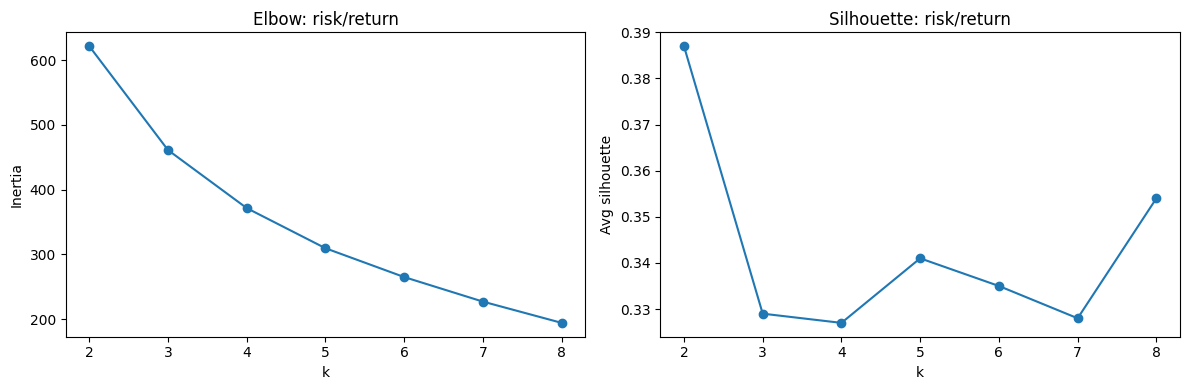

,k,Inertia,Silhouette,Smallest_cluster,Cluster_sizes
0,2,621.63,0.387,143,"[143, 343]"
1,3,461.18,0.329,119,"[202, 165, 119]"
2,4,371.58,0.327,40,"[132, 154, 40, 160]"
3,5,309.61,0.341,27,"[112, 166, 131, 27, 50]"
4,6,265.10,0.335,5,"[156, 127, 50, 105, 43, 5]"
5,7,227.18,0.328,5,"[103, 85, 41, 128, 77, 47, 5]"
6,8,194.36,0.354,5,"[136, 43, 76, 78, 5, 29, 40, 79]"


In [49]:
kmeans_rr_eval = evaluate_kmeans(X_rr, 'risk/return', 'outputs/kmeans_k_risk_return.png')
kmeans_rr_eval

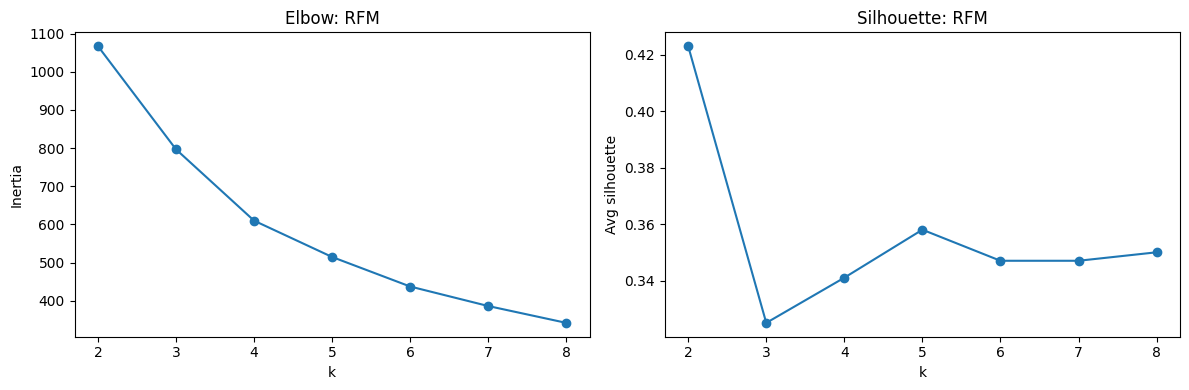

,k,Inertia,Silhouette,Smallest_cluster,Cluster_sizes
0,2,1066.83,0.423,68,"[418, 68]"
1,3,796.61,0.325,64,"[270, 152, 64]"
2,4,609.83,0.341,61,"[122, 61, 212, 91]"
3,5,514.71,0.358,11,"[68, 122, 87, 11, 198]"
4,6,437.39,0.347,11,"[105, 143, 40, 11, 120, 67]"
5,7,386.29,0.347,1,"[141, 41, 104, 120, 1, 68, 11]"
6,8,342.17,0.350,1,"[15, 106, 64, 66, 1, 11, 140, 83]"


In [50]:
kmeans_rfm_eval = evaluate_kmeans(X_rfm, 'RFM', 'outputs/kmeans_k_rfm.png')
kmeans_rfm_eval

**Selected Cluster counts**

In [51]:
def choose_k(eval_table, n_shares=len(data)):
    """k-selection rule: highest silhouette among k >= K_MIN_SELECT whose smallest cluster holds
    at least MIN_CLUSTER_SHARE of the shares. If no k meets the size rule, the size rule is dropped."""
    candidates = eval_table[eval_table['k'] >= K_MIN_SELECT]
    eligible = candidates[candidates['Smallest_cluster'] / n_shares >= MIN_CLUSTER_SHARE]
    if eligible.empty:
        eligible = candidates
    return int(eligible.loc[eligible['Silhouette'].idxmax(), 'k'])


def order_clusters(labels, order_by):
    """Renumber clusters 1..k so that cluster 1 has the LOWEST mean of `order_by`.
    Cluster numbers are arbitrary; this only makes tables and plots comparable (ARI is unaffected)."""
    labels = np.asarray(labels)
    means = pd.Series(np.asarray(order_by)).groupby(labels).mean().sort_values()
    mapping = {old: new for new, old in enumerate(means.index, start=1)}
    return np.array([mapping[x] for x in labels])


In [52]:
# Selected k for each baseline solution, from the rule above
WARD_K_RR = choose_k(ward_rr_eval)
KMEANS_K_RR = choose_k(kmeans_rr_eval)
WARD_K_RFM = choose_k(ward_rfm_eval)
KMEANS_K_RFM = choose_k(kmeans_rfm_eval)

selected_k = pd.DataFrame({'Solution': ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM'],
                           'Selected_k': [WARD_K_RR, KMEANS_K_RR, WARD_K_RFM, KMEANS_K_RFM]})
selected_k.to_csv('outputs/selected_k.csv', index=False)
display(selected_k)

# Four baseline solutions. Clusters are renumbered 1..k so that cluster 1 has the lowest
# mean beta (risk/return) or the lowest mean log1p(M) (RFM); the numbers are otherwise arbitrary.
data['Ward_RR'] = order_clusters(cut_tree(hier_rr, n_clusters=WARD_K_RR).ravel(), data['Beta'])
data['Ward_RFM'] = order_clusters(cut_tree(hier_rfm, n_clusters=WARD_K_RFM).ravel(), data['Log_Monetary'])
data['KMeans_RR'] = order_clusters(KMeans(n_clusters=KMEANS_K_RR, n_init=N_INIT, random_state=SEED).fit_predict(X_rr),
                                   data['Beta'])
data['KMeans_RFM'] = order_clusters(KMeans(n_clusters=KMEANS_K_RFM, n_init=N_INIT, random_state=SEED).fit_predict(X_rfm),
                                    data['Log_Monetary'])

for col in ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']:
    print(col, 'sizes:', data[col].value_counts().sort_index().to_dict())


,Solution,Selected_k
0,Ward_RR,5
1,KMeans_RR,5
2,Ward_RFM,3
3,KMeans_RFM,4


Ward_RR sizes: {1: 66, 2: 98, 3: 182, 4: 92, 5: 48}
KMeans_RR sizes: {1: 131, 2: 166, 3: 112, 4: 27, 5: 50}
Ward_RFM sizes: {1: 250, 2: 82, 3: 154}
KMeans_RFM sizes: {1: 122, 2: 212, 3: 61, 4: 91}


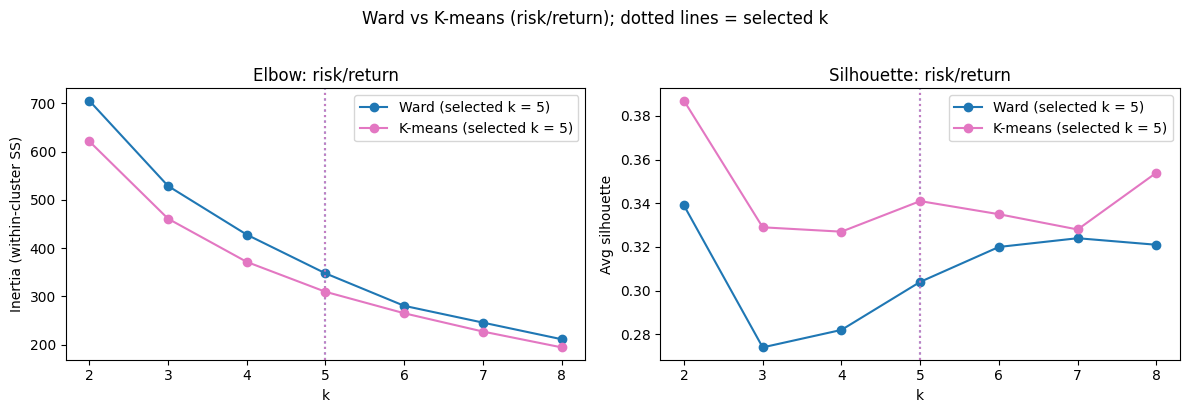

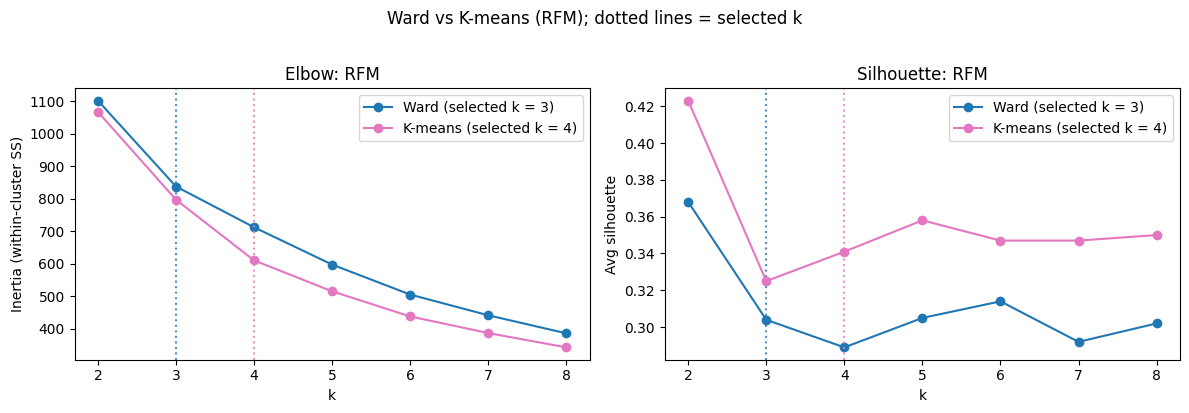

In [53]:
# Ward vs K-means k diagnostics on the same axes: one figure per feature matrix so the two can be compared.
# Dotted vertical lines mark the k selected by the rule above (blue = Ward, red = K-means).
diagnostic_sets = [
    ('risk/return', ward_rr_eval, kmeans_rr_eval,
     WARD_K_RR, KMEANS_K_RR, 'outputs/k_diagnostics_risk_return.png'),
    ('RFM', ward_rfm_eval, kmeans_rfm_eval,
     WARD_K_RFM, KMEANS_K_RFM, 'outputs/k_diagnostics_rfm.png'),
]

for title, ward_eval, km_eval, k_ward, k_km, filename in diagnostic_sets:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for ev, k_sel, name, color in [(ward_eval, k_ward, 'Ward', 'tab:blue'), (km_eval, k_km, 'K-means', 'tab:pink')]:
        ax[0].plot(ev['k'], ev['Inertia'], 'o-', color=color, label=f'{name} (selected k = {k_sel})')
        ax[1].plot(ev['k'], ev['Silhouette'], 'o-', color=color, label=f'{name} (selected k = {k_sel})')
        for a in ax:
            a.axvline(k_sel, color=color, linestyle=':', alpha=0.8)
    ax[0].set(title=f'Elbow: {title}', xlabel='k', ylabel='Inertia (within-cluster SS)')
    ax[1].set(title=f'Silhouette: {title}', xlabel='k', ylabel='Avg silhouette')
    for a in ax:
        a.set_xticks(list(K_RANGE))
        a.legend()
    fig.suptitle(f'Ward vs K-means ({title}); dotted lines = selected k', y=1.02)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


**2.2 (continued) Ward at the selected k: dendrogram structure and cluster quality**

The k for each solution comes from the rule above, not from the dendrogram's default colour threshold. The dendrograms below are redrawn with the **cut line and colours at the selected k**. Merge heights, the cophenetic correlation, the nesting of clusters across k, and cluster-level silhouettes give further evidence on the structure.


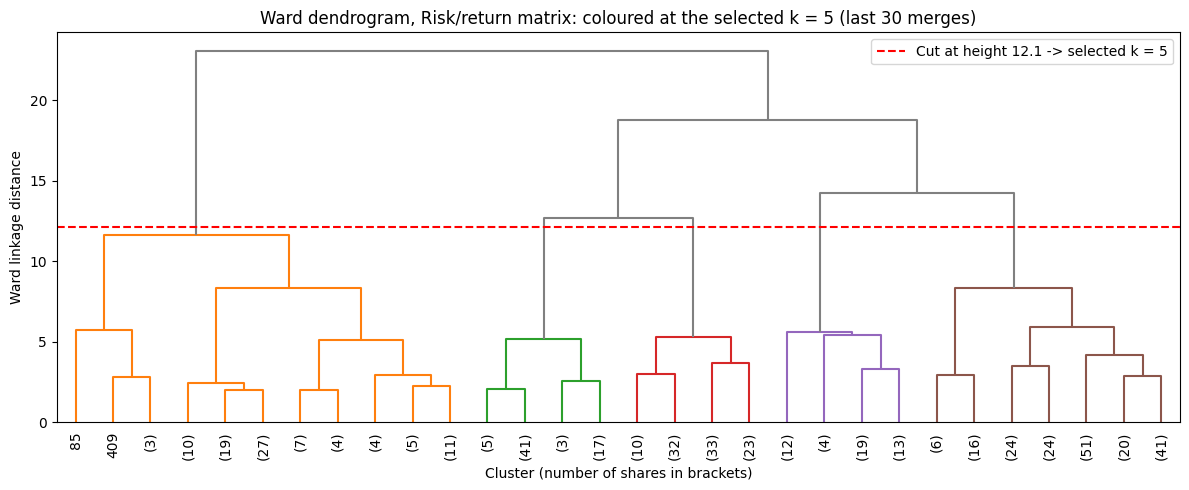

Risk/return: last 10 Ward merges (the merge from 5 to 4 clusters is the one the cut avoids)


,Clusters_before_merge,Clusters_after_merge,Merge_height,Jump_from_previous,Selected_k_kept
0,11,10,5.625,NaN,
1,10,9,5.715,0.090,
2,9,8,5.929,0.214,
3,8,7,8.308,2.379,
4,7,6,8.342,0.033,
5,6,5,11.601,3.260,
6,5,4,12.669,1.068,<- not performed (k kept)
7,4,3,14.210,1.541,
8,3,2,18.803,4.592,
9,2,1,23.073,4.271,


Risk/return: k = 2 -> k = 3 (one cluster splits in two; the others are unchanged)


k=3,1,2,3
k=2,,,
1,230,164,0
2,0,0,92


Risk/return: k = 3 -> k = 4 (one cluster splits in two; the others are unchanged)


k=4,1,2,3,4
k=3,,,,
1,182,0,48,0
2,0,164,0,0
3,0,0,0,92


Risk/return: k = 4 -> k = 5 (one cluster splits in two; the others are unchanged)


k=5,1,2,3,4,5
k=4,,,,,
1,182,0,0,0,0
2,0,66,98,0,0
3,0,0,0,48,0
4,0,0,0,0,92


Risk/return: cluster quality at k = 5 (negative silhouette = closer on average to another cluster)


,Shares,Mean_silhouette,Pct_negative
cluster,,,
1,66,0.465,0.000
2,98,0.382,1.020
3,182,0.274,9.890
4,92,0.164,20.652
5,48,0.306,0.000


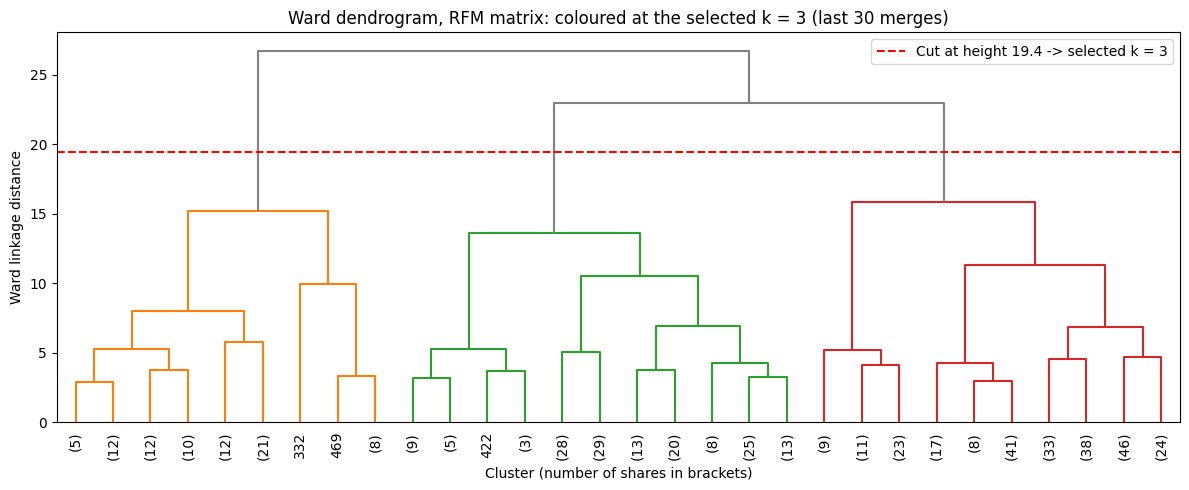

RFM: last 10 Ward merges (the merge from 3 to 2 clusters is the one the cut avoids)


,Clusters_before_merge,Clusters_after_merge,Merge_height,Jump_from_previous,Selected_k_kept
0,11,10,6.935,NaN,
1,10,9,7.973,1.039,
2,9,8,9.968,1.995,
3,8,7,10.537,0.568,
4,7,6,11.293,0.756,
5,6,5,13.580,2.287,
6,5,4,15.152,1.572,
7,4,3,15.843,0.691,
8,3,2,22.985,7.142,<- not performed (k kept)
9,2,1,26.706,3.720,


RFM: k = 2 -> k = 3 (one cluster splits in two; the others are unchanged)


k=3,1,2,3
k=2,,,
1,154,250,0
2,0,0,82


RFM: cluster quality at k = 3 (negative silhouette = closer on average to another cluster)


,Shares,Mean_silhouette,Pct_negative
cluster,,,
1,250,0.378,0.000
2,82,0.184,25.610
3,154,0.247,7.792


Ward summary at the selected k:


,Matrix,Selected_k,Cut_height,Gap_protecting_k,Cophenetic_correlation,Overall_silhouette,Smallest_cluster_pct,ARI_scipy_vs_sklearn
0,Risk/return,5,12.135,1.068,0.479,0.304,9.877,1.0
1,RFM,3,19.414,7.142,0.508,0.304,16.872,1.0


In [54]:
# Ward at the selected k: dendrograms with cut line, merge heights, cophenetic correlation, nesting, cluster quality
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_samples

ward_sets = [('Risk/return', hier_rr, X_rr, WARD_K_RR, 'Ward_RR', 'outputs/dendrogram_risk_return_selected_k.png'),
             ('RFM', hier_rfm, X_rfm, WARD_K_RFM, 'Ward_RFM', 'outputs/dendrogram_rfm_selected_k.png')]
ward_summary = []

for name, Z, X, k, col, fname in ward_sets:
    heights = Z[:, 2]
    cut = (heights[-k] + heights[-(k - 1)]) / 2           # any height in this gap gives exactly k clusters

    # (a) Dendrogram coloured at the selected k
    fig, ax = plt.subplots(figsize=(12, 5))
    dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=cut, above_threshold_color='grey',
               leaf_rotation=90, show_leaf_counts=True, ax=ax)
    ax.axhline(cut, color='red', linestyle='--', label=f'Cut at height {cut:.1f} -> selected k = {k}')
    ax.set(title=f'Ward dendrogram, {name} matrix: coloured at the selected k = {k} (last 30 merges)',
           xlabel='Cluster (number of shares in brackets)', ylabel='Ward linkage distance')
    ax.legend()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

    # (b) Last 10 merges: large jumps mark well-separated groups being forced together
    merges = pd.DataFrame({'Clusters_before_merge': np.arange(11, 1, -1),
                           'Clusters_after_merge': np.arange(10, 0, -1),
                           'Merge_height': heights[-10:]})
    merges['Jump_from_previous'] = merges['Merge_height'].diff()
    merges['Selected_k_kept'] = np.where(merges['Clusters_before_merge'] == k, '<- not performed (k kept)', '')
    merges.round(3).to_csv(f'outputs/ward_last_merges_{col}.csv', index=False)
    print(f'{name}: last 10 Ward merges (the merge from {k} to {k - 1} clusters is the one the cut avoids)')
    display(merges.round(3))

    # (c) Cophenetic correlation: how faithfully the tree preserves the original distances
    coph_corr, _ = cophenet(Z, pdist(X))

    # (d) Nesting: how clusters split as k increases up to the selected k
    for kk in range(2, k):
        a = cut_tree(Z, n_clusters=kk).ravel() + 1
        b = cut_tree(Z, n_clusters=kk + 1).ravel() + 1
        print(f'{name}: k = {kk} -> k = {kk + 1} (one cluster splits in two; the others are unchanged)')
        display(pd.crosstab(pd.Series(a, name=f'k={kk}'), pd.Series(b, name=f'k={kk + 1}')))

    # (e) Cluster quality at the selected k
    sil = silhouette_samples(X, data[col])
    quality = (pd.DataFrame({'cluster': data[col].values, 'silhouette': sil})
               .groupby('cluster')['silhouette']
               .agg(Shares='size', Mean_silhouette='mean', Pct_negative=lambda s: (s < 0).mean() * 100)
               .round(3))
    print(f'{name}: cluster quality at k = {k} (negative silhouette = closer on average to another cluster)')
    display(quality)

    # (f) Reproducibility: scipy cut_tree and sklearn AgglomerativeClustering give the same partition
    sk_labels = AgglomerativeClustering(n_clusters=k, linkage='ward', metric='euclidean').fit_predict(X)
    ari_impl = adjusted_rand_score(sk_labels, data[col])
    assert ari_impl > 0.999, f'scipy and sklearn Ward disagree for {name}'

    ward_summary.append({'Matrix': name, 'Selected_k': k, 'Cut_height': cut,
                         'Gap_protecting_k': heights[-(k - 1)] - heights[-k],
                         'Cophenetic_correlation': coph_corr,
                         'Overall_silhouette': silhouette_score(X, data[col]),
                         'Smallest_cluster_pct': data[col].value_counts().min() / len(data) * 100,
                         'ARI_scipy_vs_sklearn': ari_impl})

ward_summary = pd.DataFrame(ward_summary).round(3)
ward_summary.to_csv('outputs/ward_selected_k_summary.csv', index=False)
print('Ward summary at the selected k:')
display(ward_summary)


**Choosing k for Ward**

Rule (identical for every solution): the **highest average silhouette among k ≥ 3 whose smallest cluster holds at least 5% of shares**, read together with the cluster profiles and dendrogram evidence above.

- **Why not k = 2:** it has the highest silhouette in both matrices, but a two-way split is too coarse to be a useful segmentation of 486 shares.
- **Risk/return, k = 5:** silhouette 0.304, higher than k = 3 (0.274) and k = 4 (0.282). k = 6–8 score slightly higher (0.320–0.324) but only by splitting off a **5-share cluster (1%)** of extreme high-beta, high-return shares, which is an outlier group rather than a segment. The five clusters are interpretable along the risk axis: low-beta shares split into a low-return group and a higher-return group, a market-like group (beta ≈ 1), a high-return/high-beta group and a very high-beta group.
- **RFM, k = 3:** silhouette 0.304, above k = 4 (0.289). k = 5–8 isolate a **10-share cluster (2%)** of shares with no recent event (R ≈ 117, F = 0), again an outlier group driven by raw Recency (see 2.1). The three clusters separate lower-traded-value shares with recent events, high-traded-value shares, and shares whose last event was long ago (R ≈ 58).
- **Why not the dendrogram colours:** scipy colours branches at a default 70% of the maximum height, which is an arbitrary convention that showed 3 groups for both matrices. The cut used here is placed in the merge-height gap that gives the selected k, and the merge table shows how large that gap is compared with neighbouring merges.
- **Caveat:** silhouettes of about 0.3 indicate **moderate, overlapping structure**, not sharply separated groups. The segments are useful summaries, but shares near cluster boundaries (negative silhouettes above) could reasonably belong to a neighbouring segment.


In [55]:
# K-means initialisation check at the selected k:
# (a) how much worse can a single random start be than the N_INIT-start solution?
# (b) do different seeds (each with N_INIT starts) give the same partition as seed 42?
stability = []
for name, X, k, ref in [('RR', X_rr, KMEANS_K_RR, 'KMeans_RR'), ('RFM', X_rfm, KMEANS_K_RFM, 'KMeans_RFM')]:
    base_inertia = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X).inertia_
    single = np.array([KMeans(n_clusters=k, n_init=1, random_state=s).fit(X).inertia_ for s in range(30)])
    aris = [adjusted_rand_score(data[ref], KMeans(n_clusters=k, n_init=N_INIT, random_state=s).fit_predict(X))
            for s in range(N_STABILITY_SEEDS)]
    stability.append({'Solution': ref, 'k': k,
                      f'Inertia_n_init_{N_INIT}': base_inertia,
                      'Single_start_inertia_min': single.min(),
                      'Single_start_inertia_max': single.max(),
                      'Share_single_starts_worse': np.mean(single > base_inertia * 1.0001),
                      'ARI_vs_seed42_min': min(aris),
                      'ARI_vs_seed42_mean': np.mean(aris)})

stability = pd.DataFrame(stability).round(4)
stability.to_csv('outputs/kmeans_stability.csv', index=False)
stability


,Solution,k,Inertia_n_init_50,Single_start_inertia_min,Single_start_inertia_max,Share_single_starts_worse,ARI_vs_seed42_min,ARI_vs_seed42_mean
0,KMeans_RR,5,309.6130,309.8001,364.5082,1.0,0.9104,0.9402
1,KMeans_RFM,4,609.8325,609.8325,790.0793,0.6,0.9939,0.9982


,Matrix,k,Selected,Silhouette,Inertia,Inertia_drop_pct_vs_previous_k,Smallest_cluster_pct,Meets_5pct_size_rule,ARI_across_seeds_mean,ARI_across_seeds_min
0,Risk/return,2,,0.387,621.634,NaN,29.424,yes,1.000,1.000
1,Risk/return,3,,0.329,461.179,25.812,24.486,yes,1.000,1.000
2,Risk/return,4,,0.327,371.577,19.429,8.230,yes,0.996,0.989
3,Risk/return,5,yes,0.341,309.613,16.676,5.556,yes,0.940,0.910
4,Risk/return,6,,0.335,265.097,14.378,1.029,no,0.982,0.871
5,Risk/return,7,,0.328,227.182,14.302,1.029,no,0.896,0.494
6,Risk/return,8,,0.354,194.362,14.447,1.029,no,0.946,0.887
7,RFM,2,,0.423,1066.832,NaN,13.992,yes,1.000,1.000
8,RFM,3,,0.325,796.614,25.329,13.169,yes,1.000,1.000
9,RFM,4,yes,0.341,609.832,23.447,12.551,yes,0.998,0.994


Initialisation: share of 30 single-start runs ending worse than the 50-start solution, and their average excess inertia


,Matrix,k,Single_start_worse_pct_kmeanspp,Single_start_worse_pct_random,Single_start_excess_inertia_pct_kmeanspp,Single_start_excess_inertia_pct_random
0,Risk/return,2,3.333,6.667,0.712,1.425
1,Risk/return,3,10.000,13.333,0.006,0.819
2,Risk/return,4,70.000,90.000,2.815,1.945
3,Risk/return,5,100.000,100.000,3.830,2.789
4,Risk/return,6,100.000,100.000,3.409,3.208
5,Risk/return,7,100.000,100.000,4.276,4.012
6,Risk/return,8,100.000,100.000,6.437,7.921
7,RFM,2,60.000,80.000,3.037,3.183
8,RFM,3,83.333,100.000,4.987,5.593
9,RFM,4,60.000,63.333,5.351,3.005


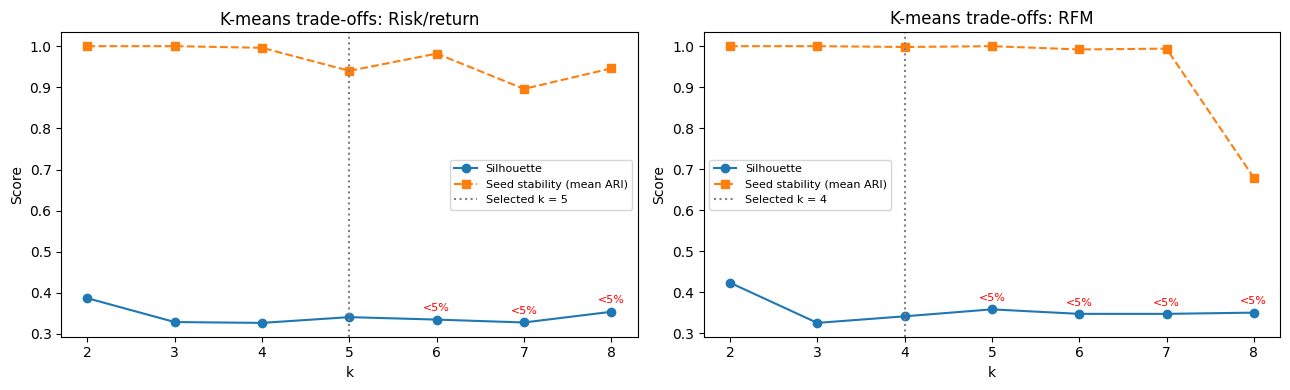

In [56]:
# K-means initialisation, stability and diagnostic trade-offs for every k (both matrices)
from sklearn.metrics import silhouette_samples

km_sets = [('Risk/return', X_rr, kmeans_rr_eval, KMEANS_K_RR), ('RFM', X_rfm, kmeans_rfm_eval, KMEANS_K_RFM)]
trade_rows = []
for name, X, ev, k_sel in km_sets:
    ev_k = ev.set_index('k')
    for k in K_RANGE:
        base = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        aris = [adjusted_rand_score(base.labels_, KMeans(n_clusters=k, n_init=N_INIT, random_state=s).fit_predict(X))
                for s in range(N_STABILITY_SEEDS)]
        single_pp = np.array([KMeans(n_clusters=k, init='k-means++', n_init=1, random_state=s).fit(X).inertia_ for s in range(30)])
        single_rand = np.array([KMeans(n_clusters=k, init='random', n_init=1, random_state=s).fit(X).inertia_ for s in range(30)])
        trade_rows.append({
            'Matrix': name, 'k': k, 'Selected': 'yes' if k == k_sel else '',
            'Inertia': base.inertia_, 'Silhouette': ev_k.loc[k, 'Silhouette'],
            'Smallest_cluster_pct': ev_k.loc[k, 'Smallest_cluster'] / len(X) * 100,
            'ARI_across_seeds_mean': np.mean(aris), 'ARI_across_seeds_min': np.min(aris),
            'Single_start_worse_pct_kmeanspp': np.mean(single_pp > base.inertia_ * 1.0001) * 100,
            'Single_start_worse_pct_random': np.mean(single_rand > base.inertia_ * 1.0001) * 100,
            'Single_start_excess_inertia_pct_kmeanspp': (single_pp.mean() / base.inertia_ - 1) * 100,
            'Single_start_excess_inertia_pct_random': (single_rand.mean() / base.inertia_ - 1) * 100,
        })

tradeoffs = pd.DataFrame(trade_rows)
tradeoffs['Inertia_drop_pct_vs_previous_k'] = tradeoffs.groupby('Matrix')['Inertia'].pct_change().mul(-100)
tradeoffs['Meets_5pct_size_rule'] = np.where(tradeoffs['Smallest_cluster_pct'] >= MIN_CLUSTER_SHARE * 100, 'yes', 'no')
tradeoffs = tradeoffs.round(3)
tradeoffs.to_csv('outputs/kmeans_tradeoffs_all_k.csv', index=False)
display(tradeoffs[['Matrix', 'k', 'Selected', 'Silhouette', 'Inertia', 'Inertia_drop_pct_vs_previous_k',
                   'Smallest_cluster_pct', 'Meets_5pct_size_rule', 'ARI_across_seeds_mean', 'ARI_across_seeds_min']])
print('Initialisation: share of 30 single-start runs ending worse than the 50-start solution, and their average excess inertia')
display(tradeoffs[['Matrix', 'k', 'Single_start_worse_pct_kmeanspp', 'Single_start_worse_pct_random',
                   'Single_start_excess_inertia_pct_kmeanspp', 'Single_start_excess_inertia_pct_random']])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (name, _, _, k_sel) in zip(ax, km_sets):
    t = tradeoffs[tradeoffs['Matrix'] == name]
    a.plot(t['k'], t['Silhouette'], 'o-', label='Silhouette')
    a.plot(t['k'], t['ARI_across_seeds_mean'], 's--', label='Seed stability (mean ARI)')
    a.axvline(k_sel, color='grey', linestyle=':', label=f'Selected k = {k_sel}')
    for _, r in t[t['Meets_5pct_size_rule'] == 'no'].iterrows():
        a.annotate('<5%', (r['k'], r['Silhouette']), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8, color='red')
    a.set(title=f'K-means trade-offs: {name}', xlabel='k', ylabel='Score')
    a.set_xticks(list(K_RANGE))
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/kmeans_tradeoffs.png', dpi=150)
plt.show()


In [57]:
# K-means assumption checks at the selected k: cluster shape/spread, silhouettes, outlier sensitivity
assump_rows, outlier_rows = [], []
for name, X, col, k in [('Risk/return', X_rr, 'KMeans_RR', KMEANS_K_RR), ('RFM', X_rfm, 'KMeans_RFM', KMEANS_K_RFM)]:
    labels = data[col].values
    sil = silhouette_samples(X, labels)
    for c in np.unique(labels):
        pts = X[labels == c]
        feature_sd = pts.std(axis=0)
        assump_rows.append({'Solution': col, 'Cluster': c, 'Shares': len(pts),
                            'RMS_distance_to_centroid': np.sqrt(((pts - pts.mean(axis=0)) ** 2).sum(axis=1).mean()),
                            'Elongation_max_over_min_feature_SD': feature_sd.max() / max(feature_sd.min(), 1e-9),
                            'Mean_silhouette': sil[labels == c].mean(),
                            'Pct_negative_silhouette': (sil[labels == c] < 0).mean() * 100})

    # Outlier sensitivity: refit without shares that have |z| > 3 and compare memberships of the remaining shares
    keep = ~(np.abs(X) > 3).any(axis=1)
    refit = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X[keep])
    outlier_rows.append({'Solution': col, 'k': k, 'Outliers_removed': int((~keep).sum()),
                         'ARI_remaining_shares_with_vs_without_outliers': adjusted_rand_score(labels[keep], refit)})

assumptions = pd.DataFrame(assump_rows).round(3)
assumptions.to_csv('outputs/kmeans_assumption_checks.csv', index=False)
print('Cluster shape and quality at the selected k (elongation >> 1 = stretched along one feature, not spherical):')
display(assumptions)

outlier_sensitivity = pd.DataFrame(outlier_rows).round(3)
outlier_sensitivity.to_csv('outputs/kmeans_outlier_sensitivity.csv', index=False)
print('Outlier sensitivity (ARI = 1: removing outliers does not change how the other shares are grouped):')
display(outlier_sensitivity)


Cluster shape and quality at the selected k (elongation >> 1 = stretched along one feature, not spherical):


,Solution,Cluster,Shares,RMS_distance_to_centroid,Elongation_max_over_min_feature_SD,Mean_silhouette,Pct_negative_silhouette
0,KMeans_RR,1,131,0.635,1.371,0.398,0.000
1,KMeans_RR,2,166,0.700,1.123,0.323,2.410
2,KMeans_RR,3,112,0.719,1.208,0.344,2.679
3,KMeans_RR,4,27,1.626,1.418,0.241,14.815
4,KMeans_RR,5,50,0.962,1.220,0.292,0.000
5,KMeans_RFM,1,122,0.943,1.643,0.384,0.000
6,KMeans_RFM,2,212,0.858,1.892,0.374,0.000
7,KMeans_RFM,3,61,1.826,1.678,0.263,11.475
8,KMeans_RFM,4,91,1.248,2.112,0.260,3.297


Outlier sensitivity (ARI = 1: removing outliers does not change how the other shares are grouped):


,Solution,k,Outliers_removed,ARI_remaining_shares_with_vs_without_outliers
0,KMeans_RR,5,7,0.799
1,KMeans_RFM,4,22,0.737


**Choosing k for K-means and the diagnostic trade-offs**

The same rule as Ward is used: the **highest silhouette among k ≥ 3 whose smallest cluster holds at least 5% of shares**, checked against inertia, stability and profiles.

- **Risk/return, k = 5:** silhouette 0.341, above k = 3 (0.329), 4 (0.327), 6 (0.335) and 7 (0.328). k = 8 scores higher (0.354), but only by creating a **5-share cluster (1%)**, as do k = 6 and 7.
- **RFM, k = 4:** silhouette 0.341, above k = 3 (0.325). k = 5 scores higher (0.358) but contains an **11-share cluster (2.3%)**, and k = 7–8 contain a **single-share cluster**. These are outlier groups, mostly driven by raw Recency (2.1).
- **k = 2** has the highest silhouette for both matrices but is too coarse to be a useful segmentation.
- **Elbow:** inertia falls smoothly, with no sharp bend (see the % drop per extra cluster). The elbow alone cannot identify k, which is why silhouette, cluster sizes and profiles are used together.
- **Stability trade-off:** the selected solutions are **not the most stable**. In the risk/return matrix, the k = 5 solution changes slightly with the seed (mean ARI across seeds below 1), and a single random start almost never reaches the best inertia. Smaller k values are more stable but less informative. With `n_init=50` the chosen solution is reproducible for a fixed seed, but its boundary shares are sensitive.
- **Initialisation:** a single start rarely finds the best solution at the selected k: every one of 30 single k-means++ starts ended worse in the risk/return matrix, and most did in the RFM matrix. k-means++ was not consistently better than random seeding (lower excess inertia at some k, higher at others), so the protection comes from **many restarts (`n_init=50`) with a fixed seed**, not from the seeding method alone.
- **Assumptions:** elongation ratios well above 1 and negative silhouettes show that some clusters are **not compact spheres**. K-means draws straight boundaries through continuous clouds of shares, so the segments are partitions of a continuum rather than naturally separated groups. The outlier test shows how far extreme shares pull the centroids.
- **Compared with Ward:** the same k for risk/return (5) and one more cluster for RFM (4 vs 3). K-means achieves lower inertia and higher silhouette at every k, as expected, because it optimises the objective directly instead of merging greedily.


# **2.4 Cluster Profiles and Algorithm Comparison**

In [58]:
data['Monetary_USD_bn'] = data['Monetary'] / 1e9


def cluster_profile(cluster_col):
    """Cluster profile in original units (means and medians, return in % per week, M in USD bn)."""
    g = data.groupby(cluster_col)
    profile = pd.DataFrame({
        'Count': g.size(),
        'Share_pct': g.size() / len(data) * 100,
        'Return_mean_pct_wk': g['Mean_Weekly_Return'].mean() * 100,
        'Return_median_pct_wk': g['Mean_Weekly_Return'].median() * 100,
        'Beta_mean': g['Beta'].mean(),
        'Beta_median': g['Beta'].median(),
        'Recency_mean': g['Recency'].mean(),
        'Recency_median': g['Recency'].median(),
        'Frequency_mean': g['Frequency'].mean(),
        'Frequency_median': g['Frequency'].median(),
        'Monetary_median_bn': g['Monetary_USD_bn'].median(),
        'Monetary_mean_bn': g['Monetary_USD_bn'].mean(),
    })
    return profile.round(3)


for col in ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']:
    print(f'=== {col} profile (original units) ===')
    profile = cluster_profile(col)
    profile.to_csv(f'outputs/profile_{col}.csv')
    display(profile)


=== Ward_RR profile (original units) ===


,Count,Share_pct,Return_mean_pct_wk,Return_median_pct_wk,Beta_mean,Beta_median,Recency_mean,Recency_median,Frequency_mean,Frequency_median,Monetary_median_bn,Monetary_mean_bn
Ward_RR,,,,,,,,,,,,
1,66,13.580,0.088,0.113,0.439,0.448,26.197,11.0,2.894,3.0,17.701,25.888
2,98,20.165,0.422,0.392,0.710,0.666,16.908,11.0,2.704,3.0,17.649,24.691
3,182,37.449,0.132,0.166,0.973,0.964,17.714,11.0,3.011,3.0,12.985,19.788
4,92,18.930,0.632,0.550,1.298,1.218,23.674,11.0,3.196,3.0,24.184,78.781
5,48,9.877,0.200,0.252,1.628,1.514,23.542,11.0,3.229,3.0,28.698,86.935


=== KMeans_RR profile (original units) ===


,Count,Share_pct,Return_mean_pct_wk,Return_median_pct_wk,Beta_mean,Beta_median,Recency_mean,Recency_median,Frequency_mean,Frequency_median,Monetary_median_bn,Monetary_mean_bn
KMeans_RR,,,,,,,,,,,,
1,131,26.955,0.206,0.203,0.533,0.530,21.794,11.0,2.977,3.0,15.044,23.689
2,166,34.156,0.427,0.415,0.996,0.996,16.813,11.0,2.892,3.0,17.720,36.678
3,112,23.045,0.034,0.075,1.020,1.032,19.786,11.0,3.018,3.0,13.503,19.459
4,27,5.556,0.928,0.831,1.559,1.450,30.889,11.0,3.222,3.0,28.211,122.309
5,50,10.288,0.241,0.267,1.632,1.543,24.440,11.0,3.160,3.0,32.148,89.539


=== Ward_RFM profile (original units) ===


,Count,Share_pct,Return_mean_pct_wk,Return_median_pct_wk,Beta_mean,Beta_median,Recency_mean,Recency_median,Frequency_mean,Frequency_median,Monetary_median_bn,Monetary_mean_bn
Ward_RFM,,,,,,,,,,,,
1,250,51.440,0.253,0.249,0.940,0.927,12.120,11.0,3.360,3.0,11.178,11.764
2,82,16.872,0.286,0.244,1.009,1.047,58.305,54.5,2.098,2.0,17.849,47.159
3,154,31.687,0.338,0.325,1.010,0.989,13.682,11.0,2.864,3.0,39.695,80.145


=== KMeans_RFM profile (original units) ===


,Count,Share_pct,Return_mean_pct_wk,Return_median_pct_wk,Beta_mean,Beta_median,Recency_mean,Recency_median,Frequency_mean,Frequency_median,Monetary_median_bn,Monetary_mean_bn
KMeans_RFM,,,,,,,,,,,,
1,122,25.103,0.257,0.253,0.966,0.922,13.943,11.0,4.549,4.0,12.826,15.015
2,212,43.621,0.275,0.259,0.939,0.931,13.264,11.0,2.368,2.0,13.336,15.175
3,61,12.551,0.300,0.253,0.975,1.051,66.016,55.0,1.672,2.0,21.242,56.180
4,91,18.724,0.341,0.295,1.064,1.048,15.143,11.0,3.231,3.0,60.183,117.301


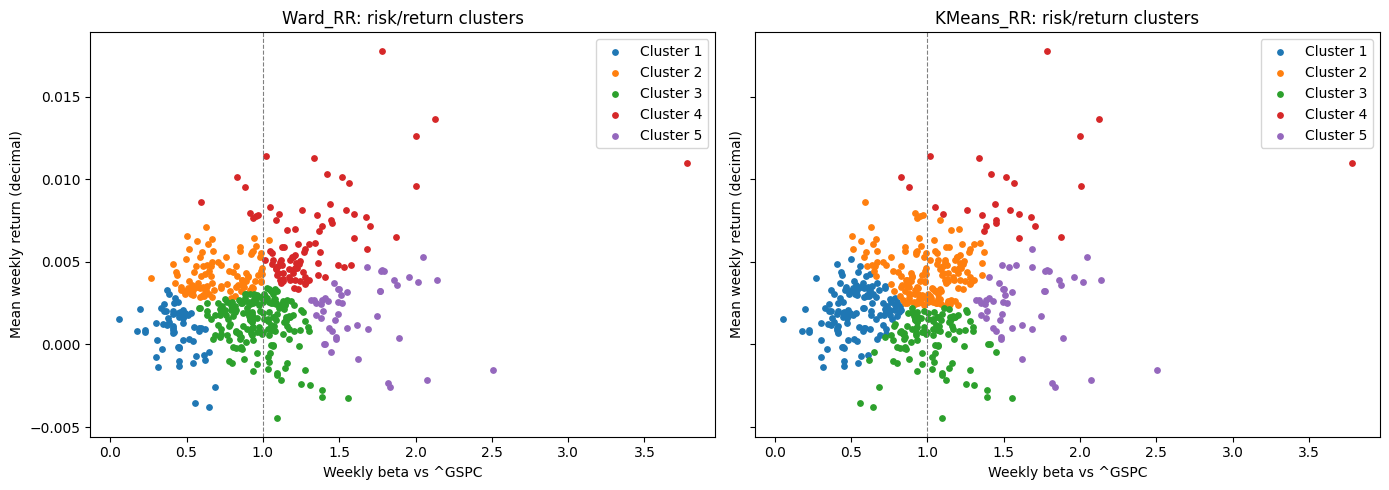

In [59]:
# Risk/return clusters in original units (Tutorial 03 scatter style)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, ['Ward_RR', 'KMeans_RR']):
    for cluster, group in data.groupby(col):
        ax.scatter(group['Beta'], group['Mean_Weekly_Return'], s=15, label=f'Cluster {cluster}')
    ax.axvline(1, color='grey', linestyle='--', linewidth=0.8)
    ax.set_xlabel('Weekly beta vs ^GSPC')
    ax.set_ylabel('Mean weekly return (decimal)')
    ax.set_title(f'{col}: risk/return clusters')
    ax.legend()
plt.tight_layout()
plt.savefig('outputs/clusters_risk_return.png', dpi=150)
plt.show()

Explained variance ratio: [0.458 0.336] | total: 0.794
Loadings (how each standardised feature contributes to each axis):


,Recency,Frequency,Log_Monetary
PC1,0.711,-0.650,0.268
PC2,0.023,0.402,0.915


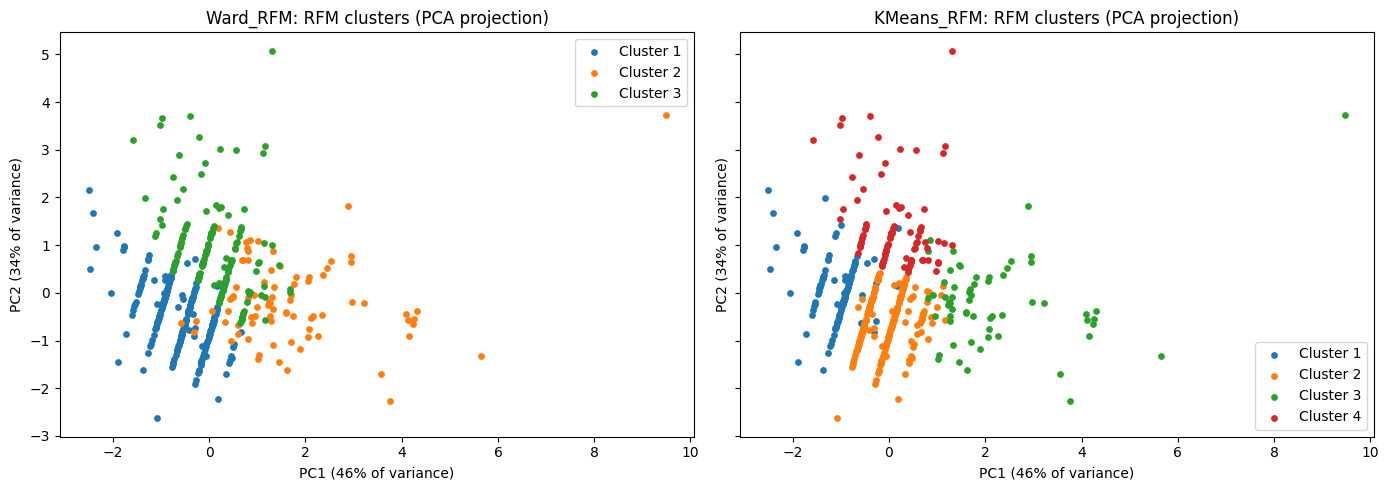

In [60]:
# RFM clusters on 2 principal components
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_rfm)
data['PC1'], data['PC2'] = pcs[:, 0], pcs[:, 1]

print('Explained variance ratio:', pca.explained_variance_ratio_.round(3),
      '| total:', pca.explained_variance_ratio_.sum().round(3))
print('Loadings (how each standardised feature contributes to each axis):')
display(pd.DataFrame(pca.components_, columns=rfm_features, index=['PC1', 'PC2']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, ['Ward_RFM', 'KMeans_RFM']):
    for cluster, group in data.groupby(col):
        ax.scatter(group['PC1'], group['PC2'], s=15, label=f'Cluster {cluster}')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)')
    ax.set_title(f'{col}: RFM clusters (PCA projection)')
    ax.legend()
plt.tight_layout()
plt.savefig('outputs/clusters_rfm_pca.png', dpi=150)
plt.show()

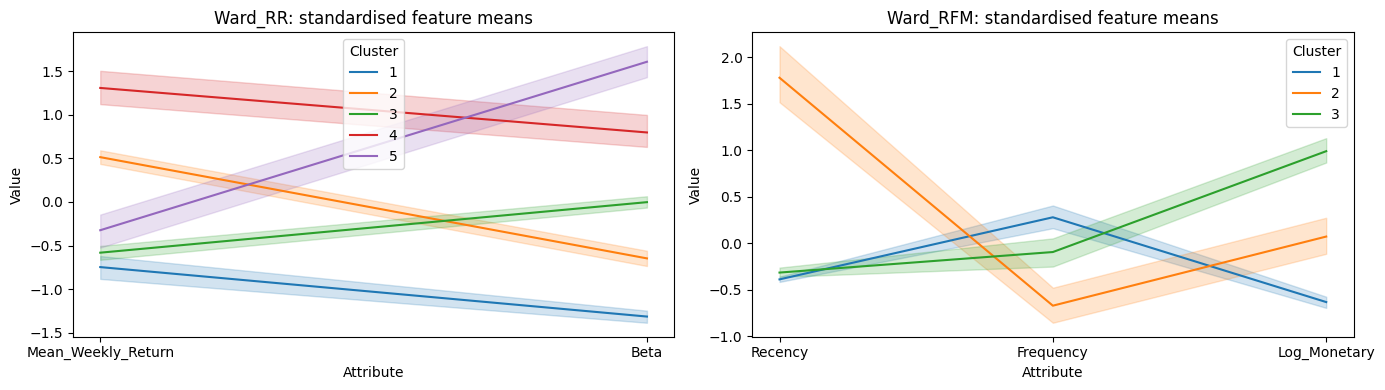

In [61]:
# Standardised profile ("snake") plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (col, X, feats) in zip(axes, [('Ward_RR', X_rr, rr_features), ('Ward_RFM', X_rfm, rfm_features)]):
    df_norm = pd.DataFrame(X, columns=feats)
    df_norm['Cluster'] = data[col].values
    df_melt = df_norm.melt(id_vars='Cluster', var_name='Attribute', value_name='Value')
    sns.lineplot(x='Attribute', y='Value', hue='Cluster', data=df_melt, ax=ax, palette='tab10')
    ax.set_title(f'{col}: standardised feature means')
plt.tight_layout()
plt.savefig('outputs/snake_plots.png', dpi=150)
plt.show()

=== Ward_RR vs KMeans_RR | ARI = 0.318 ===


KMeans_RR,1,2,3,4,5
Ward_RR,,,,,
1,61,0,5,0,0
2,41,57,0,0,0
3,29,49,104,0,0
4,0,60,0,27,5
5,0,0,3,0,45


=== Ward_RFM vs KMeans_RFM | ARI = 0.318 ===


KMeans_RFM,1,2,3,4
Ward_RFM,,,,
1,104,146,0,0
2,4,14,57,7
3,14,52,4,84


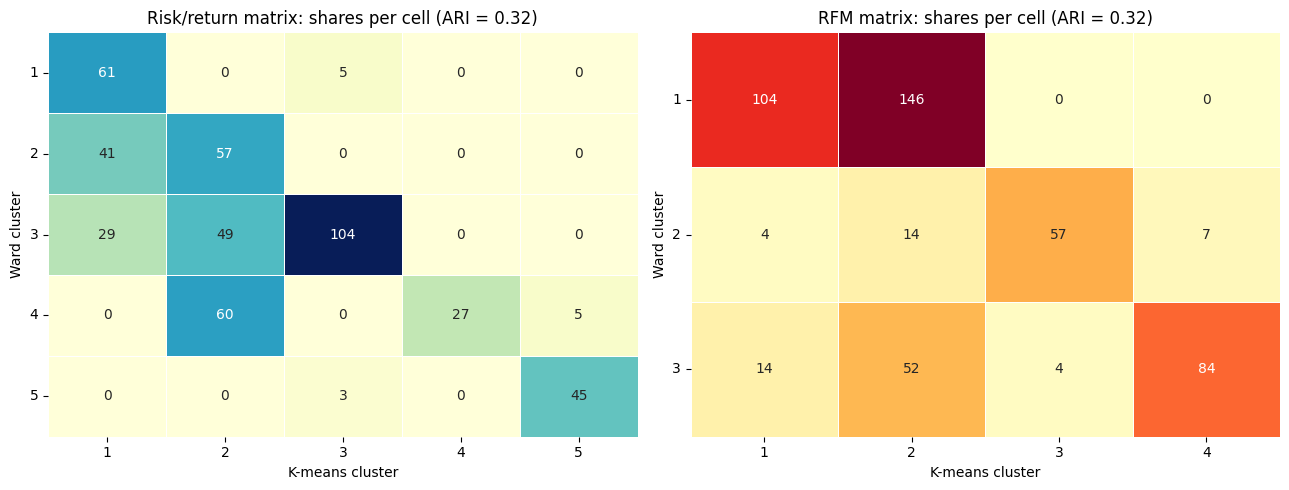

In [62]:
# Algorithm comparison on the same shares: cross-tabulation + adjusted Rand index
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (matrix, a, b, cmap) in zip(axes, [('Risk/return matrix', 'Ward_RR', 'KMeans_RR', 'YlGnBu'),
                                           ('RFM matrix', 'Ward_RFM', 'KMeans_RFM', 'YlOrRd')]):
    ari = adjusted_rand_score(data[a], data[b])
    ct = pd.crosstab(data[a], data[b])
    print(f'=== {a} vs {b} | ARI = {ari:.3f} ===')
    display(ct)

    # Heatmap of shares per cell (same numbers as the table above)
    sns.heatmap(ct, annot=True, fmt='d', cmap=cmap, cbar=False, linewidths=0.5, linecolor='white',
                annot_kws={'fontsize': 10}, ax=ax)
    ax.set_title(f'{matrix}: shares per cell (ARI = {ari:.2f})')
    ax.set_xlabel('K-means cluster')
    ax.set_ylabel('Ward cluster')
    ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig('outputs/ward_vs_kmeans_crosstab_heatmaps.png', dpi=150)
plt.show()

**Descriptive segment names**

Cluster numbers are arbitrary: an algorithm's "cluster 3" means nothing by itself. Here they are only ordered (cluster 1 = lowest mean beta for risk/return, lowest mean log1p(M) for RFM) so that tables are readable. To make the segments interpretable, each cluster gets a name generated **from its own profile** with fixed, stated rules:

- **Risk/return:** beta band from the cluster mean (Low < 0.8 ≤ Market ≤ 1.2 < High), and return band from the cluster mean relative to the terciles of all shares' mean weekly returns (low / mid / high).
- **RFM:** "Stale" if the cluster's median Recency is above 30 days. Otherwise "Recent", plus "frequent" / "infrequent" if mean F is well above / below the overall mean (+0.75 / −0.5 event days), plus a value band from median M relative to the overall median (high ≥ 1.5×, low ≤ 0.85×, otherwise mid).

The names are a summary aid. The profiles in original units remain the evidence.


In [63]:
# Descriptive segment names generated from each cluster's profile
ret_q33, ret_q67 = data['Mean_Weekly_Return'].quantile([1 / 3, 2 / 3])
overall_F = data['Frequency'].mean()
overall_M_median = data['Monetary_USD_bn'].median()


def name_rr(g):
    b, r = g['Beta'].mean(), g['Mean_Weekly_Return'].mean()
    beta_band = 'Low beta' if b < 0.8 else ('High beta' if b > 1.2 else 'Market beta')
    ret_band = 'low return' if r < ret_q33 else ('high return' if r > ret_q67 else 'mid return')
    return f'{beta_band}, {ret_band}'


def name_rfm(g):
    r, f, m = g['Recency'].median(), g['Frequency'].mean(), g['Monetary_USD_bn'].median()
    if r > 30:
        return f'Stale (median R {r:.0f} days)'
    parts = ['Recent']
    if f >= overall_F + 0.75:
        parts.append('frequent')
    elif f <= overall_F - 0.5:
        parts.append('infrequent')
    parts.append('high value' if m >= 1.5 * overall_M_median else ('low value' if m <= 0.85 * overall_M_median else 'mid value'))
    return ', '.join(parts)


segment_names = {}
for col, namer in [('Ward_RR', name_rr), ('KMeans_RR', name_rr), ('Ward_RFM', name_rfm), ('KMeans_RFM', name_rfm)]:
    segment_names[col] = {c: f'C{c}: {namer(g)}' for c, g in data.groupby(col)}
    data[f'{col}_Segment'] = data[col].map(segment_names[col])
    named = cluster_profile(col)
    named.insert(0, 'Segment', named.index.map(segment_names[col]))
    named.to_csv(f'outputs/profile_named_{col}.csv')
    print(f'=== {col} ===')
    display(named[['Segment', 'Count', 'Share_pct', 'Return_mean_pct_wk', 'Beta_mean', 'Recency_median',
                   'Frequency_mean', 'Monetary_median_bn']])


=== Ward_RR ===


,Segment,Count,Share_pct,Return_mean_pct_wk,Beta_mean,Recency_median,Frequency_mean,Monetary_median_bn
Ward_RR,,,,,,,,
1,"C1: Low beta, low return",66,13.580,0.088,0.439,11.0,2.894,17.701
2,"C2: Low beta, high return",98,20.165,0.422,0.710,11.0,2.704,17.649
3,"C3: Market beta, low return",182,37.449,0.132,0.973,11.0,3.011,12.985
4,"C4: High beta, high return",92,18.930,0.632,1.298,11.0,3.196,24.184
5,"C5: High beta, mid return",48,9.877,0.200,1.628,11.0,3.229,28.698


=== KMeans_RR ===


,Segment,Count,Share_pct,Return_mean_pct_wk,Beta_mean,Recency_median,Frequency_mean,Monetary_median_bn
KMeans_RR,,,,,,,,
1,"C1: Low beta, mid return",131,26.955,0.206,0.533,11.0,2.977,15.044
2,"C2: Market beta, high return",166,34.156,0.427,0.996,11.0,2.892,17.720
3,"C3: Market beta, low return",112,23.045,0.034,1.020,11.0,3.018,13.503
4,"C4: High beta, high return",27,5.556,0.928,1.559,11.0,3.222,28.211
5,"C5: High beta, mid return",50,10.288,0.241,1.632,11.0,3.160,32.148


=== Ward_RFM ===


,Segment,Count,Share_pct,Return_mean_pct_wk,Beta_mean,Recency_median,Frequency_mean,Monetary_median_bn
Ward_RFM,,,,,,,,
1,"C1: Recent, low value",250,51.440,0.253,0.940,11.0,3.360,11.178
2,C2: Stale (median R 54 days),82,16.872,0.286,1.009,54.5,2.098,17.849
3,"C3: Recent, high value",154,31.687,0.338,1.010,11.0,2.864,39.695


=== KMeans_RFM ===


,Segment,Count,Share_pct,Return_mean_pct_wk,Beta_mean,Recency_median,Frequency_mean,Monetary_median_bn
KMeans_RFM,,,,,,,,
1,"C1: Recent, frequent, low value",122,25.103,0.257,0.966,11.0,4.549,12.826
2,"C2: Recent, infrequent, low value",212,43.621,0.275,0.939,11.0,2.368,13.336
3,C3: Stale (median R 55 days),61,12.551,0.300,0.975,55.0,1.672,21.242
4,"C4: Recent, high value",91,18.724,0.341,1.064,11.0,3.231,60.183


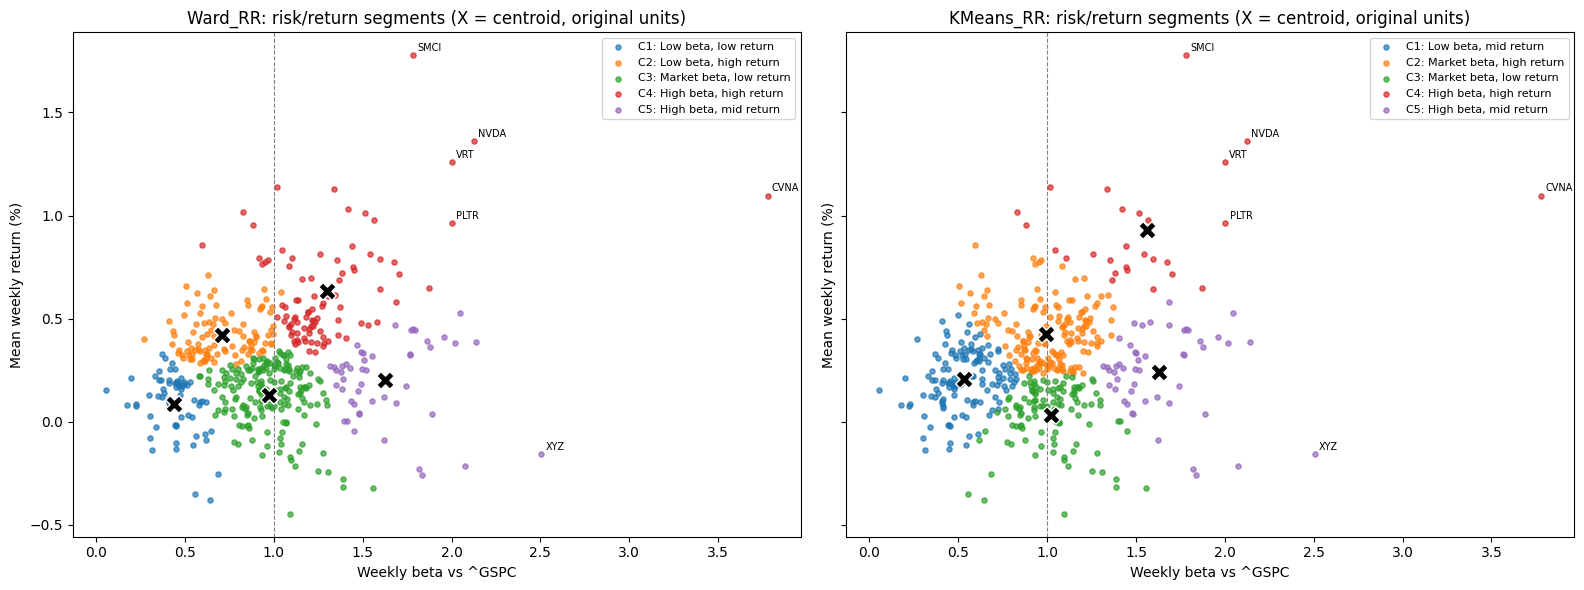

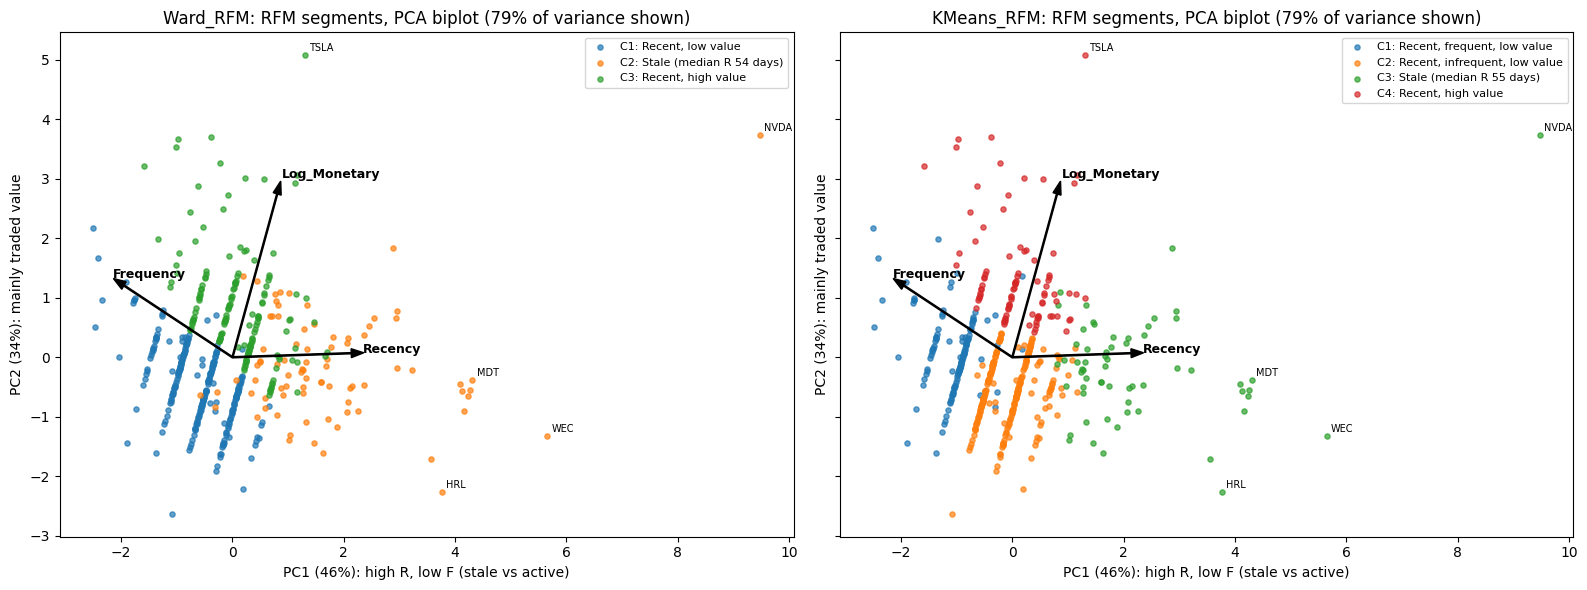

The diagonal stripes are an artefact of Frequency being a whole number (0-8): each stripe is one F value.


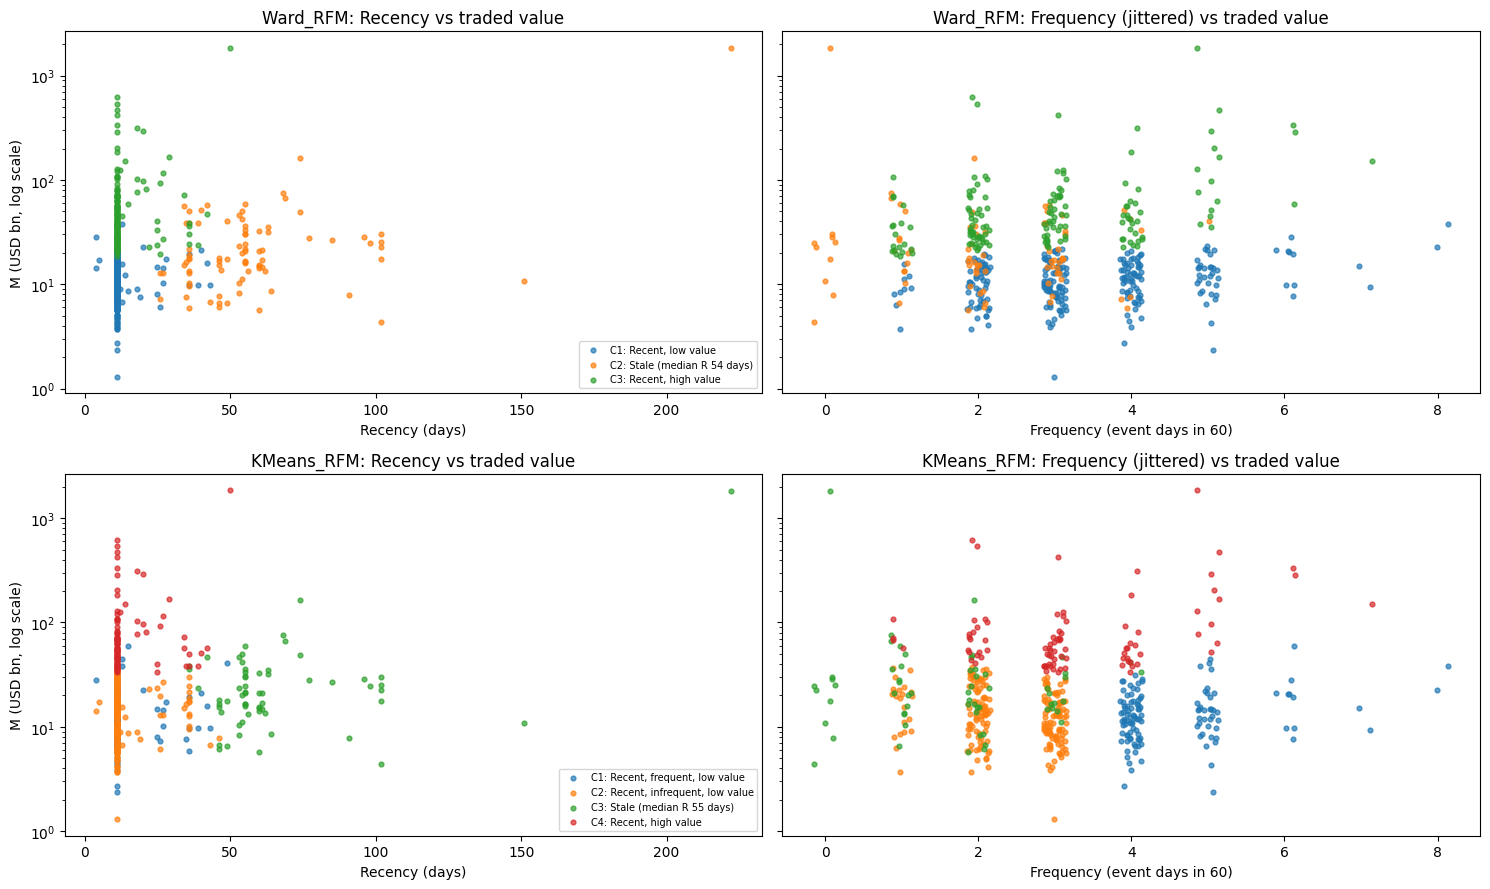

In [64]:
# Labelled visuals: risk/return in original units (no projection), RFM PCA biplot, and RFM without projection
def extreme_points(X, n):
    """Indices of the n shares farthest from the centre of the standardised feature space."""
    return np.argsort(np.sqrt((np.asarray(X) ** 2).sum(axis=1)))[-n:]


# (1) Risk/return: both features plotted directly, so no dimensionality reduction is needed
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
rr_extremes = extreme_points(X_rr, 6)
for ax, col in zip(axes, ['Ward_RR', 'KMeans_RR']):
    for c, g in data.groupby(col):
        ax.scatter(g['Beta'], g['Mean_Weekly_Return'] * 100, s=14, alpha=0.7, label=segment_names[col][c])
        ax.scatter(g['Beta'].mean(), g['Mean_Weekly_Return'].mean() * 100, marker='X', s=160,
                   color='black', edgecolor='white', zorder=5)
    for i in rr_extremes:
        ax.annotate(data.index[i], (data['Beta'].iloc[i], data['Mean_Weekly_Return'].iloc[i] * 100),
                    fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.axvline(1, color='grey', linestyle='--', linewidth=0.8)
    ax.set(title=f'{col}: risk/return segments (X = centroid, original units)',
           xlabel='Weekly beta vs ^GSPC', ylabel='Mean weekly return (%)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/clusters_risk_return_named.png', dpi=150)
plt.show()

# (2) RFM: 3 features -> PCA biplot (points + loading arrows)
loadings = pd.DataFrame(pca.components_.T, index=rfm_features, columns=['PC1', 'PC2'])
rfm_extremes = extreme_points(X_rfm, 5)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
for ax, col in zip(axes, ['Ward_RFM', 'KMeans_RFM']):
    for c, g in data.groupby(col):
        ax.scatter(g['PC1'], g['PC2'], s=14, alpha=0.7, label=segment_names[col][c])
    for feat, (lx, ly) in loadings.iterrows():
        ax.arrow(0, 0, lx * 3, ly * 3, color='black', width=0.02, head_width=0.15)
        ax.text(lx * 3.3, ly * 3.3, feat, fontsize=9, fontweight='bold')
    for i in rfm_extremes:
        ax.annotate(data.index[i], (data['PC1'].iloc[i], data['PC2'].iloc[i]), fontsize=7,
                    xytext=(3, 3), textcoords='offset points')
    ax.set(title=f'{col}: RFM segments, PCA biplot ({pca.explained_variance_ratio_.sum():.0%} of variance shown)',
           xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%}): high R, low F (stale vs active)',
           ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%}): mainly traded value')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/clusters_rfm_biplot.png', dpi=150)
plt.show()
print('The diagonal stripes are an artefact of Frequency being a whole number (0-8): each stripe is one F value.')

# (3) RFM without projection: original features, so nothing is hidden by PCA
rng_jitter = np.random.default_rng(SEED)
f_jitter = data['Frequency'] + rng_jitter.uniform(-0.15, 0.15, len(data))     # jitter only for visibility
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=True)
for row, col in enumerate(['Ward_RFM', 'KMeans_RFM']):
    for c, g in data.groupby(col):
        axes[row, 0].scatter(g['Recency'], g['Monetary_USD_bn'], s=12, alpha=0.7, label=segment_names[col][c])
        axes[row, 1].scatter(f_jitter[g.index], g['Monetary_USD_bn'], s=12, alpha=0.7, label=segment_names[col][c])
    axes[row, 0].set(title=f'{col}: Recency vs traded value', xlabel='Recency (days)', ylabel='M (USD bn, log scale)', yscale='log')
    axes[row, 1].set(title=f'{col}: Frequency (jittered) vs traded value', xlabel='Frequency (event days in 60)', yscale='log')
    axes[row, 0].legend(fontsize=7)
plt.tight_layout()
plt.savefig('outputs/clusters_rfm_original_features.png', dpi=150)
plt.show()


Risk/return: matched pairs (Ward -> K-means):
   C1: Low beta, low return                      -> C1: Low beta, mid return                        61 shares (92% of the Ward cluster)
   C2: Low beta, high return                     -> C2: Market beta, high return                    57 shares (58% of the Ward cluster)
   C3: Market beta, low return                   -> C3: Market beta, low return                    104 shares (57% of the Ward cluster)
   C4: High beta, high return                    -> C4: High beta, high return                      27 shares (29% of the Ward cluster)
   C5: High beta, mid return                     -> C5: High beta, mid return                       45 shares (94% of the Ward cluster)
RFM: matched pairs (Ward -> K-means):
   C1: Recent, low value                         -> C2: Recent, infrequent, low value              146 shares (58% of the Ward cluster)
   C2: Stale (median R 54 days)                  -> C3: Stale (median R 55 days)                    

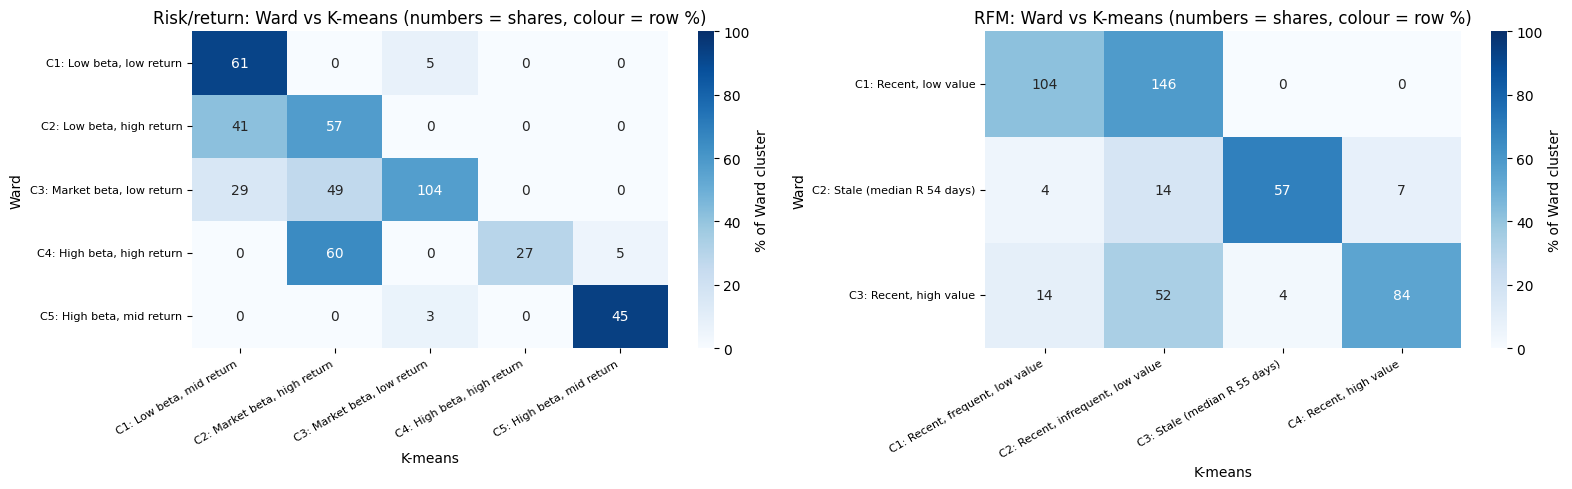

Agreement summary (ARI/AMI: 0 = chance, 1 = identical; matched agreement = shares in best-matched cluster pairs):


,Matrix,k_Ward,k_KMeans,ARI,AMI,Matched_agreement_pct,Core_shares,Boundary_shares,Silhouette_Ward,Silhouette_KMeans
0,Risk/return,5,5,0.318,0.497,60.494,294,192,0.304,0.341
1,RFM,3,4,0.318,0.398,59.053,287,199,0.304,0.341


In [65]:
# Matched agreement between Ward and K-means on the same 486 shares
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_mutual_info_score

agree_rows = []
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (matrix, a, b, Xm) in zip(axes, [('Risk/return', 'Ward_RR', 'KMeans_RR', X_rr), ('RFM', 'Ward_RFM', 'KMeans_RFM', X_rfm)]):
    ct = pd.crosstab(data[a], data[b])
    r_idx, c_idx = linear_sum_assignment(-ct.values)          # best one-to-one matching of clusters
    pairs = list(zip(ct.index[r_idx], ct.columns[c_idx]))
    core = pd.Series(False, index=data.index)
    for wc, kc in pairs:
        core |= (data[a] == wc) & (data[b] == kc)
    data[f'Core_{matrix.replace("/", "_")}'] = core
    agree_rows.append({'Matrix': matrix, 'k_Ward': ct.shape[0], 'k_KMeans': ct.shape[1],
                       'ARI': adjusted_rand_score(data[a], data[b]),
                       'AMI': adjusted_mutual_info_score(data[a], data[b]),
                       'Matched_agreement_pct': core.mean() * 100,
                       'Core_shares': int(core.sum()), 'Boundary_shares': int((~core).sum()),
                       'Silhouette_Ward': silhouette_score(Xm, data[a]),
                       'Silhouette_KMeans': silhouette_score(Xm, data[b])})
    print(f'{matrix}: matched pairs (Ward -> K-means):')
    for wc, kc in pairs:
        n = ct.loc[wc, kc]
        print(f'   {segment_names[a][wc]:<45} -> {segment_names[b][kc]:<45} {n:>4} shares '
              f'({n / ct.loc[wc].sum():.0%} of the Ward cluster)')

    row_pct = ct.div(ct.sum(axis=1), axis=0) * 100
    sns.heatmap(row_pct, annot=ct.values, fmt='d', cmap='Blues', vmin=0, vmax=100, ax=ax,
                cbar_kws={'label': '% of Ward cluster'})
    ax.set_yticklabels([segment_names[a][c] for c in ct.index], rotation=0, fontsize=8)
    ax.set_xticklabels([segment_names[b][c] for c in ct.columns], rotation=30, ha='right', fontsize=8)
    ax.set(title=f'{matrix}: Ward vs K-means (numbers = shares, colour = row %)', xlabel='K-means', ylabel='Ward')
plt.tight_layout()
plt.savefig('outputs/ward_vs_kmeans_matched.png', dpi=150)
plt.show()

agreement_summary = pd.DataFrame(agree_rows).round(3)
agreement_summary.to_csv('outputs/ward_vs_kmeans_agreement.csv', index=False)
print('Agreement summary (ARI/AMI: 0 = chance, 1 = identical; matched agreement = shares in best-matched cluster pairs):')
display(agreement_summary)


**Synthesis: agreement, differences and interpretability**

- **How much do the algorithms agree?** Only moderately. ARI is about 0.32 for both matrices, and the matched-agreement table shows the share of stocks placed in corresponding segments. Both algorithms have similar, modest silhouettes (about 0.30–0.34), so the data does not contain sharply separated groups. Each algorithm draws its own boundaries through a **continuous cloud** of shares, and the boundary shares are the ones that switch.
- **Risk/return:** both find the same broad structure (a defensive low-beta group, a market-beta group, and high-beta groups), but they cut it differently. Ward splits mainly along **beta**, while K-means splits more along **return**. For example, most of Ward's high-beta/high-return group falls into a K-means market-beta/high-return segment. The core shares agree, and the disagreement is concentrated near the boundaries visible in the scatter.
- **RFM:** both separate a **stale** segment (last event weeks ago) and a **high traded-value** segment. The main difference is that K-means splits Ward's large recent/low-value group into **frequent** and **infrequent** sub-groups, which is why its selected k is one higher.
- **Interpretability:** risk/return segments are easiest to read because they are plotted in original units. RFM segments are interpretable through their profiles and the original-feature plots, but they mostly separate *when* the last event happened and *how much* is traded, not risk.

**Limitations of the visuals and labels**

- **Projection:** the RFM plot is a 2D PCA projection keeping about 79% of the variance. Distances and overlaps in 2D are distorted, so two segments that overlap in the plot can still be separated along the hidden third component. The no-projection plots of the original features are included for that reason. The diagonal stripes are an artefact of Frequency being a whole number, not real structure.
- **Arbitrary labels:** cluster numbers carry no meaning. They are ordered here by beta or traded value only for readability, colours in different plots do not correspond to each other, and ARI/AMI ignore labels entirely. The segment names are generated by stated rules from the profiles, so they are a convenience, not a finding.


# **2.5 RFM Sensitivity and Correlated Inputs**

**2.5.1 Correlation Analysis**

Pearson correlations among the clustering inputs:


,Recency,Frequency,Log_Monetary
Recency,1.000,-0.346,0.152
Frequency,-0.346,1.000,0.013
Log_Monetary,0.152,0.013,1.000


Spearman (rank) correlations, less affected by the skew in Recency:


,Recency,Frequency,Log_Monetary
Recency,1.000,-0.196,0.137
Frequency,-0.196,1.000,-0.048
Log_Monetary,0.137,-0.048,1.000


Share of variance on PC1 of (R, F, log1p M): 45.79% | eigenvalues: [1.374 1.009 0.617]


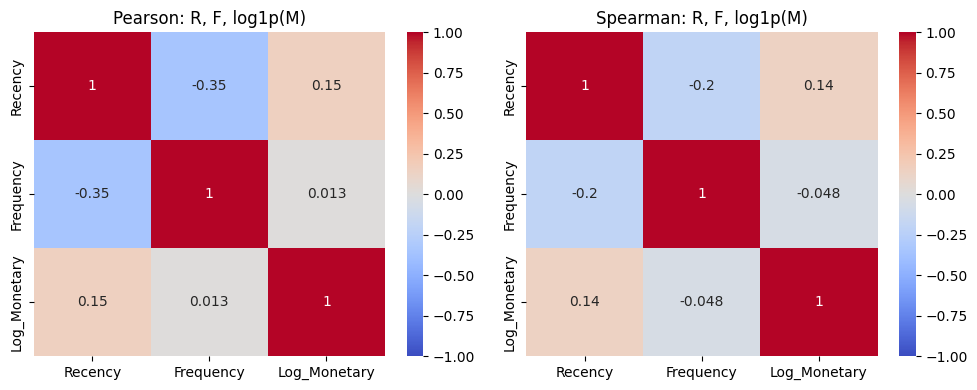

In [66]:
rfm_inputs = data[['Recency', 'Frequency', 'Log_Monetary']]
rfm_corr = rfm_inputs.corr(method='pearson').round(3)
rfm_spearman = rfm_inputs.corr(method='spearman').round(3)

print('Pearson correlations among the clustering inputs:')
display(rfm_corr)
print('Spearman (rank) correlations, less affected by the skew in Recency:')
display(rfm_spearman)
rfm_corr.to_csv('outputs/rfm_correlations.csv')
rfm_spearman.to_csv('outputs/rfm_correlations_spearman.csv')

# How much of the total standardised variance lies along one shared direction?
eigenvalues = np.sort(np.linalg.eigvalsh(rfm_inputs.corr().values))[::-1]
print(f'Share of variance on PC1 of (R, F, log1p M): {eigenvalues[0] / eigenvalues.sum():.2%}'
      f' | eigenvalues: {eigenvalues.round(3)}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, matrix) in zip(axes, [('Pearson', rfm_corr), ('Spearman', rfm_spearman)]):
    sns.heatmap(matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'{name}: R, F, log1p(M)')
plt.tight_layout()
plt.savefig('outputs/rfm_correlation_heatmap.png', dpi=150)
plt.show()


In [67]:
# 2.5.1 Overlap vs dominance: which RFM features actually drive the cluster memberships?
def eta_sq(values, labels):
    """Share of a feature's variance explained by cluster membership (0 to 1)."""
    v, lab = np.asarray(values, dtype=float), np.asarray(labels)
    total = ((v - v.mean()) ** 2).sum()
    return float(sum((lab == c).sum() * (v[lab == c].mean() - v.mean()) ** 2 for c in np.unique(lab)) / total)


def fit_ward(X, k):
    return cut_tree(linkage(X, method='ward'), n_clusters=k).ravel()


def fit_kmeans(X, k):
    return KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X)


Z_rfm = pd.DataFrame(X_rfm, index=data.index, columns=rfm_features)
print(f'Excess weight of the shared direction: PC1 eigenvalue {eigenvalues[0]:.3f} vs 1.0 if R, F and log1p(M) '
      f'were uncorrelated -> that direction counts {eigenvalues[0]:.2f}x in squared distances.')
print('PC1 loadings:', dict(zip(rfm_features, np.round(PCA(n_components=1).fit(X_rfm).components_[0], 3))))

infl_rows, whiten_rows = [], []
for algo, col, k, fit in [('Ward', 'Ward_RFM', WARD_K_RFM, fit_ward), ('K-means', 'KMeans_RFM', KMEANS_K_RFM, fit_kmeans)]:
    labels = data[col].values
    between = {f: sum((labels == c).sum() * Z_rfm.loc[labels == c, f].mean() ** 2 for c in np.unique(labels))
               for f in rfm_features}                       # between-cluster sum of squares per standardised feature
    total_between = sum(between.values())
    for f in rfm_features:
        others = [o for o in rfm_features if o != f]
        X_drop = StandardScaler().fit_transform(data[others])
        infl_rows.append({'Solution': f'{algo} RFM (k={k})', 'Feature': f,
                          'eta2_feature_explained_by_clusters': eta_sq(data[f], labels),
                          'Share_of_between_cluster_separation_pct': between[f] / total_between * 100,
                          'ARI_full_vs_without_this_feature': adjusted_rand_score(labels, fit(X_drop, k))})
    # Decorrelated refit: whitened PCA gives each uncorrelated direction equal weight (Mahalanobis distance)
    X_white = PCA(n_components=3, whiten=True, random_state=SEED).fit_transform(X_rfm)
    whiten_rows.append({'Solution': f'{algo} RFM (k={k})',
                        'ARI_standardised_vs_decorrelated': adjusted_rand_score(labels, fit(X_white, k))})

influence = pd.DataFrame(infl_rows).round(3)
influence.to_csv('outputs/rfm_feature_influence.csv', index=False)
print('\nFeature influence (higher eta2 / separation share = drives clusters more; lower ARI when removed = more influential):')
display(influence)
whitening = pd.DataFrame(whiten_rows).round(3)
print('Effect of removing the correlation between inputs (ARI = 1: correlation does not change the memberships):')
display(whitening)


Excess weight of the shared direction: PC1 eigenvalue 1.374 vs 1.0 if R, F and log1p(M) were uncorrelated -> that direction counts 1.37x in squared distances.
PC1 loadings: {'Recency': np.float64(0.711), 'Frequency': np.float64(-0.65), 'Log_Monetary': np.float64(0.268)}

Feature influence (higher eta2 / separation share = drives clusters more; lower ARI when removed = more influential):


,Solution,Feature,eta2_feature_explained_by_clusters,Share_of_between_cluster_separation_pct,ARI_full_vs_without_this_feature
0,Ward RFM (k=3),Recency,0.642,50.290,0.179
1,Ward RFM (k=3),Frequency,0.119,9.296,0.798
2,Ward RFM (k=3),Log_Monetary,0.516,40.414,0.291
3,K-means RFM (k=4),Recency,0.658,37.695,0.552
4,K-means RFM (k=4),Frequency,0.570,32.677,0.375
5,K-means RFM (k=4),Log_Monetary,0.517,29.628,0.609


Effect of removing the correlation between inputs (ARI = 1: correlation does not change the memberships):


,Solution,ARI_standardised_vs_decorrelated
0,Ward RFM (k=3),0.922
1,K-means RFM (k=4),0.913


**Interpreting the correlations: overlap is not dominance**

- **Why correlation adds influence after standardisation:** standardising gives each feature unit variance, so each counts equally *on its own*. It does not remove the **overlap** between features. Recency and Frequency are negatively correlated (r ≈ −0.35, Spearman ≈ −0.20) because both partly measure the same thing: whether a share has recently been active. In Euclidean distance, that shared "stale vs active" direction is counted through both features. The first principal component carries about 1.37 units of variance instead of 1.0, so activity timing gets roughly a third more weight than an independent feature would. log1p(M) is almost uncorrelated with R and F (|r| ≤ 0.15), so traded value enters as a largely separate dimension.
- **Why the correlations do not prove dominance:** they are **weak** (all |r| ≤ 0.35), and correlation describes how features move together, not which one decides cluster membership. Influence is measured directly in the table above: a feature dominates if clusters explain much of its variance (eta²), if it accounts for most of the between-cluster separation, and if removing it changes the memberships substantially (low ARI). A feature can be uncorrelated with the others and still dominate, and log1p(M) is the example here.
- **Link to the distances and to 2.5.2:** the decorrelated (whitened) refit shows how much the R–F overlap actually changes the memberships. The drop-one test for M is the same experiment as 2.5.2 (removing Monetary), and both point the same way: in the selected Ward solution **Recency is the most influential feature** (removing it gives the lowest ARI, and it carries about half of the between-cluster separation), **Monetary is second** (ARI without M ≈ 0.29, about 40% of the separation) even though it is almost uncorrelated with R and F, and Frequency matters least. In K-means (k = 4) Frequency becomes much more influential, because K-means splits the recent low-value group into frequent and infrequent sub-groups. So influence depends on the solution, not on the correlations.


**2.5.2 Removal of Monetary**

Shares: 486 | k = 3
Adjusted Rand index (Ward RFM vs Ward RF): 0.291


Ward RF (no M),1,2,3
Ward RFM,,,
1,183,66,1
2,3,0,79
3,86,59,9


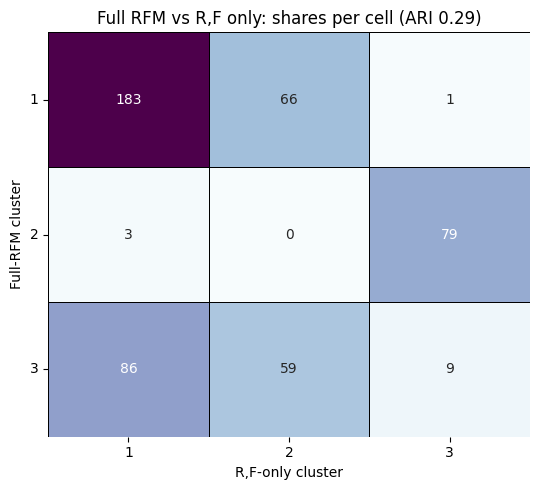

In [68]:
X_rf = StandardScaler().fit_transform(data[['Recency', 'Frequency']])
hier_rf = linkage(X_rf, method='ward')
# Same k as the full Ward RFM solution; clusters ordered by traded value for readability
data['Ward_RF'] = order_clusters(cut_tree(hier_rf, n_clusters=WARD_K_RFM).ravel(), data['Log_Monetary'])

ari_m = adjusted_rand_score(data['Ward_RFM'], data['Ward_RF'])
ct_rf = pd.crosstab(data['Ward_RFM'], data['Ward_RF'], rownames=['Ward RFM'], colnames=['Ward RF (no M)'])
print(f'Shares: {len(data)} | k = {WARD_K_RFM}')
print(f'Adjusted Rand index (Ward RFM vs Ward RF): {ari_m:.3f}')
display(ct_rf)

# Heatmap of shares per cell (same numbers as the table above)
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.heatmap(ct_rf, annot=True, fmt='d', cmap='BuPu', cbar=False, linewidths=0.5, linecolor='black',
            annot_kws={'fontsize': 10}, ax=ax)
ax.set_title(f'Full RFM vs R,F only: shares per cell (ARI {ari_m:.2f})')
ax.set_xlabel('R,F-only cluster')
ax.set_ylabel('Full-RFM cluster')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig('outputs/monetary_removal_crosstab_heatmap.png', dpi=150)
plt.show()

=== With Monetary (Ward RFM) ===


,Count,Recency_median,Frequency_median,Monetary_q25_bn,Monetary_median_bn,Monetary_mean_bn,Monetary_q75_bn
Ward_RFM,,,,,,,
1,250,11.0,3.0,7.902,11.178,11.764,14.917
2,82,54.5,2.0,13.021,17.849,47.159,32.502
3,154,11.0,3.0,28.223,39.695,80.145,68.392


=== Without Monetary (Ward RF) ===


,Count,Recency_median,Frequency_median,Monetary_q25_bn,Monetary_median_bn,Monetary_mean_bn,Monetary_q75_bn
Ward_RF,,,,,,,
1,272,11.0,4.0,9.407,14.855,39.401,30.145
2,125,11.0,2.0,10.516,17.699,34.338,31.804
3,89,54.0,2.0,13.738,20.848,46.530,33.246


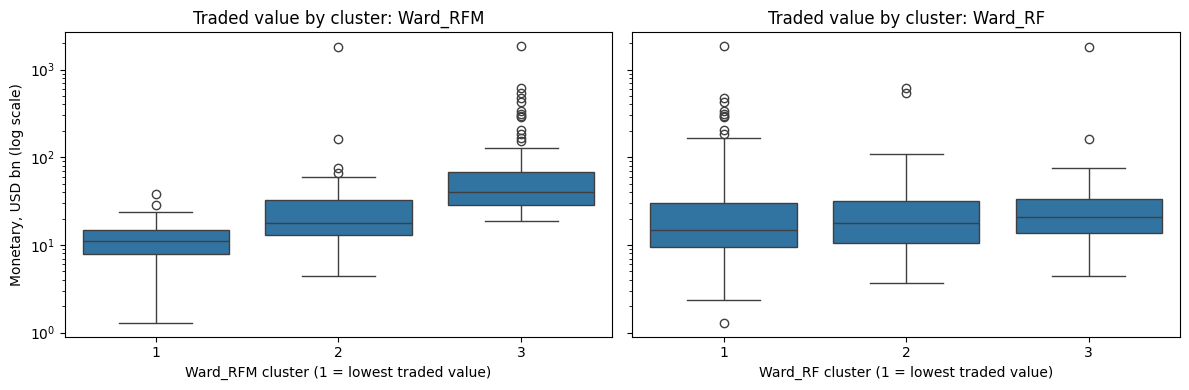

In [69]:
# Traded value profiles: does M mainly separate liquidity levels?
def traded_value_profile(cluster_col):
    return data.groupby(cluster_col).agg(Count=('Monetary', 'size'),
                                         Recency_median=('Recency', 'median'),
                                         Frequency_median=('Frequency', 'median'),
                                         Monetary_q25_bn=('Monetary_USD_bn', lambda s: s.quantile(0.25)),
                                         Monetary_median_bn=('Monetary_USD_bn', 'median'),
                                         Monetary_mean_bn=('Monetary_USD_bn', 'mean'),
                                         Monetary_q75_bn=('Monetary_USD_bn', lambda s: s.quantile(0.75))).round(3)

for label, col in [('With Monetary (Ward RFM)', 'Ward_RFM'), ('Without Monetary (Ward RF)', 'Ward_RF')]:
    print(f'=== {label} ===')
    tv = traded_value_profile(col)
    tv.to_csv(f'outputs/traded_value_profile_{col}.csv')
    display(tv)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ['Ward_RFM', 'Ward_RF']):
    sns.boxplot(x=data[col], y=data['Monetary_USD_bn'], ax=ax)
    ax.set_yscale('log')
    ax.set_xlabel(f'{col} cluster (1 = lowest traded value)')
    ax.set_ylabel('Monetary, USD bn (log scale)')
    ax.set_title(f'Traded value by cluster: {col}')
plt.tight_layout()
plt.savefig('outputs/monetary_removal_traded_value.png', dpi=150)
plt.show()


In [70]:
# How much of the variation in traded value does each solution explain? (eta squared, 0 to 1)
def eta_squared(values, labels):
    v = np.asarray(values, dtype=float)
    lab = np.asarray(labels)
    ss_total = ((v - v.mean()) ** 2).sum()
    ss_between = sum((lab == c).sum() * (v[lab == c].mean() - v.mean()) ** 2 for c in np.unique(lab))
    return float(ss_between / ss_total)


print(f"eta^2 of log1p(M): with M {eta_squared(data['Log_Monetary'], data['Ward_RFM']):.3f}"
      f" | without M {eta_squared(data['Log_Monetary'], data['Ward_RF']):.3f}")
print(f"Silhouette: Ward RFM {silhouette_score(X_rfm, data['Ward_RFM']):.3f}"
      f" | Ward RF (on R, F) {silhouette_score(X_rf, data['Ward_RF']):.3f}")

# Robustness: does log1p(Recency) instead of raw Recency change the Ward RFM solution?
X_logr = StandardScaler().fit_transform(
    np.column_stack([np.log1p(data['Recency']), data['Frequency'], data['Log_Monetary']]))
ward_logr = cut_tree(linkage(X_logr, method='ward'), n_clusters=WARD_K_RFM).ravel()
print(f"ARI (Ward RFM with raw R vs with log1p(R)): {adjusted_rand_score(data['Ward_RFM'], ward_logr):.3f}")


eta^2 of log1p(M): with M 0.516 | without M 0.004
Silhouette: Ward RFM 0.304 | Ward RF (on R, F) 0.488
ARI (Ward RFM with raw R vs with log1p(R)): 0.882


In [71]:
# 2.5.2 Robustness of the Monetary-removal result
from scipy.stats import kruskal

# (a) Is the change specific to one k or one algorithm?
rob_rows = []
for algo, fit in [('Ward', fit_ward), ('K-means', fit_kmeans)]:
    for k in range(2, 6):
        with_m, without_m = fit(X_rfm, k), fit(X_rf, k)
        selected = (algo == 'Ward' and k == WARD_K_RFM) or (algo == 'K-means' and k == KMEANS_K_RFM)
        rob_rows.append({'Algorithm': algo, 'k': k, 'Selected_k': 'yes' if selected else '',
                         'ARI_with_vs_without_M': adjusted_rand_score(with_m, without_m),
                         'eta2_logM_with_M': eta_sq(data['Log_Monetary'], with_m),
                         'eta2_logM_without_M': eta_sq(data['Log_Monetary'], without_m)})
robustness = pd.DataFrame(rob_rows).round(3)
robustness.to_csv('outputs/monetary_removal_robustness.csv', index=False)
print('(a) With vs without Monetary across k and algorithms:')
display(robustness)

# (b) Fair silhouette comparison: score both partitions in the SAME space
fair_sil = pd.DataFrame({
    'In R, F space': [silhouette_score(X_rf, data['Ward_RFM']), silhouette_score(X_rf, data['Ward_RF'])],
    'In R, F, log1p(M) space': [silhouette_score(X_rfm, data['Ward_RFM']), silhouette_score(X_rfm, data['Ward_RF'])],
}, index=['Ward RFM (with M)', 'Ward RF (without M)']).round(3)
print('(b) Silhouettes compared in the same feature space (the earlier 0.488 vs 0.304 mixed two different spaces):')
display(fair_sil)

# (c) What does each solution separate? eta2 for every feature, and Kruskal-Wallis tests across clusters
sep_rows = []
for f in ['Recency', 'Frequency', 'Log_Monetary']:
    row = {'Feature': f}
    for label, col in [('with_M', 'Ward_RFM'), ('without_M', 'Ward_RF')]:
        groups = [g[f].values for _, g in data.groupby(col)]
        row[f'eta2_{label}'] = eta_sq(data[f], data[col])
        row[f'KruskalWallis_p_{label}'] = kruskal(*groups).pvalue
    sep_rows.append(row)
separation = pd.DataFrame(sep_rows).set_index('Feature')
separation.to_csv('outputs/monetary_removal_separation.csv')
print('(c) How strongly each solution separates each feature (eta2: 0-1; p < 0.05 = clusters differ):')
display(separation.round(4))

# (d) Where does the high-traded-value cluster go when M is removed?
top_value = data.groupby('Ward_RFM')['Log_Monetary'].mean().idxmax()
spread = data.loc[data['Ward_RFM'] == top_value, 'Ward_RF'].value_counts(normalize=True).sort_index() * 100
print(f'(d) Ward RFM highest-value cluster ({segment_names["Ward_RFM"][top_value]}, '
      f'{(data["Ward_RFM"] == top_value).sum()} shares) is spread across the R,F-only clusters:')
print((spread.round(1).astype(str) + '%').to_string())


(a) With vs without Monetary across k and algorithms:


,Algorithm,k,Selected_k,ARI_with_vs_without_M,eta2_logM_with_M,eta2_logM_without_M
0,Ward,2,,0.873,0.001,0.004
1,Ward,3,yes,0.291,0.516,0.004
2,Ward,4,,0.203,0.524,0.005
3,Ward,5,,0.335,0.526,0.022
4,K-means,2,,0.933,0.010,0.002
5,K-means,3,,0.195,0.539,0.003
6,K-means,4,yes,0.609,0.517,0.006
7,K-means,5,,0.307,0.512,0.023


(b) Silhouettes compared in the same feature space (the earlier 0.488 vs 0.304 mixed two different spaces):


,"In R, F space","In R, F, log1p(M) space"
Ward RFM (with M),0.068,0.304
Ward RF (without M),0.488,0.258


(c) How strongly each solution separates each feature (eta2: 0-1; p < 0.05 = clusters differ):


,eta2_with_M,KruskalWallis_p_with_M,eta2_without_M,KruskalWallis_p_without_M
Feature,,,,
Recency,0.6423,0.0,0.6460,0.0000
Frequency,0.1187,0.0,0.5432,0.0000
Log_Monetary,0.5162,0.0,0.0041,0.0644


(d) Ward RFM highest-value cluster (C3: Recent, high value, 154 shares) is spread across the R,F-only clusters:
Ward_RF
1    55.8%
2    38.3%
3     5.8%


**Conclusions from removing Monetary, and the limits of traded value as a liquidity proxy**

- **Memberships change substantially:** ARI ≈ 0.29 between the Ward solutions with and without M (same 486 shares, same k = 3, scaler refitted). The robustness table shows the change is large for Ward at k = 3–5 (ARI 0.20–0.34) and for K-means at k = 3 and 5, but smaller for K-means at its selected k = 4 (ARI ≈ 0.61), because that solution is already organised mainly around R and F. At k = 2 both algorithms barely change, since the first split is driven by Recency.
- **M mainly separates liquidity (trading scale), not activity:** with M, clusters explain about half of the variation in log traded value (eta² ≈ 0.52) and median M rises from about $11bn to $40bn across clusters. Without M, eta² falls to about 0.00 and the medians flatten ($15–21bn). The Kruskal–Wallis p-value in table (c) shows whether any difference in M remains, and the eta² for R and F shows how much of the activity separation is kept. The high-value cluster does not survive as a group: its shares scatter across all R,F-only clusters. So **activity (R, F) and trading scale (M) are largely independent dimensions**, and including M re-organises the segments around how much is traded.
- **Recency is the most stable separator:** the "stale" group (median R ≈ 55 days) appears with and without M, so the activity-timing structure is robust.
- **Silhouette:** compared fairly in the same space (table (b)), each partition is expected to score better in the space it was built for, so silhouette cannot by itself say which is "better". The choice depends on whether the segmentation should reflect trading scale.
- **Limits of M as a liquidity proxy:** traded value measures *how much* trades, not *how easily*. It does not measure **bid–ask spreads, order-book depth or price impact** (none of which are in this data). It is dominated by **company size**, is specific to the **Q4 2024 window**, and is **split across dual-class tickers**. A share with high M can still be costly to trade in size, and vice versa, so the "liquidity" interpretation should be read as "trading scale".


# **Task 03 - Evidence for the Business Review**


**3.2.1 Cluster profiles and sector composition**

Evidence for comparing the **risk/return** segments (weekly return, beta) with the **RFM activity** segments: how they overlap, which sectors each over- or under-represents, and how each solution's profile differs across all five features. (The written review in the report is limited to 500 words for 3.2.1–3.2.3, so these cells provide figures and numbers to cite.)


In [72]:
# 3.2.1 Risk/return clusters vs RFM clusters on the same shares (both algorithms)
def cramers_v(table):
    """Association between two categorical variables (0 = none, 1 = perfect)."""
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))


agreement = []
for algo in ['Ward', 'KMeans']:
    rr, rfm = data[f'{algo}_RR'], data[f'{algo}_RFM']
    table = pd.crosstab(rr, rfm, rownames=[f'{algo} risk/return'], colnames=[f'{algo} RFM'])
    agreement.append({'Algorithm': algo, 'ARI_RR_vs_RFM': adjusted_rand_score(rr, rfm), 'Cramers_V': cramers_v(table)})
    print(f'=== {algo}: risk/return vs RFM ===')
    display(table)

agreement = pd.DataFrame(agreement).round(4)
agreement.to_csv('outputs/rr_vs_rfm_agreement.csv', index=False)
agreement


=== Ward: risk/return vs RFM ===


Ward RFM,1,2,3
Ward risk/return,,,
1,27,16,23
2,53,10,35
3,115,28,39
4,36,19,37
5,19,9,20


=== KMeans: risk/return vs RFM ===


KMeans RFM,1,2,3,4
KMeans risk/return,,,,
1,34,52,19,26
2,41,84,14,27
3,30,54,15,13
4,6,8,6,7
5,11,14,7,18


,Algorithm,ARI_RR_vs_RFM,Cramers_V
0,Ward,0.0393,0.1656
1,KMeans,0.0210,0.1296


=== Sector composition of Ward_RR clusters (% of cluster) ===


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RR,,,,,,,,,,,
1,4.5,0.0,33.3,0.0,3.0,28.8,3.0,0.0,1.5,1.5,24.2
2,5.1,9.2,5.1,16.3,28.6,8.2,11.2,2.0,3.1,3.1,8.2
3,3.8,9.3,2.7,0.0,14.3,13.7,22.0,11.0,7.7,12.6,2.7
4,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1
5,0.0,20.8,0.0,0.0,10.4,8.3,8.3,47.9,4.2,0.0,0.0


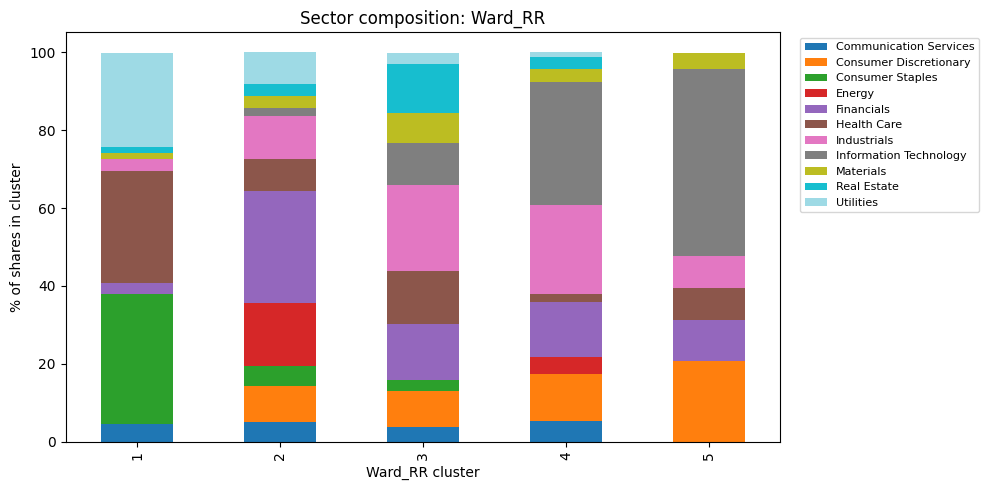

=== Sector composition of KMeans_RR clusters (% of cluster) ===


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RR,,,,,,,,,,,
1,4.6,2.3,19.1,0.8,13.0,18.3,9.2,2.3,5.3,5.3,19.8
2,4.8,12.0,1.2,10.2,22.3,4.8,20.5,13.3,3.0,7.2,0.6
3,4.5,9.8,4.5,0.0,9.8,22.3,19.6,10.7,7.1,9.8,1.8
4,0.0,11.1,0.0,7.4,14.8,0.0,22.2,37.0,3.7,0.0,3.7
5,2.0,20.0,0.0,0.0,10.0,2.0,8.0,54.0,4.0,0.0,0.0


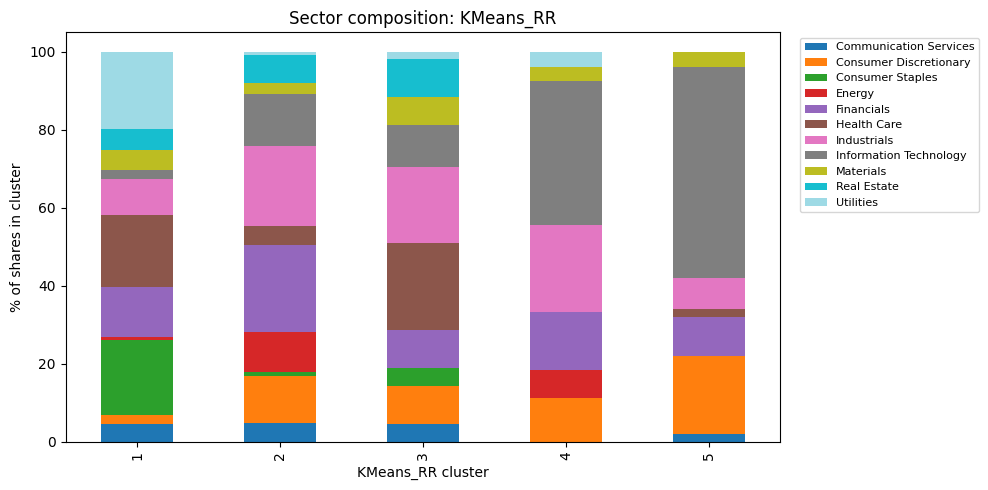

=== Sector composition of Ward_RFM clusters (% of cluster) ===


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
1,2.8,7.2,5.6,3.2,15.6,11.2,20.4,10.0,5.2,10.8,8.0
2,4.9,11.0,8.5,2.4,12.2,11.0,7.3,22.0,9.8,0.0,11.0
3,5.8,13.0,7.1,6.5,16.2,13.6,13.6,20.1,1.3,1.9,0.6


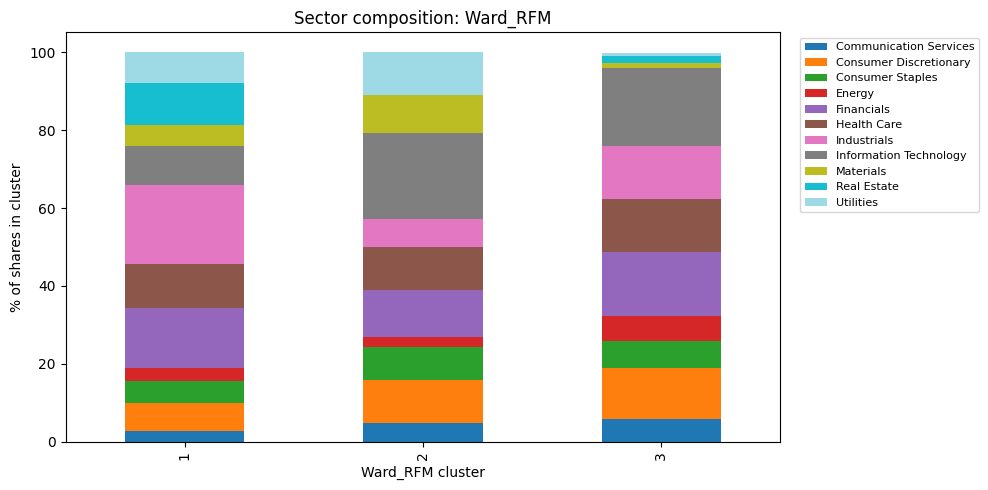

=== Sector composition of KMeans_RFM clusters (% of cluster) ===


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
1,4.9,7.4,5.7,0.8,15.6,15.6,19.7,9.8,4.1,9.8,6.6
2,1.9,9.4,6.1,6.6,16.0,9.0,20.3,11.3,5.2,8.5,5.7
3,3.3,11.5,8.2,1.6,13.1,9.8,6.6,21.3,9.8,0.0,14.8
4,8.8,12.1,7.7,4.4,14.3,15.4,7.7,27.5,1.1,0.0,1.1


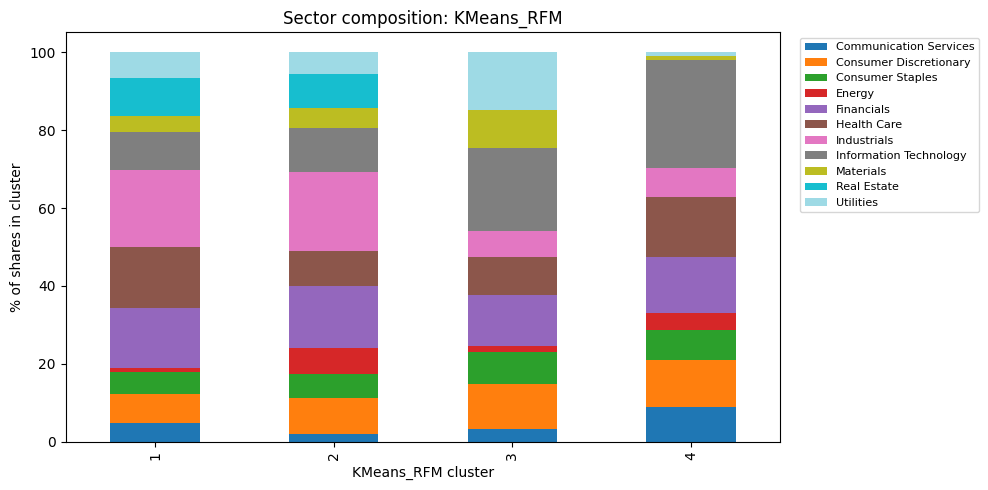

Sector association (chi-square test of independence, Cramer's V):


,Solution,Chi2,dof,p_value,Cramers_V
0,Ward_RR,354.8364,40,0.0,0.4272
1,KMeans_RR,272.8238,40,0.0,0.3746
2,Ward_RFM,66.3242,20,0.0,0.2612
3,KMeans_RFM,78.2654,30,0.0,0.2317


In [73]:
# 3.2.1 Sector composition (% of each cluster) for all four baseline solutions + association tests
sector_tests = []
for col in ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']:
    counts = pd.crosstab(data[col], data['GICS Sector'])
    comp = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
    print(f'=== Sector composition of {col} clusters (% of cluster) ===')
    display(comp)
    comp.to_csv(f'outputs/sector_composition_{col}.csv')

    chi2, p, dof, _ = chi2_contingency(counts, correction=False)
    sector_tests.append({'Solution': col, 'Chi2': chi2, 'dof': dof, 'p_value': p, 'Cramers_V': cramers_v(counts)})

    comp.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20')
    plt.ylabel('% of shares in cluster')
    plt.xlabel(f'{col} cluster')
    plt.title(f'Sector composition: {col}')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.savefig(f'outputs/sector_composition_{col}.png', dpi=150)
    plt.show()

sector_tests = pd.DataFrame(sector_tests).round(4)
sector_tests.to_csv('outputs/sector_association.csv', index=False)
print('Sector association (chi-square test of independence, Cramer\'s V):')
sector_tests


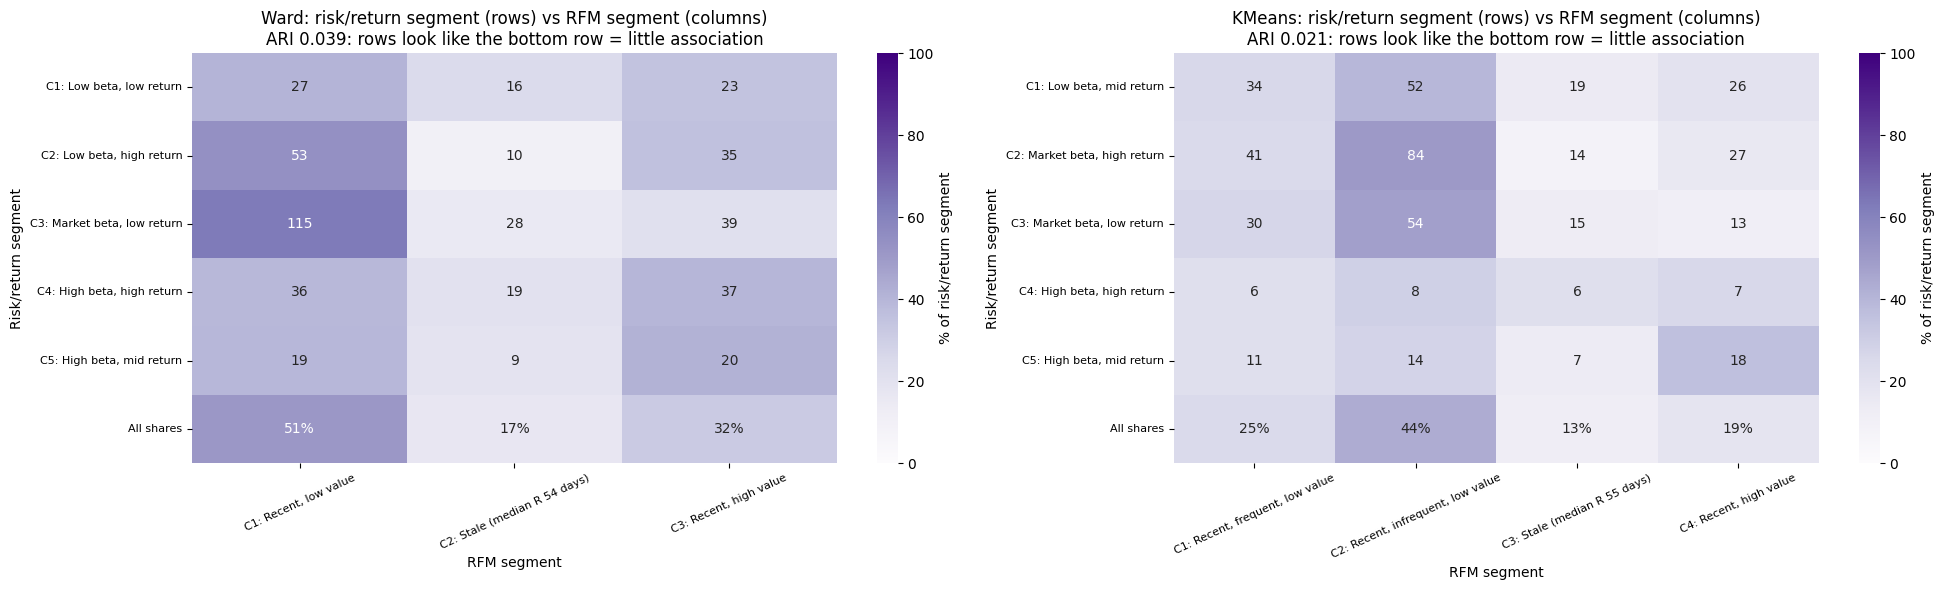

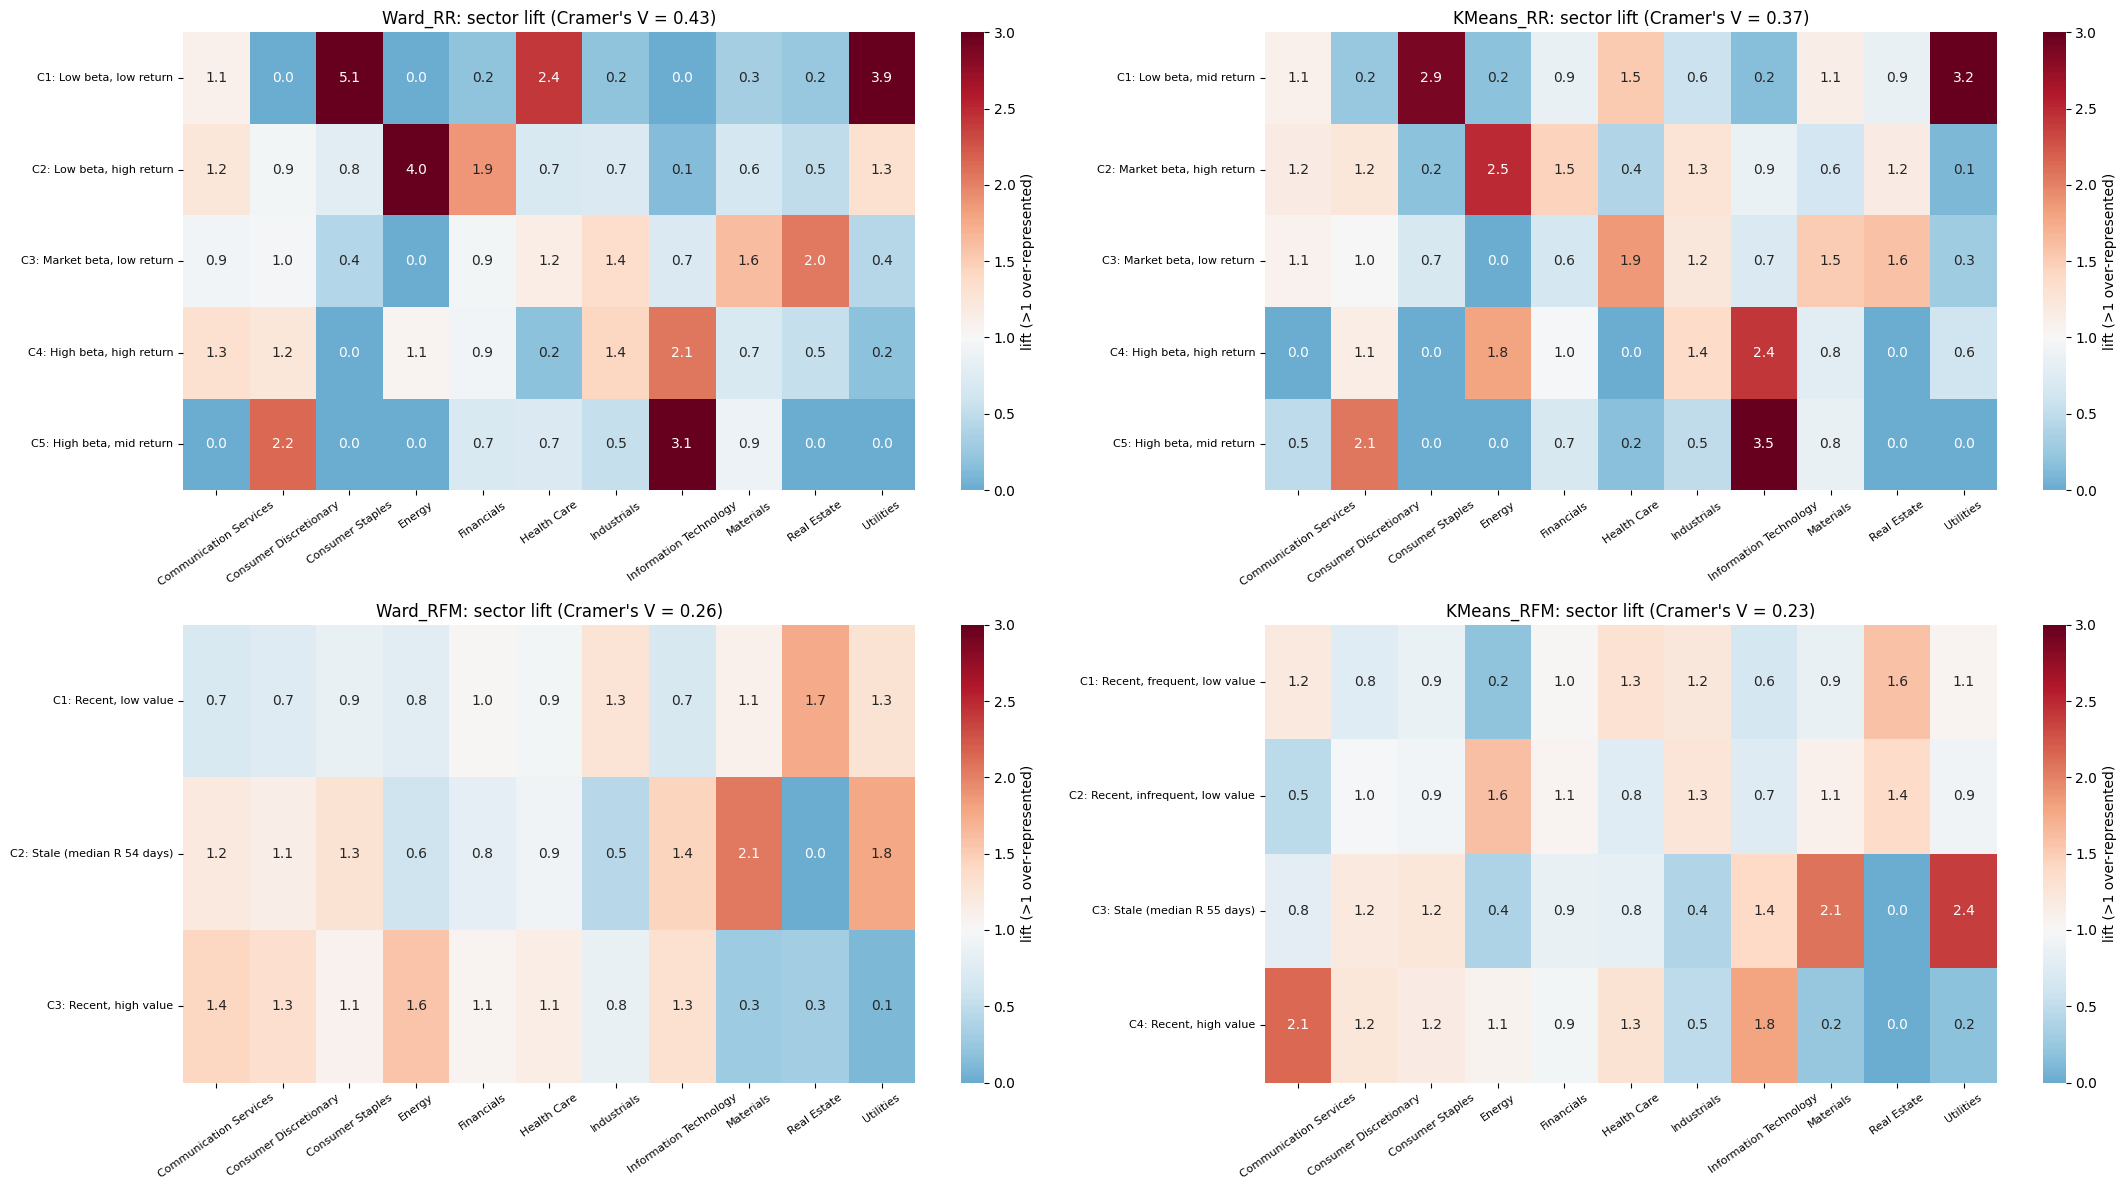

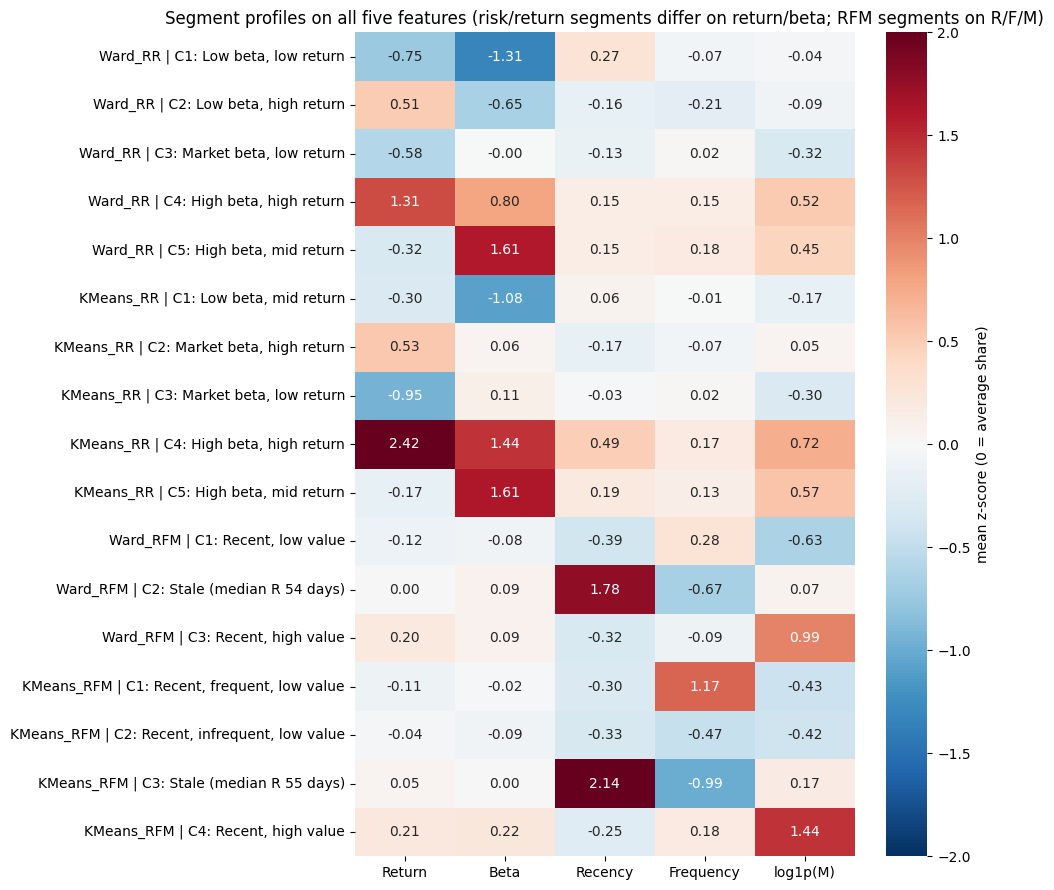

In [74]:
# 3.2.1 Named comparisons: risk/return x RFM segments, sector lift, and one profile heatmap for all four solutions
# (a) Do risk/return segments line up with activity segments? (row % = where each risk/return segment's shares sit)
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, algo in zip(axes, ['Ward', 'KMeans']):
    ct = pd.crosstab(data[f'{algo}_RR_Segment'], data[f'{algo}_RFM_Segment'])
    overall_row = (data[f'{algo}_RFM_Segment'].value_counts(normalize=True) * 100).reindex(ct.columns)
    row_pct = pd.concat([ct.div(ct.sum(axis=1), axis=0) * 100, overall_row.to_frame('All shares').T])
    annot = pd.concat([ct.astype(str), (overall_row.round(0).astype(int).astype(str) + '%').to_frame('All shares').T])
    sns.heatmap(row_pct, annot=annot.values, fmt='', cmap='Purples', vmin=0, vmax=100, ax=ax,
                cbar_kws={'label': '% of risk/return segment'})
    ax.set(title=f'{algo}: risk/return segment (rows) vs RFM segment (columns)\n'
                 f'ARI {adjusted_rand_score(data[f"{algo}_RR"], data[f"{algo}_RFM"]):.3f}: rows look like the bottom row = little association',
           xlabel='RFM segment', ylabel='Risk/return segment')
    ax.tick_params(axis='x', labelrotation=25, labelsize=8); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.savefig('outputs/rr_vs_rfm_named_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# (b) Sector lift: share of a sector inside a segment / share of that sector in all 486 shares (1 = no over-representation)
overall_sector = data['GICS Sector'].value_counts(normalize=True)
fig, axes = plt.subplots(2, 2, figsize=(22, 12))
lift_tables = {}
for ax, col in zip(axes.ravel(), ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']):
    share = pd.crosstab(data[f'{col}_Segment'], data['GICS Sector'], normalize='index')
    lift = share / overall_sector[share.columns]
    lift_tables[col] = lift.round(2)
    lift.round(2).to_csv(f'outputs/sector_lift_{col}.csv')
    sns.heatmap(lift, annot=True, fmt='.1f', cmap='RdBu_r', center=1, vmin=0, vmax=3, ax=ax,
                cbar_kws={'label': 'lift (>1 over-represented)'})
    v = sector_tests.set_index('Solution').loc[col, 'Cramers_V']
    ax.set(title=f"{col}: sector lift (Cramer's V = {v:.2f})", xlabel='', ylabel='')
    ax.tick_params(axis='x', labelrotation=35, labelsize=8); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.savefig('outputs/sector_lift_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

# (c) One standardised profile heatmap: each segment's mean z-score on all five features
z_all = (data[all_features] - data[all_features].mean()) / data[all_features].std()
z_all = z_all.rename(columns={'Mean_Weekly_Return': 'Return', 'Monetary': 'Monetary (raw)'})
z_all['log1p(M)'] = (data['Log_Monetary'] - data['Log_Monetary'].mean()) / data['Log_Monetary'].std()
z_all = z_all.drop(columns='Monetary (raw)')
blocks = []
for col in ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']:
    b = z_all.groupby(data[f'{col}_Segment']).mean()
    b.index = [f'{col} | {s}' for s in b.index]
    blocks.append(b)
profile_z = pd.concat(blocks)
profile_z.round(2).to_csv('outputs/segment_profiles_standardised_all_solutions.csv')
plt.figure(figsize=(10, 9))
sns.heatmap(profile_z, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-2, vmax=2,
            cbar_kws={'label': 'mean z-score (0 = average share)'})
plt.title('Segment profiles on all five features (risk/return segments differ on return/beta; RFM segments on R/F/M)')
plt.tight_layout()
plt.savefig('outputs/segment_profiles_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


**3.2.2 Sensitivity findings and business uses: activity-monitoring demonstration**

The sensitivity evidence is in 2.5 (correlations, feature influence, Monetary removal). The cell below demonstrates the **monitoring use**: RFM is recomputed at the **previous quarter-end** with identical rules (no look-ahead), each share is assigned to the current K-means RFM segments using the same fitted scaler and centroids, and the **segment migration** shows which shares' trading activity changed between quarters. This is how the segments would support an activity watchlist. It describes trading behaviour; it does not predict returns.


Previous observation date: 2024-09-30 | window 2024-07-08 to 2024-09-30
Shares with no event before 2024-09-30 (not assignable): 0


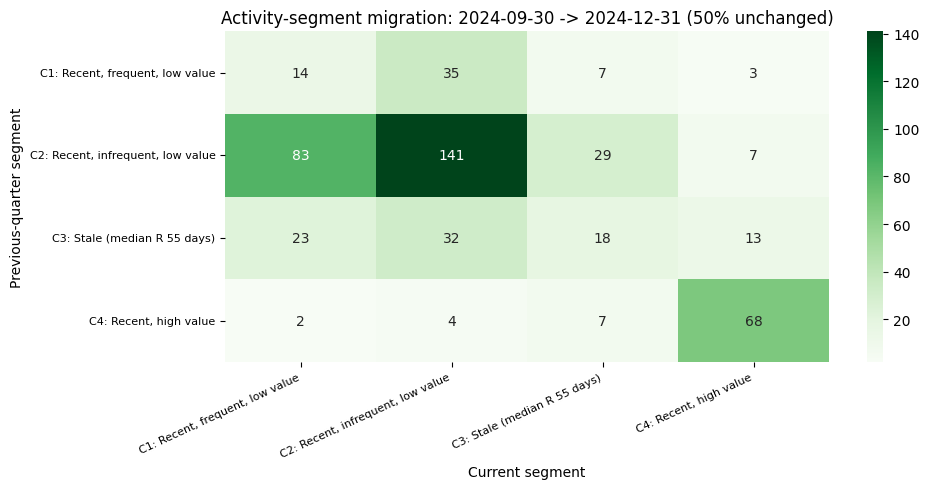

245 shares changed activity segment; examples (watchlist saved to outputs/rfm_activity_watchlist.csv):


,Previous_segment,Current_segment,Prev_Recency,Prev_Frequency,Security,Recency,Frequency,Monetary_USD_bn
Ticker,,,,,,,,
MMM,"C4: Recent, high value","C1: Recent, frequent, low value",10,3,3M,11.0,4,25.991459
AOS,"C1: Recent, frequent, low value","C2: Recent, infrequent, low value",4,5,A. O. Smith,11.0,2,4.748980
ABT,C3: Stale (median R 55 days),"C2: Recent, infrequent, low value",63,3,Abbott Laboratories,11.0,1,35.230273
AMD,C3: Stale (median R 55 days),"C4: Recent, high value",61,1,Advanced Micro Devices,18.0,4,313.165910
AES,"C2: Recent, infrequent, low value",C3: Stale (median R 55 days),10,3,AES Corporation,54.0,3,11.195779
AFL,"C1: Recent, frequent, low value","C2: Recent, infrequent, low value",10,4,Aflac,11.0,2,13.284557
A,C3: Stale (median R 55 days),"C2: Recent, infrequent, low value",94,0,Agilent Technologies,11.0,2,14.001796
APD,"C2: Recent, infrequent, low value",C3: Stale (median R 55 days),10,2,Air Products,85.0,1,26.622609
ALGN,C3: Stale (median R 55 days),"C1: Recent, frequent, low value",67,1,Align Technology,11.0,4,10.676625


In [75]:
# 3.2.2 Monitoring demonstration: RFM at the previous quarter-end -> assign to current segments -> migration
prev_obs = close_v.loc[:'2024-09-30'].index.max()
prev_rows = []
for t in data.index:
    hv = high_volume_flags(t, prev_obs)                       # same rule, data only up to prev_obs
    ev = hv.index[hv['High_Volume']]
    window = hv.tail(60)
    prev_rows.append({'Ticker': t, 'Recency': (prev_obs - ev.max()).days if len(ev) else np.nan,
                      'Frequency': int(window['High_Volume'].sum()), 'Monetary': window['Traded_Value'].sum()})
prev = pd.DataFrame(prev_rows).set_index('Ticker')
prev['Log_Monetary'] = np.log1p(prev['Monetary'])
print(f'Previous observation date: {prev_obs.date()} | window {hv.tail(60).index[0].date()} to {hv.tail(60).index[-1].date()}')

# Current K-means RFM model (same scaler, same centroids) used to assign the previous quarter's values
scaler_rfm = StandardScaler().fit(rfm_matrix_df)
km_rfm = KMeans(n_clusters=KMEANS_K_RFM, n_init=N_INIT, random_state=SEED).fit(X_rfm)
assert adjusted_rand_score(km_rfm.labels_, data['KMeans_RFM']) > 0.999, 'refitted model differs from KMeans_RFM'
to_current = pd.crosstab(km_rfm.labels_, data['KMeans_RFM'].values).idxmax(axis=1)   # raw label -> ordered label

ok = prev['Recency'].notna()
prev_cluster = pd.Series(km_rfm.predict(scaler_rfm.transform(prev.loc[ok, rfm_features])), index=prev.index[ok]).map(to_current)
monitor = pd.DataFrame({'Previous_segment': prev_cluster.map(segment_names['KMeans_RFM']),
                        'Current_segment': data.loc[ok, 'KMeans_RFM_Segment']})
print(f'Shares with no event before {prev_obs.date()} (not assignable): {(~ok).sum()}')

migration = pd.crosstab(monitor['Previous_segment'], monitor['Current_segment'])
stayed_pct = (monitor['Previous_segment'] == monitor['Current_segment']).mean() * 100
migration.to_csv('outputs/rfm_segment_migration.csv')
plt.figure(figsize=(10, 5))
sns.heatmap(migration, annot=True, fmt='d', cmap='Greens')
plt.title(f'Activity-segment migration: {prev_obs.date()} -> {observation_date.date()} ({stayed_pct:.0f}% unchanged)')
plt.xlabel('Current segment'); plt.ylabel('Previous-quarter segment')
plt.xticks(rotation=25, ha='right', fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/rfm_segment_migration.png', dpi=150, bbox_inches='tight')
plt.show()

watch = monitor[monitor['Previous_segment'] != monitor['Current_segment']].join(
    prev[['Recency', 'Frequency']].add_prefix('Prev_')).join(data[['Security', 'Recency', 'Frequency', 'Monetary_USD_bn']])
watch.to_csv('outputs/rfm_activity_watchlist.csv')
print(f'{len(watch)} shares changed activity segment; examples (watchlist saved to outputs/rfm_activity_watchlist.csv):')
display(watch.head(10))


In [76]:
# Final feature table: one row per included share with all cluster assignments
final_cols = ['Security', 'GICS Sector', 'Mean_Weekly_Return', 'Weekly_Obs', 'Beta', 'Paired_weeks',
              'Observation_Date', 'Last_Event_Date', 'Recency', 'Frequency', 'Monetary', 'Log_Monetary',
              'Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM', 'Ward_RF']
data[final_cols].to_csv('outputs/feature_table_with_clusters.csv')
print('Saved outputs/feature_table_with_clusters.csv with', len(data), 'shares')
print('Files in outputs/:', sorted(os.listdir('outputs')))
data[final_cols].head()

Saved outputs/feature_table_with_clusters.csv with 486 shares
Files in outputs/: ['beta_diagnostics.csv', 'clusters_rfm_biplot.png', 'clusters_rfm_original_features.png', 'clusters_rfm_pca.png', 'clusters_risk_return.png', 'clusters_risk_return_named.png', 'corporate_actions_large_moves.csv', 'corporate_actions_ratio_jumps.csv', 'corporate_actions_split_check.csv', 'corporate_actions_unexplained.csv', 'dendrogram_rfm.png', 'dendrogram_rfm_selected_k.png', 'dendrogram_risk_return.png', 'dendrogram_risk_return_selected_k.png', 'distance_sensitivity_transformations.csv', 'exclusion_log.csv', 'feature_boxplots.png', 'feature_persistence.csv', 'feature_preparation_diagnostics.csv', 'feature_raw_vs_used_histograms.png', 'feature_spearman_correlations.csv', 'feature_spearman_heatmap.png', 'feature_summary.csv', 'feature_summary_readable.csv', 'feature_table_all_valid_shares.csv', 'feature_table_with_clusters.csv', 'inclusion_exclusion_log_all_tickers.csv', 'k_diagnostics_rfm.png', 'k_diagnost

,Security,GICS Sector,Mean_Weekly_Return,Weekly_Obs,Beta,Paired_weeks,Observation_Date,Last_Event_Date,Recency,Frequency,Monetary,Log_Monetary,Ward_RR,KMeans_RR,Ward_RFM,KMeans_RFM,Ward_RF
Ticker,,,,,,,,,,,,,,,,,
MMM,3M,Industrials,0.001142,207,0.869079,207,2024-12-31,2024-12-20,11.0,4,2.599146e+10,23.981034,3,3,3,1,1
AOS,A. O. Smith,Industrials,0.001991,207,1.042805,207,2024-12-31,2024-12-20,11.0,2,4.748980e+09,22.281196,3,3,1,2,2
ABT,Abbott Laboratories,Health Care,0.000971,207,0.583543,207,2024-12-31,2024-12-20,11.0,1,3.523027e+10,24.285172,1,1,3,2,2
ABBV,AbbVie,Health Care,0.003749,207,0.425366,207,2024-12-31,2024-12-20,11.0,3,6.837054e+10,24.948208,2,1,3,4,1
ACN,Accenture,Information Technology,0.002376,207,1.143301,207,2024-12-31,2024-12-20,11.0,2,5.199430e+10,24.674400,3,2,3,4,2


**3.2.3 Critical evaluation and limitations**

Evidence on return dependencies, the price-adjustment assumption and survivorship bias follows. Feature overlap is covered in 2.5.1 and liquidity-proxy limits in 1.4.3 and 2.5.2. The final test checks whether the clusters say anything about the **future**.


In [77]:
# 3.2.3 Return dependencies: average pairwise correlation of weekly returns
# within each cluster (diagonal) and between clusters (off-diagonal)
returns_corr = weekly_returns[data.index].corr()

all_pairs = returns_corr.values[np.triu_indices_from(returns_corr.values, k=1)]
print(f'Average pairwise weekly-return correlation, all {len(data)} shares: {all_pairs.mean():.3f}')

Average pairwise weekly-return correlation, all 486 shares: 0.300



=== Ward_RR: average weekly-return correlation (diagonal = within, off-diagonal = between) ===


,1,2,3,4,5
1,0.312,0.238,0.236,0.149,0.125
2,0.238,0.325,0.299,0.275,0.234
3,0.236,0.299,0.367,0.338,0.347
4,0.149,0.275,0.338,0.374,0.385
5,0.125,0.234,0.347,0.385,0.438


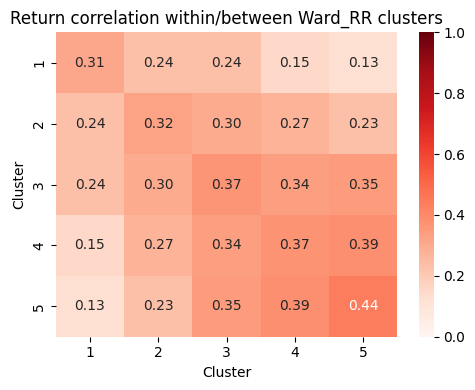


=== Ward_RFM: average weekly-return correlation (diagonal = within, off-diagonal = between) ===


,1,2,3
1,0.328,0.293,0.296
2,0.293,0.266,0.273
3,0.296,0.273,0.284


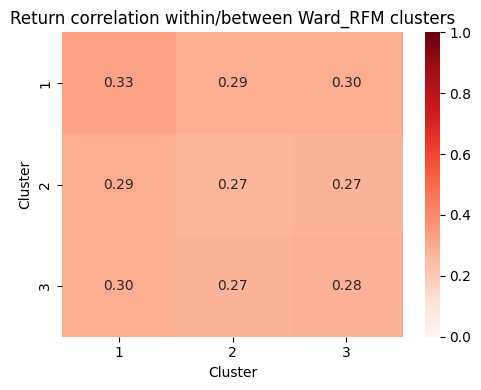

In [78]:
for cluster_col in ['Ward_RR', 'Ward_RFM']:
    clusters = sorted(data[cluster_col].unique())
    dependency = pd.DataFrame(index=clusters, columns=clusters, dtype=float)

    for a in clusters:
        for b in clusters:
            shares_a = data.index[data[cluster_col] == a]
            shares_b = data.index[data[cluster_col] == b]
            block = returns_corr.loc[shares_a, shares_b].values
            if a == b:
                # same cluster: skip self-correlations (1.0) and duplicate pairs
                block = block[np.triu_indices_from(block, k=1)]
            dependency.loc[a, b] = block.mean()

    print(f'\n=== {cluster_col}: average weekly-return correlation (diagonal = within, off-diagonal = between) ===')
    display(dependency.round(3))
    dependency.round(3).to_csv(f'outputs/return_dependency_{cluster_col}.csv')

    plt.figure(figsize=(5, 4))
    sns.heatmap(dependency, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
    plt.title(f'Return correlation within/between {cluster_col} clusters')
    plt.xlabel('Cluster'); plt.ylabel('Cluster')
    plt.tight_layout()
    plt.savefig(f'outputs/return_dependency_{cluster_col}.png', dpi=150)
    plt.show()

**3.2.3 Return Dependencies: Within vs Across Clusters**


In [79]:
# Is the average correlation of pairs INSIDE the same cluster higher than for pairs in DIFFERENT clusters,
# and higher than under random labelling with identical cluster sizes (permutation baseline)?
rng = np.random.default_rng(SEED)
corr_matrix = returns_corr.values
upper = np.triu_indices_from(corr_matrix, k=1)     # each pair counted once
pair_corr = corr_matrix[upper]


def within_across(labels):
    labels = np.asarray(labels)
    same = (labels[:, None] == labels[None, :])[upper]
    return pair_corr[same].mean(), pair_corr[~same].mean()


dependence = []
for col in ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']:
    labels = data[col].values
    within, across = within_across(labels)
    random_within = np.array([within_across(rng.permutation(labels))[0] for _ in range(N_PERMUTATIONS)])
    dependence.append({'Grouping': col, 'Within_mean_corr': within, 'Across_mean_corr': across,
                       'Random_within_mean': random_within.mean(), 'Random_within_sd': random_within.std(),
                       'z_vs_random': (within - random_within.mean()) / random_within.std()})

# Same question for GICS sectors (a "natural" grouping) for comparison
sector_labels = data['GICS Sector'].to_numpy(dtype=object)
within, across = within_across(sector_labels)
dependence.append({'Grouping': 'GICS sector', 'Within_mean_corr': within, 'Across_mean_corr': across})

dependence = pd.DataFrame(dependence).round(4)
dependence.to_csv('outputs/return_dependence_within_across.csv', index=False)
dependence


,Grouping,Within_mean_corr,Across_mean_corr,Random_within_mean,Random_within_sd,z_vs_random
0,Ward_RR,0.3594,0.2802,0.2995,0.0028,21.6729
1,KMeans_RR,0.3499,0.2823,0.2996,0.0020,24.8223
2,Ward_RFM,0.3123,0.2913,0.2995,0.0021,6.1709
3,KMeans_RFM,0.3142,0.2931,0.2997,0.0025,5.7283
4,GICS sector,0.4144,0.2851,NaN,NaN,NaN


Average pairwise correlation, all pairs        : 0.300
Residual correlation, same-sector pairs        : 0.173
Residual correlation, different-sector pairs   : 0.037

Pairs with |beta_i - beta_j| < 0.05: 9008 | their return correlation: min -0.109, median 0.359, max 0.996


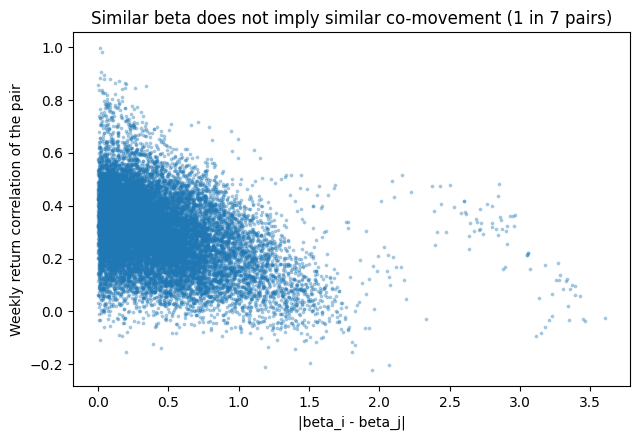

In [80]:
# Market-model residuals: after removing each share's beta exposure, are same-sector shares still correlated?
residuals = weekly_returns[data.index] - np.outer(market_weekly_returns.values, data['Beta'].values)
residuals = residuals - residuals.mean()           # remove intercepts
resid_pairs = residuals.corr().values[upper]
same_sector = (sector_labels[:, None] == sector_labels[None, :])[upper]
print(f'Average pairwise correlation, all pairs        : {pair_corr.mean():.3f}')
print(f'Residual correlation, same-sector pairs        : {resid_pairs[same_sector].mean():.3f}')
print(f'Residual correlation, different-sector pairs   : {resid_pairs[~same_sector].mean():.3f}')

# Similar beta does not mean similar co-movement
beta_values = data['Beta'].values
beta_gap = np.abs(beta_values[:, None] - beta_values[None, :])[upper]
close_beta = beta_gap < 0.05
print(f'\nPairs with |beta_i - beta_j| < 0.05: {close_beta.sum()} | their return correlation: '
      f'min {pair_corr[close_beta].min():.3f}, median {np.median(pair_corr[close_beta]):.3f}, '
      f'max {pair_corr[close_beta].max():.3f}')

plt.figure(figsize=(6.5, 4.5))
plt.scatter(beta_gap[::7], pair_corr[::7], s=3, alpha=0.3)
plt.xlabel('|beta_i - beta_j|')
plt.ylabel('Weekly return correlation of the pair')
plt.title('Similar beta does not imply similar co-movement (1 in 7 pairs)')
plt.tight_layout()
plt.savefig('outputs/beta_gap_vs_correlation.png', dpi=150)
plt.show()


**3.2.3 Price-Adjustment Assumption: Adj Close vs Close**


In [81]:
# Recompute weekly returns and betas from Close (split-adjusted, NOT dividend-adjusted) and compare
close_weekly = calculate_weekly_returns(close_v[data.index].T)
market_close_weekly = calculate_weekly_returns(market_close.to_frame().T)['^GSPC']
print('Week labels identical to the Adj Close version:',
      close_weekly.index.equals(weekly_returns.index) and market_close_weekly.index.equals(market_weekly_returns.index))

beta_close = calculate_weekly_beta(close_weekly, market_close_weekly)['Beta']
adj_vs_close = pd.DataFrame({'Beta_adj': data['Beta'], 'Beta_close': beta_close,
                             'Mean_ret_adj': data['Mean_Weekly_Return'], 'Mean_ret_close': close_weekly.mean()})
adj_vs_close['Beta_diff'] = adj_vs_close['Beta_adj'] - adj_vs_close['Beta_close']
adj_vs_close['Mean_ret_diff_pct_wk'] = (adj_vs_close['Mean_ret_adj'] - adj_vs_close['Mean_ret_close']) * 100
adj_vs_close.round(5).to_csv('outputs/adjusted_vs_close_betas.csv')

print(f"Correlation of betas (Adj Close vs Close): {adj_vs_close['Beta_adj'].corr(adj_vs_close['Beta_close']):.5f}")
print(f"Mean |beta difference|: {adj_vs_close['Beta_diff'].abs().mean():.4f} | max: {adj_vs_close['Beta_diff'].abs().max():.4f}")
print(f"Average return uplift from dividends: {adj_vs_close['Mean_ret_diff_pct_wk'].mean():.4f}% per week"
      f" (about {adj_vs_close['Mean_ret_diff_pct_wk'].mean() * 52:.2f}% per year)")
print('^GSPC Adj Close equals Close (price index):', bool(np.allclose(market_adj, market_close)))


Week labels identical to the Adj Close version: True
Correlation of betas (Adj Close vs Close): 0.99995
Mean |beta difference|: 0.0026 | max: 0.0171
Average return uplift from dividends: 0.0347% per week (about 1.81% per year)
^GSPC Adj Close equals Close (price index): True


**3.2.3 Survivorship Bias**


In [82]:
# Shares that joined the index after the study start are only present because they are constituents TODAY
date_added = pd.to_datetime(sp500_df.set_index('Ticker')['Date added'], errors='coerce')
data['Date_Added'] = date_added.reindex(data.index)
late = data['Date_Added'] > pd.Timestamp(start)

survivorship = pd.DataFrame({
    'Group': [f'Added to index after {start}', f'Already a constituent at {start} (or date unknown)'],
    'Shares': [int(late.sum()), int((~late).sum())],
    'Mean_weekly_return_pct': [data.loc[late, 'Mean_Weekly_Return'].mean() * 100,
                               data.loc[~late, 'Mean_Weekly_Return'].mean() * 100],
    'Median_weekly_return_pct': [data.loc[late, 'Mean_Weekly_Return'].median() * 100,
                                 data.loc[~late, 'Mean_Weekly_Return'].median() * 100],
    'Mean_beta': [data.loc[late, 'Beta'].mean(), data.loc[~late, 'Beta'].mean()]}).round(4)
survivorship.to_csv('outputs/survivorship_evidence.csv', index=False)
display(survivorship)

stat, p = mannwhitneyu(data.loc[late, 'Mean_Weekly_Return'], data.loc[~late, 'Mean_Weekly_Return'])
print(f'Mann-Whitney U test (mean weekly return, late additions vs others): p = {p:.4f}')
print('Note: shares which were removed from the index before the retrieval date are absent from the data entirely.')


,Group,Shares,Mean_weekly_return_pct,Median_weekly_return_pct,Mean_beta
0,Added to index after 2021-01-01,72,0.4669,0.4453,1.3222
1,Already a constituent at 2021-01-01 (or date unknown),414,0.2542,0.2542,0.9131


Mann-Whitney U test (mean weekly return, late additions vs others): p = 0.0000
Note: shares which were removed from the index before the retrieval date are absent from the data entirely.


**3.2.3 Descriptive vs predictive: out-of-sample test**

The risk/return clusters are rebuilt using **only 2021–22 data** (same methods and the **same k-selection rule** as Task 2, so no tiny outlier clusters drive the result), and then checked against **2023–24**:
- **Returns:** how much of the second-half variation in mean weekly return do the first-half clusters explain (eta²), compared with in-sample, and do cluster return rankings persist?
- **Risk:** the same for beta.
- **Co-movement:** do shares in the same first-half cluster still move together in 2023–24, compared with random groupings (permutation z)?

Compare in-sample with out-of-sample: where return differences shrink or reverse while beta and co-movement persist, the clusters are **descriptive summaries of past behaviour**. They can inform risk-aware grouping, but they do not justify claims of future outperformance, and co-movement that weakens out of sample does not guarantee reduced portfolio risk.


In [83]:
# 3.2.3 Out-of-sample test: clusters built on 2021-22, evaluated on 2023-24
r_all = weekly_returns[data.index]
half = len(r_all) // 2
r1, r2 = r_all.iloc[:half], r_all.iloc[half:]
m1, m2 = market_weekly_returns.iloc[:half], market_weekly_returns.iloc[half:]
first = pd.DataFrame({'ret': r1.mean(), 'beta': r1.apply(lambda s: s.cov(m1)) / m1.var()})
second = pd.DataFrame({'ret': r2.mean(), 'beta': r2.apply(lambda s: s.cov(m2)) / m2.var()})
X_first = StandardScaler().fit_transform(first)
print(f'Build period: {r1.index[0].date()} to {r1.index[-1].date()} | test period: {r2.index[0].date()} to {r2.index[-1].date()}')

C2 = r2.corr().values
up2 = np.triu_indices_from(C2, k=1)
pairs2 = C2[up2]
rng_oos = np.random.default_rng(SEED)


def within_across_2(labels):
    labels = np.asarray(labels)
    same = (labels[:, None] == labels[None, :])[up2]
    return pairs2[same].mean(), pairs2[~same].mean()


def select_k_first(fit):
    """Apply the SAME k-selection rule as Task 2 to the 2021-22 features (k >= K_MIN_SELECT, smallest cluster >= 5%)."""
    best, fallback = None, None
    for k in K_RANGE:
        if k < K_MIN_SELECT:
            continue
        lab = fit(k)
        sil = silhouette_score(X_first, lab)
        if fallback is None or sil > fallback[0]:
            fallback = (sil, k, lab)
        if np.bincount(lab).min() / len(lab) >= MIN_CLUSTER_SHARE and (best is None or sil > best[0]):
            best = (sil, k, lab)
    return (best or fallback)[1:]


ward_fit = lambda k: cut_tree(linkage(X_first, method='ward'), n_clusters=k).ravel()
km_fit = lambda k: KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X_first)

oos_rows, cluster_tables = [], {}
for algo, fit in [('Ward', ward_fit), ('K-means', km_fit)]:
    k_first, raw_labels = select_k_first(fit)
    labels = order_clusters(raw_labels, first['beta'].values)      # 1..k, cluster 1 = lowest 2021-22 beta
    print(f'{algo}: k selected on 2021-22 data with the Task 2 rule = {k_first}')
    tbl = pd.DataFrame({'cluster': labels, 'ret_2021_22_pct': first['ret'].values * 100, 'ret_2023_24_pct': second['ret'].values * 100,
                        'beta_2021_22': first['beta'].values, 'beta_2023_24': second['beta'].values}).groupby('cluster').mean()
    tbl.insert(0, 'Shares', pd.Series(labels).value_counts().sort_index().values)
    cluster_tables[algo] = tbl.round(3)
    within, across = within_across_2(labels)
    perm = np.array([within_across_2(rng_oos.permutation(labels))[0] for _ in range(N_PERMUTATIONS)])
    oos_rows.append({
        'Algorithm': algo, 'k': k_first,
        'eta2_return_in_sample': eta_sq(first['ret'], labels), 'eta2_return_out_of_sample': eta_sq(second['ret'], labels),
        'eta2_beta_in_sample': eta_sq(first['beta'], labels), 'eta2_beta_out_of_sample': eta_sq(second['beta'], labels),
        'Cluster_return_rank_corr': tbl['ret_2021_22_pct'].corr(tbl['ret_2023_24_pct'], method='spearman'),
        'Cluster_beta_rank_corr': tbl['beta_2021_22'].corr(tbl['beta_2023_24'], method='spearman'),
        'Within_corr_2023_24': within, 'Across_corr_2023_24': across,
        'z_within_vs_random_2023_24': (within - perm.mean()) / perm.std()})

oos_summary = pd.DataFrame(oos_rows).round(3)
oos_summary.to_csv('outputs/out_of_sample_test.csv', index=False)
print('Out-of-sample summary (eta2: share of cross-sectional variation explained by the 2021-22 clusters):')
display(oos_summary)
for algo, tbl in cluster_tables.items():
    print(f'{algo}: cluster means, build period vs test period')
    display(tbl)


Build period: 2021-01-15 to 2022-12-30 | test period: 2023-01-06 to 2024-12-27
Ward: k selected on 2021-22 data with the Task 2 rule = 3
K-means: k selected on 2021-22 data with the Task 2 rule = 4
Out-of-sample summary (eta2: share of cross-sectional variation explained by the 2021-22 clusters):


,Algorithm,k,eta2_return_in_sample,eta2_return_out_of_sample,eta2_beta_in_sample,eta2_beta_out_of_sample,Cluster_return_rank_corr,Cluster_beta_rank_corr,Within_corr_2023_24,Across_corr_2023_24,z_within_vs_random_2023_24
0,Ward,3,0.256,0.120,0.661,0.445,-0.5,1.0,0.273,0.227,17.384
1,K-means,4,0.574,0.163,0.666,0.457,-0.8,1.0,0.299,0.217,20.165


Ward: cluster means, build period vs test period


,Shares,ret_2021_22_pct,ret_2023_24_pct,beta_2021_22,beta_2023_24
cluster,,,,,
1,212,0.170,0.242,0.696,0.620
2,188,0.357,0.410,1.061,1.059
3,86,-0.197,0.729,1.510,1.632


K-means: cluster means, build period vs test period


,Shares,ret_2021_22_pct,ret_2023_24_pct,beta_2021_22,beta_2023_24
cluster,,,,,
1,163,0.204,0.209,0.632,0.539
2,60,0.781,0.331,0.943,0.868
3,217,0.123,0.433,1.119,1.152
4,46,-0.450,0.938,1.620,1.763


In [84]:
# Run metadata: provenance and calculation version (supports 1.1 and 3.1.2)
run_metadata = pd.DataFrame([{
    'Calc_Version': 'v3.0',
    'Run_Timestamp': datetime.datetime.now().isoformat(timespec='seconds'),
    'Ticker_Source': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies',
    'Ticker_Retrieval_Date': retrieval_date,
    'Price_Source': f'yfinance {yf.__version__} (auto_adjust=False)',
    'Benchmark': '^GSPC (price index, Adj Close)',
    'Study_Start': start,
    'Study_End_Exclusive': end,
    'Observation_Date': observation_date.date(),
    'Weekly_Rule': 'W-FRI last price, complete weeks only',
    'Weeks_Used': len(weekly_returns),
    'Event_Rule': 'Volume > 2 x mean of preceding 20 sessions (current day excluded)',
    'RFM_Window': f"{rfm_df['Window_Start'].iloc[0]} to {rfm_df['Window_End'].iloc[0]} (60 sessions)",
    'Shares_Retrieved': len(tickers),
    'Shares_Clustered': len(data),
    'K_Selection_Rule': f'max silhouette, k >= {K_MIN_SELECT}, smallest cluster >= {MIN_CLUSTER_SHARE:.0%} of shares',
    'K_Ward_RR': WARD_K_RR, 'K_Ward_RFM': WARD_K_RFM,
    'K_KMeans_RR': KMEANS_K_RR, 'K_KMeans_RFM': KMEANS_K_RFM,
    'KMeans_Seed': SEED, 'KMeans_n_init': N_INIT,
    'Permutations': N_PERMUTATIONS,
    'pandas': pd.__version__, 'numpy': np.__version__,
    'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__,
}]).T.rename(columns={0: 'Value'})

run_metadata.to_csv('outputs/run_metadata.csv')
run_metadata


,Value
Calc_Version,v3.0
Run_Timestamp,2026-11-24T10:36:04
Ticker_Source,https://en.wikipedia.org/wiki/List_of_S%26P_500_companies
Ticker_Retrieval_Date,2026-11-24
Price_Source,yfinance 0.2.66 (auto_adjust=False)
Benchmark,"^GSPC (price index, Adj Close)"
Study_Start,2021-01-01
Study_End_Exclusive,2025-01-01
Observation_Date,2024-12-31
Weekly_Rule,"W-FRI last price, complete weeks only"


**3.1 Data mart design: implemented star schema**

The proposed data mart is built here as a SQLite database (`outputs/crm_datamart.sqlite`) so the design in the report is demonstrably implementable and reproducible.

| Table | Type | Grain (one row per…) |
|---|---|---|
| `dim_date` | Dimension (time) | trading day, with week label (W-FRI), month, quarter and RFM-window flag |
| `dim_share` | Dimension (share) | Wikipedia ticker (all 503, with inclusion status and reason) |
| `dim_sector` | Dimension (sector) | GICS sector |
| `dim_benchmark` | Dimension (benchmark) | benchmark index (^GSPC, price index) |
| `dim_calc_run` | Dimension (provenance) | calculation run: version, run time, sources, retrieval date, parameters, snapshot hashes, package versions |
| `fact_daily_market` | Fact | share × trading day: Close, Adj Close, Volume, traded value, dividend, split, 20-session baseline, event flag |
| `fact_benchmark_daily` | Fact | benchmark × trading day |
| `fact_weekly_return` | Fact | share × week: weekly return and the benchmark's return for the same week |
| `fact_share_features` | Fact (derived) | share × calculation run: return, beta (with SE), R, F, M, last event, window start/end, observation date |
| `fact_cluster_assignment` | Fact (derived) | share × calculation run × solution: cluster, k, segment name |

Every derived row carries a `run_id`, so features and cluster assignments from different runs, windows or versions can coexist and be traced back to their sources.


In [85]:
# 3.1 Build the data mart (SQLite star schema) from the validated data and outputs
import sqlite3
import json

db_path = 'outputs/crm_datamart.sqlite'
if os.path.exists(db_path):
    os.remove(db_path)
con = sqlite3.connect(db_path)
RUN_ID = f'v3.0_{observation_date:%Y%m%d}'
window_start, window_end = window_idx[0], window_idx[-1]

# --- Dimensions
dim_calc_run = pd.DataFrame([{
    'run_id': RUN_ID, 'calc_version': 'v3.0',
    'run_timestamp_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    'ticker_source': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies',
    'ticker_retrieval_date': str(retrieval_date), 'price_source': f'yfinance {yf.__version__}', 'auto_adjust': 0,
    'study_start': start, 'study_end_exclusive': end, 'observation_date': str(observation_date.date()),
    'rfm_window_start': str(window_start.date()), 'rfm_window_end': str(window_end.date()),
    'weekly_rule': 'W-FRI last available Adj Close; complete calendar weeks only',
    'event_rule': 'Volume > 2 x mean of preceding 20 sessions (current day excluded)',
    'k_selection_rule': f'max silhouette, k >= {K_MIN_SELECT}, smallest cluster >= {MIN_CLUSTER_SHARE:.0%}',
    'kmeans_seed': SEED, 'kmeans_n_init': N_INIT,
    'snapshot_sha256_json': json.dumps(retrieval_metadata['snapshot_sha256']),
    'package_versions_json': json.dumps({'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
                                         'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__, 'yfinance': yf.__version__}),
}])

sectors = sorted(sp500_df['GICS Sector'].dropna().unique())
dim_sector = pd.DataFrame({'sector_id': range(1, len(sectors) + 1), 'sector_name': sectors})
sector_id = dict(zip(dim_sector['sector_name'], dim_sector['sector_id']))

dim_share = status_log.rename(columns={'Symbol': 'wiki_symbol', 'Ticker': 'ticker', 'Security': 'security',
                                       'Status': 'status', 'Stage': 'stage', 'Reason': 'reason'})
dim_share['sector_id'] = dim_share['GICS Sector'].map(sector_id)
dim_share['date_added'] = pd.to_datetime(sp500_df.set_index('Ticker')['Date added'], errors='coerce') \
    .reindex(dim_share['ticker']).dt.strftime('%Y-%m-%d').values
dim_share = dim_share.drop(columns='GICS Sector')

dates = close_v.index
dim_date = pd.DataFrame({'date': dates.strftime('%Y-%m-%d'), 'year': dates.year, 'quarter': dates.quarter,
                         'month': dates.month, 'weekday': dates.day_name(),
                         'week_label_fri': (dates + pd.to_timedelta(4 - dates.dayofweek, unit='D')).strftime('%Y-%m-%d'),
                         'in_rfm_window': dates.isin(window_idx).astype(int),
                         'is_observation_date': (dates == observation_date).astype(int)})

dim_benchmark = pd.DataFrame([{'benchmark_id': '^GSPC', 'name': 'S&P 500 index',
                               'type': 'price index (no dividends)', 'price_basis': 'Adj Close (verified equal to Close)'}])

# --- Facts
tick = list(data.index)
frames = {'close': close_v, 'adj_close': adj_v, 'volume': volume_v, 'dividend': div_v, 'split_ratio': split_v,
          'baseline_20': baseline_all, 'high_volume_event': events_all}
frames = {k: v.reindex(index=dates, columns=tick) for k, v in frames.items()}
fact_daily_market = pd.DataFrame({'date': np.repeat(dates.strftime('%Y-%m-%d'), len(tick)),
                                  'ticker': np.tile(tick, len(dates)),
                                  **{k: v.values.ravel() for k, v in frames.items()}})
fact_daily_market['traded_value'] = fact_daily_market['close'] * fact_daily_market['volume']
fact_daily_market['high_volume_event'] = fact_daily_market['high_volume_event'].fillna(False).astype(int)

fact_benchmark_daily = pd.DataFrame({'date': dates.strftime('%Y-%m-%d'), 'benchmark_id': '^GSPC',
                                     'adj_close': market_adj.reindex(dates).values, 'close': market_close.reindex(dates).values})

wr = weekly_returns[tick]
fact_weekly_return = pd.DataFrame({'week_label_fri': np.repeat(wr.index.strftime('%Y-%m-%d'), len(tick)),
                                   'ticker': np.tile(tick, len(wr)), 'weekly_return': wr.values.ravel(),
                                   'benchmark_id': '^GSPC',
                                   'benchmark_return': np.repeat(market_weekly_returns.reindex(wr.index).values, len(tick))})

fact_share_features = pd.DataFrame({
    'run_id': RUN_ID, 'ticker': tick,
    'mean_weekly_return': data['Mean_Weekly_Return'].values, 'weekly_obs': data['Weekly_Obs'].values,
    'beta': data['Beta'].values, 'beta_se': beta_diag['SE'].reindex(tick).values, 'paired_weeks': data['Paired_weeks'].values,
    'recency_days': data['Recency'].values, 'frequency_days': data['Frequency'].values,
    'monetary_usd': data['Monetary'].values, 'log1p_monetary': data['Log_Monetary'].values,
    'last_event_date': pd.to_datetime(data['Last_Event_Date']).dt.strftime('%Y-%m-%d').values,
    'observation_date': str(observation_date.date()),
    'window_start': str(window_start.date()), 'window_end': str(window_end.date())})

solutions = {'Ward_RR': ('Ward', 'risk/return'), 'KMeans_RR': ('K-means', 'risk/return'),
             'Ward_RFM': ('Ward', 'RFM'), 'KMeans_RFM': ('K-means', 'RFM'), 'Ward_RF': ('Ward', 'R,F only (sensitivity)')}
fact_cluster_assignment = pd.concat([
    pd.DataFrame({'run_id': RUN_ID, 'ticker': tick, 'solution': sol, 'algorithm': algo, 'feature_matrix': matrix,
                  'k': data[sol].nunique(), 'cluster': data[sol].values,
                  'segment_name': data[f'{sol}_Segment'].values if f'{sol}_Segment' in data else None})
    for sol, (algo, matrix) in solutions.items()], ignore_index=True)

tables = {'dim_calc_run': dim_calc_run, 'dim_date': dim_date, 'dim_share': dim_share, 'dim_sector': dim_sector,
          'dim_benchmark': dim_benchmark, 'fact_daily_market': fact_daily_market, 'fact_benchmark_daily': fact_benchmark_daily,
          'fact_weekly_return': fact_weekly_return, 'fact_share_features': fact_share_features,
          'fact_cluster_assignment': fact_cluster_assignment}
for name, df in tables.items():
    df.to_sql(name, con, index=False)
for stmt in ['CREATE INDEX ix_daily ON fact_daily_market(ticker, date)',
             'CREATE INDEX ix_weekly ON fact_weekly_return(ticker, week_label_fri)',
             'CREATE INDEX ix_feat ON fact_share_features(run_id, ticker)',
             'CREATE INDEX ix_assign ON fact_cluster_assignment(run_id, solution, ticker)']:
    con.execute(stmt)
con.commit()

grain = {'dim_calc_run': 'run', 'dim_date': 'trading day', 'dim_share': 'ticker (all 503)', 'dim_sector': 'GICS sector',
         'dim_benchmark': 'benchmark', 'fact_daily_market': 'share x trading day', 'fact_benchmark_daily': 'benchmark x trading day',
         'fact_weekly_return': 'share x week', 'fact_share_features': 'share x run', 'fact_cluster_assignment': 'share x run x solution'}
keys = {'dim_calc_run': 'run_id', 'dim_date': 'date', 'dim_share': 'ticker', 'dim_sector': 'sector_id', 'dim_benchmark': 'benchmark_id',
        'fact_daily_market': 'ticker, date', 'fact_benchmark_daily': 'benchmark_id, date', 'fact_weekly_return': 'ticker, week_label_fri',
        'fact_share_features': 'run_id, ticker', 'fact_cluster_assignment': 'run_id, solution, ticker'}
schema = pd.DataFrame([{'Table': n, 'Grain': grain[n], 'Key': keys[n],
                        'Rows': pd.read_sql(f'SELECT COUNT(*) AS n FROM {n}', con)['n'][0],
                        'Columns': ', '.join(df.columns)} for n, df in tables.items()])
schema.to_csv('outputs/datamart_schema.csv', index=False)
print(f'Data mart written to {db_path} ({os.path.getsize(db_path) / 1e6:.1f} MB), run_id = {RUN_ID}')
display(schema)


Data mart written to outputs/crm_datamart.sqlite (48.8 MB), run_id = v3.0_20241231


,Table,Grain,Key,Rows,Columns
0,dim_calc_run,run,run_id,1,"run_id, calc_version, run_timestamp_utc, ticker_source, ticker_retrieval_date, price_source, auto_adjust, study_start, study_end_exclusive, observation_date, rfm_window_start, rfm_window_end, weekly_rule, event_rule, k_selection_rule, kmeans_seed, kmeans_n_init, snapshot_sha256_json, package_versions_json"
1,dim_date,trading day,date,1005,"date, year, quarter, month, weekday, week_label_fri, in_rfm_window, is_observation_date"
2,dim_share,ticker (all 503),ticker,503,"wiki_symbol, ticker, security, status, stage, reason, sector_id, date_added"
3,dim_sector,GICS sector,sector_id,11,"sector_id, sector_name"
4,dim_benchmark,benchmark,benchmark_id,1,"benchmark_id, name, type, price_basis"
5,fact_daily_market,share x trading day,"ticker, date",488430,"date, ticker, close, adj_close, volume, dividend, split_ratio, baseline_20, high_volume_event, traded_value"
6,fact_benchmark_daily,benchmark x trading day,"benchmark_id, date",1005,"date, benchmark_id, adj_close, close"
7,fact_weekly_return,share x week,"ticker, week_label_fri",100602,"week_label_fri, ticker, weekly_return, benchmark_id, benchmark_return"
8,fact_share_features,share x run,"run_id, ticker",486,"run_id, ticker, mean_weekly_return, weekly_obs, beta, beta_se, paired_weeks, recency_days, frequency_days, monetary_usd, log1p_monetary, last_event_date, observation_date, window_start, window_end"
9,fact_cluster_assignment,share x run x solution,"run_id, solution, ticker",2430,"run_id, ticker, solution, algorithm, feature_matrix, k, cluster, segment_name"


In [86]:
# 3.1.3 Example stakeholder queries against the data mart
q_segments = """
SELECT a.solution, a.segment_name, s.sector_name, COUNT(*) AS shares,
       ROUND(AVG(f.beta), 2) AS avg_beta, ROUND(AVG(f.mean_weekly_return) * 100, 3) AS avg_weekly_return_pct,
       ROUND(AVG(f.monetary_usd) / 1e9, 1) AS avg_traded_value_bn
FROM fact_cluster_assignment a
JOIN fact_share_features f ON f.run_id = a.run_id AND f.ticker = a.ticker
JOIN dim_share d ON d.ticker = a.ticker
JOIN dim_sector s ON s.sector_id = d.sector_id
WHERE a.solution = 'Ward_RR'
GROUP BY a.solution, a.segment_name, s.sector_name
HAVING COUNT(*) >= 8
ORDER BY a.segment_name, shares DESC
"""
print('Portfolio analyst: which sectors dominate each risk/return segment?')
display(pd.read_sql(q_segments, con))

q_watch = """
SELECT m.date, m.ticker, d.security, m.volume, ROUND(m.baseline_20) AS baseline_20,
       ROUND(m.volume / m.baseline_20, 2) AS volume_ratio, a.segment_name AS activity_segment
FROM fact_daily_market m
JOIN dim_share d ON d.ticker = m.ticker
JOIN fact_cluster_assignment a ON a.ticker = m.ticker AND a.solution = 'KMeans_RFM'
WHERE m.high_volume_event = 1
  AND m.date >= (SELECT MIN(date) FROM (SELECT date FROM dim_date ORDER BY date DESC LIMIT 10))
ORDER BY volume_ratio DESC
LIMIT 10
"""
print('Activity monitor: strongest high-volume events in the last 10 sessions, with each share\'s activity segment')
display(pd.read_sql(q_watch, con))

q_trace = """
SELECT f.ticker, f.recency_days, f.frequency_days, ROUND(f.monetary_usd / 1e9, 1) AS monetary_bn,
       f.window_start, f.window_end, f.observation_date, r.calc_version, r.ticker_retrieval_date, r.price_source, r.event_rule
FROM fact_share_features f JOIN dim_calc_run r ON r.run_id = f.run_id
WHERE f.ticker IN ('AAPL', 'MMM')
"""
print('Reproducibility: every feature value is traceable to its window, observation date, version and source')
display(pd.read_sql(q_trace, con))
con.close()


Portfolio analyst: which sectors dominate each risk/return segment?


,solution,segment_name,sector_name,shares,avg_beta,avg_weekly_return_pct,avg_traded_value_bn
0,Ward_RR,"C1: Low beta, low return",Consumer Staples,22,0.41,0.070,21.7
1,Ward_RR,"C1: Low beta, low return",Health Care,19,0.45,0.035,40.8
2,Ward_RR,"C1: Low beta, low return",Utilities,16,0.44,0.159,11.4
3,Ward_RR,"C2: Low beta, high return",Financials,28,0.68,0.388,22.4
4,Ward_RR,"C2: Low beta, high return",Energy,16,0.72,0.524,30.2
5,Ward_RR,"C2: Low beta, high return",Industrials,11,0.80,0.438,24.2
6,Ward_RR,"C2: Low beta, high return",Consumer Discretionary,9,0.87,0.423,19.7
7,Ward_RR,"C2: Low beta, high return",Health Care,8,0.63,0.427,33.1
8,Ward_RR,"C2: Low beta, high return",Utilities,8,0.63,0.350,12.5
9,Ward_RR,"C3: Market beta, low return",Industrials,40,0.93,0.168,17.4


Activity monitor: strongest high-volume events in the last 10 sessions, with each share's activity segment


,date,ticker,security,volume,baseline_20,volume_ratio,activity_segment
0,2024-12-20,LII,Lennox International,7306000,308365.0,23.69,"C1: Recent, frequent, low value"
1,2024-12-20,APO,Apollo Global Management,91314300,5502195.0,16.60,"C4: Recent, high value"
2,2024-12-20,WDAY,"Workday, Inc.",46874100,4316125.0,10.86,"C4: Recent, high value"
3,2024-12-20,ILMN,"Illumina, Inc.",14354000,1749385.0,8.21,"C1: Recent, frequent, low value"
4,2024-12-20,VTRS,Viatris,56546300,7297810.0,7.75,"C2: Recent, infrequent, low value"
5,2024-12-20,AXON,Axon Enterprise,7032800,979570.0,7.18,"C1: Recent, frequent, low value"
6,2024-12-20,KR,Kroger,38443000,5494110.0,7.00,"C1: Recent, frequent, low value"
7,2024-12-19,VRTX,Vertex Pharmaceuticals,8207400,1258295.0,6.52,"C4: Recent, high value"
8,2024-12-20,WST,West Pharmaceutical Services,2444400,429335.0,5.69,"C1: Recent, frequent, low value"
9,2024-12-20,JBL,Jabil,6861200,1312195.0,5.23,"C2: Recent, infrequent, low value"


Reproducibility: every feature value is traceable to its window, observation date, version and source


,ticker,recency_days,frequency_days,monetary_bn,window_start,window_end,observation_date,calc_version,ticker_retrieval_date,price_source,event_rule
0,AAPL,11.0,2,623.3,2024-10-07,2024-12-31,2024-12-31,v3.0,2026-11-24,yfinance 0.2.66,Volume > 2 x mean of preceding 20 sessions (current day excluded)
1,MMM,11.0,4,26.0,2024-10-07,2024-12-31,2024-12-31,v3.0,2026-11-24,yfinance 0.2.66,Volume > 2 x mean of preceding 20 sessions (current day excluded)


**Key numbers for the report**

All figures quoted in the written report, collected in one place (also saved to `outputs/report_key_numbers.csv`).


In [87]:
# Key numbers for the report (each wrapped so one missing value does not stop the cell)
key_numbers = []


def add(section, label, fn):
    try:
        value = fn()
    except Exception as exc:                     # noqa: BLE001 - report rather than fail
        value = f'n/a ({type(exc).__name__})'
    key_numbers.append({'Section': section, 'Item': label, 'Value': value})


add('1.1', 'Tickers listed / included / excluded', lambda: f'{len(tickers)} / {len(common)} / {len(tickers) - len(common)}')
add('1.1', 'Index removals since study start (missing from data)',
    lambda: int(survivorship_counts.iloc[-1]['Removed_from_index']) if survivorship_counts is not None
    else 'not available: Wikipedia changes table absent at retrieval date')
add('1.3', 'Weekly returns per share', lambda: len(weekly_returns))
add('1.3', 'Median beta / median R2', lambda: f"{beta_diag['Beta'].median():.3f} / {beta_diag['R2'].median():.2f}")
add('1.3', 'Shares with mean return significantly != 0', lambda: f"{int((return_stats['t_stat'].abs() > 1.96).sum())} of {len(return_stats)}")
add('1.4', 'Most common Recency (share of stocks)', lambda: f"R = {int(common['Recency'].mode()[0])} ({(common['Recency'] == common['Recency'].mode()[0]).mean():.0%})")
add('1.5', 'Persistence 2021-22 -> 2023-24 (Spearman): return / beta',
    lambda: f"{persist.iloc[0]['Spearman_first_vs_second']:.2f} / {persist.iloc[1]['Spearman_first_vs_second']:.2f}")
add('2.2/2.3', 'Selected k (Ward RR, K-means RR, Ward RFM, K-means RFM)', lambda: f'{WARD_K_RR}, {KMEANS_K_RR}, {WARD_K_RFM}, {KMEANS_K_RFM}')
add('2.3', 'K-means RR seed stability at selected k (mean ARI)',
    lambda: tradeoffs.query("Matrix == 'Risk/return' and Selected == 'yes'")['ARI_across_seeds_mean'].iloc[0])
add('2.4', 'Ward vs K-means ARI (RR / RFM)', lambda: ' / '.join(f'{v:.3f}' for v in agreement_summary['ARI']))
add('2.4', 'Matched agreement % (RR / RFM)', lambda: ' / '.join(f'{v:.0f}%' for v in agreement_summary['Matched_agreement_pct']))
add('2.5.1', 'Pearson R-F / R-logM / F-logM', lambda: f"{rfm_corr.loc['Recency', 'Frequency']:.2f} / {rfm_corr.loc['Recency', 'Log_Monetary']:.2f} / {rfm_corr.loc['Frequency', 'Log_Monetary']:.2f}")
add('2.5.1', 'Ward RFM: ARI without each feature (R / F / M)',
    lambda: ' / '.join(f'{v:.2f}' for v in influence[influence['Solution'].str.startswith('Ward')]['ARI_full_vs_without_this_feature']))
add('2.5.2', 'Ward RFM vs R,F-only ARI', lambda: round(ari_m, 3))
add('2.5.2', 'eta2 of log1p(M): with M / without M',
    lambda: f"{eta_sq(data['Log_Monetary'], data['Ward_RFM']):.3f} / {eta_sq(data['Log_Monetary'], data['Ward_RF']):.3f}")
add('3.2.1', 'Risk/return vs RFM ARI (Ward / K-means)', lambda: ' / '.join(f'{v:.3f}' for v in agreement['ARI_RR_vs_RFM']))
add('3.2.1', "Sector Cramer's V (Ward RR, K-means RR, Ward RFM, K-means RFM)", lambda: ', '.join(f'{v:.2f}' for v in sector_tests['Cramers_V']))
add('3.2.2', 'Activity segment unchanged since previous quarter-end', lambda: f'{stayed_pct:.0f}%')
add('3.2.3', 'Within-cluster return correlation z vs random (Ward RR / Ward RFM)',
    lambda: f"{dependence.set_index('Grouping').loc['Ward_RR', 'z_vs_random']:.1f} / {dependence.set_index('Grouping').loc['Ward_RFM', 'z_vs_random']:.1f}")
add('3.2.3', 'Residual correlation same / different sector', lambda: f'{resid_pairs[same_sector].mean():.3f} / {resid_pairs[~same_sector].mean():.3f}')
add('3.2.3', 'Beta correlation Adj Close vs Close; dividend uplift per year',
    lambda: f"{adj_vs_close['Beta_adj'].corr(adj_vs_close['Beta_close']):.5f}; {adj_vs_close['Mean_ret_diff_pct_wk'].mean() * 52:.2f}%")
add('3.2.3', 'Survivorship: late additions vs others, mean weekly return %',
    lambda: f"{survivorship.iloc[0]['Mean_weekly_return_pct']:.3f} vs {survivorship.iloc[1]['Mean_weekly_return_pct']:.3f} (n = {survivorship.iloc[0]['Shares']})")
add('3.2.3', 'Out-of-sample eta2 return: in / out (Ward)',
    lambda: f"{oos_summary.iloc[0]['eta2_return_in_sample']:.2f} / {oos_summary.iloc[0]['eta2_return_out_of_sample']:.2f}")
add('3.2.3', 'Out-of-sample eta2 beta: in / out (Ward)',
    lambda: f"{oos_summary.iloc[0]['eta2_beta_in_sample']:.2f} / {oos_summary.iloc[0]['eta2_beta_out_of_sample']:.2f}")

key_numbers = pd.DataFrame(key_numbers)
key_numbers.to_csv('outputs/report_key_numbers.csv', index=False)
key_numbers


,Section,Item,Value
0,1.1,Tickers listed / included / excluded,503 / 486 / 17
1,1.1,Index removals since study start (missing from data),not available: Wikipedia changes table absent at retrieval date
2,1.3,Weekly returns per share,207
3,1.3,Median beta / median R2,0.951 / 0.28
4,1.3,Shares with mean return significantly != 0,54 of 486
5,1.4,Most common Recency (share of stocks),R = 11 (73%)
6,1.5,Persistence 2021-22 -> 2023-24 (Spearman): return / beta,-0.14 / 0.80
7,2.2/2.3,"Selected k (Ward RR, K-means RR, Ward RFM, K-means RFM)","5, 5, 3, 4"
8,2.3,K-means RR seed stability at selected k (mean ARI),0.94
9,2.4,Ward vs K-means ARI (RR / RFM),0.318 / 0.318


**Preserve the run**

Colab deletes `data/` and `outputs/` when the runtime ends. This cell zips both (the raw snapshots needed for `USE_CACHE = True`, plus every table, figure and the data mart) and downloads the archive.


In [88]:
# Package the preserved snapshots and all outputs so the run can be reproduced and submitted
import zipfile

zip_path = 'coursework_snapshot_and_outputs.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for folder in ['data', 'outputs']:
        for root, _, file_names in os.walk(folder):
            for name in file_names:
                zf.write(os.path.join(root, name))
print(f'Created {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB) with data/ and outputs/')

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Not running in Colab: the zip file is in the working directory.')


Created coursework_snapshot_and_outputs.zip (32.5 MB) with data/ and outputs/


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>